# LossFunk Autoresearch — Compact Full Study (PushT / Hi-LeWM)

**Purpose:** complete, resumable workflow for baseline reproduction, Flat open-loop reference, Flat receding-horizon evaluation, hierarchical validation, compute calibration, matched evaluation, statistics, and artifact export.

**Compact full-study default:** `compact` = horizons 25/50/75, seeds 42/43/44, 5 episodes per condition/run. It executes the complete planned comparison matrix at reduced evaluation sample size; results are exploratory and not a published-protocol reproduction. The 50-episode published preset is intentionally not selected automatically because it is substantially more expensive. The notebook will stop at the hierarchy gate if no verified hierarchical checkpoint is supplied; it will not fabricate or silently skip the primary comparison.

The notebook verifies the official checkpoint, dataset, source commits, environment, and instrumentation; runs a real flat receding-horizon baseline; validates the hierarchical checkpoint; calibrates compute using tuning seeds only; runs the gated comparison matrix; aggregates results; and exports an artifact bundle. Completed runs are cached and reused where run IDs match.

**Hierarchy:** a trained/verified Hi-LeWM high-level checkpoint is required for the primary comparison. If none is available and training is disabled, the notebook stops safely at that stage after preserving the baseline artifacts. Do not call the study complete until the hierarchy and compute-matched comparison have actually run.

**Checkpoint compatibility fix:** the released checkpoint strictly loads with `stable-worldmodel==0.0.6`, `stable-pretraining==0.1.6`, and **`transformers==4.57.6`**. Transformers 5.x changes ViT state-dictionary names and breaks the pinned converter despite the correct checkpoint hash.

**Secrets:** no API key is required to run the planner. Never paste an API key into this notebook.


**Continuation note:** the earlier quick pilot (d=25, seed=42, two episodes) is already an engineering pilot and must not be reported as the main result. This notebook defaults to `pilot` to establish a stronger flat baseline. Keep the existing Colab runtime if you want to reuse `/content/lf/stablewm_home`; a new runtime will not contain those local files. Download the previous artifact ZIP before resetting/recycling the runtime.


**Dataset integrity note:** this notebook keeps the official PushT dataset/checkpoint pair. The official compressed dataset is about 13.1 GB and expands to about 46.3 GB. Swapping in an unrelated smaller dataset (e.g. TwoRooms) would not be a valid drop-in replacement for the pretrained PushT checkpoint or the PushT research question. This compact mode reduces evaluation episodes, not the official training dataset.


## Cell 1: Settings, constants, helpers
*Status: syntax-checked; helper logic tested locally.*

In [1]:
# CELL 1 -- settings, constants, helpers.   STATUS: syntax-checked; helper logic unit-tested locally. Not yet run on Colab.
import os, sys, json, time, hashlib, shutil, subprocess, pathlib, datetime, re, textwrap, platform, math, itertools, shlex

class StopNotebook(RuntimeError):
    """Safe stop. Read the message, fix the cause, then re-run from the failing cell."""

# ======================= USER SETTINGS (no API keys / secrets belong in this notebook) =======================
PRESET = "compact"           # "compact": full comparison matrix, 3 horizons x 3 seeds x 5 episodes/run; "pilot": 3 horizons x 1 seed x 20 episodes; "full": 3 seeds x 50 episodes.
PROTOCOL_CONFIRMED = False   # Set True ONLY after reading RESEARCH_SPEC.md / BASELINE_PROTOCOL.md (printed in Cell 4) and
                             # confirming they agree with PROTOCOL below. The comparison matrix (Cell 17) refuses to run while False.
TRAIN_HI = False             # True = allow a multi-hour high-level training run if no checkpoint is supplied (Cells 13-14)
HI_CKPT_DRIVE_PATH = None    # optional: Drive path of an already-trained hi_lewm object checkpoint
HI_CKPT_URL = None           # optional: direct URL of such a checkpoint (take it from a source you trust, e.g. the Zenodo record)
HI_CKPT_SHA256 = None        # REQUIRED whenever HI_CKPT_DRIVE_PATH or HI_CKPT_URL is set
RUN_OPEN_LOOP = True         # include the Flat open-loop reference condition (reference only; NOT compute-matched)
BASELINE_GATE_STRICT = False # quick mode is too small for a published-baseline gate; enable for a larger reproduction run
STOP_ON_FAIL = True          # stop at the first failed evaluation run
ALLOW_UNMATCHED_COMPUTE = False  # if True, continue even when calibration cannot reach the compute-match tolerance (result is then NOT matched)
# ==========================================================================================================

PRESETS = {
    "quick":   dict(D_LIST=[25], EVAL_SEEDS=[42], NUM_EPISODES=2),
    "compact": dict(D_LIST=[25, 50, 75], EVAL_SEEDS=[42, 43, 44], NUM_EPISODES=5),
    "pilot":   dict(D_LIST=[25, 50, 75], EVAL_SEEDS=[42], NUM_EPISODES=20),
    "full":    dict(D_LIST=[25, 50, 75], EVAL_SEEDS=[42, 43, 44], NUM_EPISODES=None),   # None = repo default (published protocol: 50)
}
D_LIST, EVAL_SEEDS, NUM_EPISODES = (PRESETS[PRESET][k] for k in ("D_LIST", "EVAL_SEEDS", "NUM_EPISODES"))
SMOKE_SEED, TUNE_SEEDS, CAL_EPISODES, MATCH_TOL, REPLAN_TOL = 999, [1001, 1002], 10, 0.10, 0.15
assert not (set(EVAL_SEEDS) & (set(TUNE_SEEDS) | {SMOKE_SEED})), "evaluation seeds must be disjoint from smoke/tuning seeds"
print("ACTIVE PRESET:", PRESET, "| horizons:", D_LIST, "| seeds:", EVAL_SEEDS, "| episodes/run:", NUM_EPISODES)
if PRESET == "quick": print("QUICK MODE: engineering pilot only; no hierarchy or compute-matched claim will be made.")
if PRESET == "compact": print("COMPACT MODE: full comparison matrix with 5 episodes/run; exploratory uncertainty will be high.")
if PRESET == "pilot": print("PILOT MODE: baseline shake-out only until the hierarchy checkpoint is verified; not the full scientific comparison.")

# ---- pinned sources (from your ENVIRONMENT.md / REPOSITORY_ASSESSMENT.md) ----
USER_REPO_URL = "https://github.com/dualityyyyyyyy/lossfunk-autoresearch.git"
HILEWM_URL, HILEWM_COMMIT = "https://github.com/NiccoloCase/Hi-LeWM.git", "4bb21a2888e8f22b8d084762c80361e398968775"
HILEWM_SUBMODULE_COMMIT = "83f97d72ad067855bc89a1b74b4aff11d4dfdf0c"   # third_party/lewm, per Hi-LeWM BASELINE_LOCK.md
LEWM_URL, LEWM_COMMIT = "https://github.com/lucas-maes/le-wm.git", "8edfeb336732b5f3ce7b8b210d0ba370a09e2cac"  # reference only
# ---- artifacts: sizes/hashes recorded in your ENVIRONMENT.md ----
DATA_REPO, DATA_FILE = "quentinll/lewm-pusht", "pusht_expert_train.h5.zst"      # HF *dataset* repo
DATA_URL = "https://huggingface.co/datasets/%s/resolve/main/%s" % (DATA_REPO, DATA_FILE)
DATA_ARCHIVE_SHA256 = "7cfbd6d90fa2f27876379a5ff169715a36ed82edbda64f9e5b5bfa34d212f318"   # matches official checksum (your docs)
DATA_ARCHIVE_BYTES, DATA_EXTRACTED_BYTES = 13_136_247_974, 46_300_921_856
DATA_EXTRACTED_SHA256_LOCAL = "b6ebd9ac94bbe9e383f6e7a9cd92d74e9aa665ea57b758ed3717b0ee7df8d4fb"  # your local value; NOT an official checksum
DATA_ROOT_KEYS = ["action", "ep_len", "ep_offset", "episode_idx", "pixels", "proprio", "state", "step_idx"]
CKPT_REPO = "quentinll/lewm-pusht"                                                # HF *model* repo
WEIGHTS_SHA256, WEIGHTS_BYTES = "48938400ae3464c9680731287f583a9cb516f55a8ec64ea13a91be47fb15b607", 72_290_721
VERIFY_EXTRACTED_SHA = True       # ~5 min on Colab; compares against YOUR local hash (informational, not official)

# ---- published protocol (arXiv 2607.12547, Tables 3-5; PushT; 50 episodes/run; CEM 300x30 flat; action_block 5) ----
PUBLISHED_FLAT = {25: dict(mean=94.0, sd=2.0, h=5, r=5), 50: dict(mean=52.7, sd=5.0, h=5, r=5), 75: dict(mean=18.0, sd=2.0, h=5, r=5)}
# Hi-LeWM-C (empirical-macro CEM), best ONLINE (non-staged) config per goal offset d, from the paper's Table 4; CEM budgets from Table 5.
# (hh = high horizon, hreplan = high replan interval, hl/rl = low-level horizon / receding horizon;  high=(samples, steps, topk); low likewise)
PAPER_HIER = {
    25: dict(hh=1, hreplan=5, hl=2, rl=1, high=(900, 20, 10),  low=(300, 30, 150)),
    50: dict(hh=1, hreplan=5, hl=2, rl=1, high=(1500, 40, 10), low=(900, 30, 150)),
    75: dict(hh=2, hreplan=5, hl=2, rl=1, high=(1200, 60, 10), low=(1200, 30, 150)),
}
EMPIRICAL_MACRO_NUM_SEQUENCES = 4096   # value from the Hi-LeWM README example; the paper does not state its bank size (documented gap)
FLAT_DEFAULTS = dict(ns=300, n_steps=30, topk=30)   # LeWM pusht config defaults (REPOSITORY_ASSESSMENT.md)
PROTOCOL = textwrap.dedent("""
  Task horizon d in {25,50,75} env steps between start and goal (eval.goal_offset_steps); evaluation budget = 2*d (50/100/150).
  Success = % of evaluation episodes reaching the goal. Published protocol: 50 episodes/run, mean over 3 seeds.
  FLAT_RH_PUB     : flat CEM, horizon 5, receding horizon 5, action_block default, CEM 300x30 (the published flat baseline).
  FLAT_RH_MATCHED : flat CEM, horizon 5, receding horizon = hierarchy's low-level receding horizon (replanning frequency controlled),
                    CEM samples calibrated so measured predictor tokens/episode match HIER within MATCH_TOL (calibration on TUNE seeds only).
  HIER            : Hi-LeWM-C online (periodic high-level replanning), paper-selected config per d (frozen; NOT tuned here).
  FLAT_OL         : flat CEM planning the whole evaluation budget in one plan, executed open-loop (reference only).
""")

# ---- paths ----
LOCAL = pathlib.Path(os.environ.get("LF_ROOT", "/content/lf"))
SRC, VENV, HOME, TOOLS = LOCAL / "src", LOCAL / "venv", LOCAL / "stablewm_home", LOCAL / "tools"
PY = str(VENV / "bin" / "python")
HI, LEWM, USERREPO = SRC / "Hi-LeWM", SRC / "le-wm", SRC / "lossfunk-autoresearch"
RUNS_LOCAL = LOCAL / "runs"

def mount_persist():
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        p = pathlib.Path("/content/drive/MyDrive/lossfunk_autoresearch")
    except Exception as e:
        p = LOCAL / "persist_local_only"
        print("WARNING: Google Drive not mounted (%r). Results persist only until this runtime is recycled." % (e,))
    p.mkdir(parents=True, exist_ok=True)
    return p

PERSIST = mount_persist()
ART, RUNS_PERSIST, STATE, LOGS = PERSIST / "artifacts", PERSIST / "runs", PERSIST / "state", PERSIST / "logs"
for _p in (LOCAL, SRC, HOME, TOOLS, RUNS_LOCAL, ART, RUNS_PERSIST, STATE, LOGS, HOME / "pusht"):
    _p.mkdir(parents=True, exist_ok=True)

ENV = {  # environment for every experiment subprocess
    "STABLEWM_HOME": str(HOME), "MUJOCO_GL": "egl", "MPLBACKEND": "Agg", "PYTHONUNBUFFERED": "1", "HYDRA_FULL_ERROR": "1", "WANDB_MODE": "disabled",
    "LF_HILEWM": str(HI), "PYTHONPATH": os.pathsep.join([str(TOOLS), str(HI / "third_party" / "lewm"), str(HI)]),
    "PATH": str(VENV / "bin") + os.pathsep + os.environ.get("PATH", ""), "UV_LINK_MODE": "copy", "VIRTUAL_ENV": str(VENV),
}

# ---- helpers ----
def now():
    return datetime.datetime.now(datetime.timezone.utc).replace(tzinfo=None).isoformat(timespec="seconds") + "Z"

def sh(cmd, log=None, cwd=None, env=None, check=True, quiet=False, keep=False, heartbeat=None):
    """Run a shell command, stream output. Returns (rc, output). output = full text if keep else last 80 lines."""
    e = os.environ.copy()
    if env:
        e.update({k: str(v) for k, v in env.items()})
    lf = open(log, "a") if log else None
    p = subprocess.Popen(cmd, shell=isinstance(cmd, str), cwd=cwd, env=e, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, bufsize=1, executable="/bin/bash" if isinstance(cmd, str) else None)
    lines, last_hb = [], time.time()
    for line in p.stdout:
        if lf:
            lf.write(line)
        lines.append(line)
        if not keep and len(lines) > 400:
            lines = lines[-80:]
        if not quiet:
            sys.stdout.write(line)
        elif heartbeat and time.time() - last_hb > heartbeat:
            sys.stdout.write("[%s] %s" % (time.strftime("%H:%M:%S"), line if line.endswith("\n") else line + "\n"))
            last_hb = time.time()
    rc = p.wait()
    if lf:
        lf.close()
    out = "".join(lines) if keep else "".join(lines[-80:])
    if check and rc != 0:
        raise StopNotebook("Command failed (rc=%d): %s\n--- last lines ---\n%s" % (rc, cmd if isinstance(cmd, str) else " ".join(cmd), "".join(lines[-60:])))
    return rc, out

def log_event(msg):
    line = "- %s  %s" % (now(), msg)
    print(line)
    with open(PERSIST / "RUN_LOG_colab.md", "a") as f:
        f.write(line + "\n")

def stages():
    f = STATE / "stages.json"
    return json.loads(f.read_text()) if f.exists() else {}

def mark(name, **info):
    s = stages()
    s[name] = dict(status="done", t=now(), **info)
    (STATE / "stages.json").write_text(json.dumps(s, indent=1))

def sha256_file(path, chunk=1 << 24):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

def gib(n):
    return n / (1 << 30)

def free_bytes(path):
    return shutil.disk_usage(str(path)).free

def disk_gate(required_bytes, where, label):
    free = free_bytes(where)
    print("disk check [%s]: need %.1f GiB, free %.1f GiB" % (label, gib(required_bytes), gib(free)))
    if free < required_bytes:
        raise StopNotebook("STOP (%s): need %.1f GiB free on %s but only %.1f GiB available. Use a runtime/VM with more disk." %
                           (label, gib(required_bytes), where, gib(free)))

print("Cell 1 ok. PRESET=%s D_LIST=%s EVAL_SEEDS=%s NUM_EPISODES=%s | persist=%s" % (PRESET, D_LIST, EVAL_SEEDS, NUM_EPISODES, PERSIST))


ACTIVE PRESET: compact | horizons: [25, 50, 75] | seeds: [42, 43, 44] | episodes/run: 5
COMPACT MODE: full comparison matrix with 5 episodes/run; exploratory uncertainty will be high.
Mounted at /content/drive
Cell 1 ok. PRESET=compact D_LIST=[25, 50, 75] EVAL_SEEDS=[42, 43, 44] NUM_EPISODES=5 | persist=/content/drive/MyDrive/lossfunk_autoresearch


## Cell 2: GPU / disk / Python / CUDA checks
*Status: syntax-checked.*

In [2]:
# CELL 2 -- GPU / VRAM / RAM / disk / Python / CUDA-driver checks.   STATUS: syntax-checked; not yet run on Colab.
MIN_VRAM_GIB = 8          # your assessment: 8 GB recommended for the full study (estimate, not measured)
DATA_ALREADY_PRESENT = (HOME / "pusht_expert_train.h5").exists() and (HOME / "pusht" / "lewm_object.ckpt").exists()
MIN_DISK_GIB = 12 if DATA_ALREADY_PRESENT else 56  # reuse existing data when possible; otherwise reserve space for extraction and setup
def runtime_report():
    rep = {"time": now(), "kernel_python": sys.version.split()[0], "platform": platform.platform()}
    rc, out = sh("nvidia-smi", check=False, quiet=True)
    if rc != 0:
        raise StopNotebook("STOP: no NVIDIA GPU visible. In Colab: Runtime > Change runtime type > pick a GPU, then reconnect and re-run.")
    m = re.search(r"CUDA Version:\s*([\d.]+)", out)
    rep["driver_cuda_version"] = m.group(1) if m else None
    q = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader,nounits"],
                       capture_output=True, text=True).stdout.strip().splitlines()[0]
    name, mem_mib, drv = [x.strip() for x in q.split(",")]
    rep.update(gpu=name, vram_gib=round(float(mem_mib) / 1024, 1), driver=drv)
    cc = subprocess.run(["nvidia-smi", "--query-gpu=compute_cap", "--format=csv,noheader"], capture_output=True, text=True)
    rep["compute_capability"] = cc.stdout.strip().splitlines()[0] if cc.returncode == 0 and cc.stdout.strip() else None
    meminfo = {l.split(":")[0]: int(l.split()[1]) for l in open("/proc/meminfo")}
    rep["ram_gib"] = round(meminfo["MemTotal"] / 1048576, 1)
    base = pathlib.Path("/content") if pathlib.Path("/content").exists() else LOCAL
    rep["disk_free_gib"] = round(gib(free_bytes(base)), 1)
    rep["disk_total_gib"] = round(gib(shutil.disk_usage(str(base)).total), 1)
    return rep

REP = runtime_report()
print(json.dumps(REP, indent=1))
problems = []
if REP["vram_gib"] < MIN_VRAM_GIB:
    problems.append("GPU has %.1f GiB VRAM (< %d GiB recommended)." % (REP["vram_gib"], MIN_VRAM_GIB))
if REP["disk_free_gib"] < MIN_DISK_GIB:
    if DATA_ALREADY_PRESENT:
        problems.append("Only %.1f GiB disk free (< %d GiB reuse-mode reserve). Free space before continuing." % (REP["disk_free_gib"], MIN_DISK_GIB))
    else:
        problems.append("Only %.1f GiB disk free (< %d GiB needed for data download/extraction and setup). Pick a runtime/VM with a larger disk." % (REP["disk_free_gib"], MIN_DISK_GIB))
print("DATA_ALREADY_PRESENT:", DATA_ALREADY_PRESENT, "| disk reserve:", MIN_DISK_GIB, "GiB")
if REP["ram_gib"] < 12:
    print("WARNING: only %.1f GiB system RAM; HDF5 reads / env vectorisation may be tight." % REP["ram_gib"])
if REP.get("compute_capability") and float(REP["compute_capability"]) < 8.0:
    print("NOTE: compute capability %s < 8.0 (no native bf16). Evaluation is fine; high-level TRAINING (bf16 default) needs an Ampere+ GPU (A100/L4)." % REP["compute_capability"])
if problems:
    raise StopNotebook("STOP: " + " | ".join(problems))
(ART / "runtime_report.json").write_text(json.dumps(REP, indent=1))
log_event("runtime ok: %s, %.1f GiB VRAM, driver CUDA %s, disk free %.1f GiB" % (REP["gpu"], REP["vram_gib"], REP["driver_cuda_version"], REP["disk_free_gib"]))


{
 "time": "2026-10-19T16:48:19Z",
 "kernel_python": "3.13.15",
 "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
 "driver_cuda_version": "13.0",
 "gpu": "Tesla T4",
 "vram_gib": 15.0,
 "driver": "580.82.07",
 "compute_capability": "7.5",
 "ram_gib": 12.7,
 "disk_free_gib": 70.3,
 "disk_total_gib": 112.6
}
DATA_ALREADY_PRESENT: False | disk reserve: 56 GiB
NOTE: compute capability 7.5 < 8.0 (no native bf16). Evaluation is fine; high-level TRAINING (bf16 default) needs an Ampere+ GPU (A100/L4).
- 2026-10-19T16:48:20Z  runtime ok: Tesla T4, 15.0 GiB VRAM, driver CUDA 13.0, disk free 70.3 GiB


## Cell 3: System packages + Python 3.10 venv
*Status: syntax-checked.*

In [3]:
# CELL 3 -- system packages, uv, isolated Python 3.10 venv (the repos require 3.10; Colab's kernel Python is different).
# STATUS: syntax-checked; not yet run on Colab.
sh("DEBIAN_FRONTEND=noninteractive apt-get -qq update && "
   "DEBIAN_FRONTEND=noninteractive apt-get -qq install -y zstd git build-essential libegl1 libgl1 libglib2.0-0 > /dev/null",
   quiet=True, log=LOGS / "apt.log")
sh("pip -q install uv zstandard huggingface_hub requests tqdm pyyaml pandas matplotlib numpy scipy", quiet=True, log=LOGS / "pip_kernel.log")
if not (VENV / "bin" / "python").exists():
    sh("uv venv --python 3.10 --seed %s" % VENV, log=LOGS / "uv_venv.log")
rc, out = sh("%s --version" % PY, quiet=True)
print("venv python:", out.strip())
if "3.10" not in out:
    raise StopNotebook("venv is not Python 3.10: %s" % out)
log_event("venv ready: %s" % out.strip())


Using CPython 3.10.22
Creating virtual environment with seed packages at: lf/venv
 + packaging==26.3
 + pip==26.2.1
 + setuptools==84.0.0
 + wheel==0.48.0
Activate with: source lf/venv/bin/activate
venv python: Python 3.10.22
- 2026-10-19T16:48:50Z  venv ready: Python 3.10.22


## Cell 4: Pinned clones, source audit, your protocol documents
*Status: syntax-checked.*

In [4]:
# CELL 4 -- exact clones at pinned commits, submodule verification, source audit, protocol documents.
# STATUS: syntax-checked; not yet run on Colab.
def git_clone_at(url, commit, dest, recursive=False):
    if not (dest / ".git").exists():
        sh("git clone %s%s %s" % ("--recursive " if recursive else "", url, dest), quiet=True, log=LOGS / "git.log")
    if sh("git -C %s checkout -q %s" % (dest, commit), check=False, quiet=True)[0] != 0:
        sh("git -C %s fetch -q origin %s" % (dest, commit), check=False, quiet=True)
        sh("git -C %s checkout -q %s" % (dest, commit), quiet=True)
    head = sh("git -C %s rev-parse HEAD" % dest, quiet=True)[1].strip()
    if head != commit:
        raise StopNotebook("STOP: %s is at %s, expected %s" % (dest, head, commit))
    if recursive:
        sh("git -C %s submodule update --init --recursive" % dest, quiet=True, log=LOGS / "git.log")
    return head

heads = {}
heads["Hi-LeWM"] = git_clone_at(HILEWM_URL, HILEWM_COMMIT, HI, recursive=True)
heads["le-wm (reference only; incompatible evaluator API with stable-worldmodel 0.0.6)"] = git_clone_at(LEWM_URL, LEWM_COMMIT, LEWM)
# the user's own repo: not pinned (it is yours); its HEAD is recorded
if not (USERREPO / ".git").exists():
    sh("git clone %s %s" % (USER_REPO_URL, USERREPO), quiet=True, log=LOGS / "git.log")
heads["lossfunk-autoresearch (HEAD)"] = sh("git -C %s rev-parse HEAD" % USERREPO, quiet=True)[1].strip()

# submodule must sit at the commit locked in Hi-LeWM's BASELINE_LOCK.md
sub = sh("git -C %s submodule status --recursive" % HI, quiet=True, keep=True)[1]
sub_hash = None
for line in sub.splitlines():
    m = re.match(r"^[\s+\-U]?([0-9a-f]{40})\s+(\S+)", line)
    if m and m.group(2).rstrip("/").endswith("third_party/lewm"):
        sub_hash = m.group(1)
if sub_hash != HILEWM_SUBMODULE_COMMIT:
    raise StopNotebook("STOP: Hi-LeWM submodule third_party/lewm is at %s, expected %s" % (sub_hash, HILEWM_SUBMODULE_COMMIT))
heads["Hi-LeWM/third_party/lewm"] = sub_hash
print(json.dumps(heads, indent=1))
(ART / "repo_commits.json").write_text(json.dumps(heads, indent=1))

# ---- source audit: the files this notebook drives must exist (they are documented in your REPOSITORY_ASSESSMENT.md) ----
required = ["hi_eval.py", "hi_train.py", "hi_policy.py", "hi_jepa.py", "config/eval/hi_pusht.yaml",
            "scripts/convert_hf_weights_to_object_ckpt.py", "third_party/lewm/jepa.py"]
missing = [f for f in required if not (HI / f).exists()]
if missing:
    raise StopNotebook("STOP: required Hi-LeWM files missing at the pinned commit: %s" % missing)
audit = ["# Hi-LeWM source audit @ %s" % HILEWM_COMMIT, "", "## top-level files"] + sorted(p.name for p in HI.iterdir() if not p.name.startswith(".git"))
audit += ["", "## config tree"] + sorted(str(p.relative_to(HI)) for p in (HI / "config").rglob("*") if p.is_file())
for f in ("hi_eval.py", "hi_train.py"):
    txt = (HI / f).read_text()
    audit += ["", "## %s: hydra entrypoint lines" % f] + [l for l in txt.splitlines() if "hydra.main" in l or "config_path" in l or "config_name" in l]
(ART / "source_audit.txt").write_text("\n".join(audit))
print("\n".join(audit[:60]))

# ---- your protocol documents: printed in full and archived; you must read them before setting PROTOCOL_CONFIRMED = True ----
print("\n" + "=" * 100 + "\nFILES IN YOUR REPO:", sorted(p.name for p in USERREPO.iterdir() if not p.name.startswith(".git")))
for name, cap in (("RESEARCH_SPEC.md", None), ("BASELINE_PROTOCOL.md", None), ("BASELINE_INSTRUMENTATION.md", 120)):
    p = USERREPO / name
    if not p.exists():
        print("\n!!! %s NOT FOUND in your repo -- protocol gap" % name)
        continue
    shutil.copy(p, ART / name)
    txt = p.read_text().splitlines()
    print("\n" + "=" * 100 + "\n%s (%d lines)%s\n" % (name, len(txt), "" if cap is None else ", first %d shown" % cap) + "=" * 100)
    print("\n".join(txt if cap is None else txt[:cap]))
print("\n" + "=" * 100 + "\nPROTOCOL THIS NOTEBOOK IMPLEMENTS (from the published paper + repo defaults):\n" + PROTOCOL)
print("""KNOWN GAPS you should resolve against your spec (the notebook does not silently decide them):
  1. The paper's 3 evaluation seeds are not stated; this notebook uses EVAL_SEEDS (42 = repo default) and records them.
  2. Empirical-macro bank size / residual scale are not stated in the paper; num_sequences=%d is the Hi-LeWM README example, residual scale = repo default.
  3. Unit of the high-level replan interval is defined by the repo; the paper value (5) is passed through unchanged.
  4. Whether episodes with equal seed are identical across conditions is not verified (affects paired vs unpaired statistics).
  5. The Zenodo checkpoint (doi:10.5281/zenodo.21353240) has not been verified by me; Cells 13-14 either use a checkpoint you supply (with SHA-256) or train.""" % EMPIRICAL_MACRO_NUM_SEQUENCES)
mark("repos", **heads)


{
 "Hi-LeWM": "4bb21a2888e8f22b8d084762c80361e398968775",
 "le-wm (reference only; incompatible evaluator API with stable-worldmodel 0.0.6)": "8edfeb336732b5f3ce7b8b210d0ba370a09e2cac",
 "lossfunk-autoresearch (HEAD)": "1eaac1ac75469a4392cde1ba2fbed185663442e9",
 "Hi-LeWM/third_party/lewm": "83f97d72ad067855bc89a1b74b4aff11d4dfdf0c"
}
# Hi-LeWM source audit @ 4bb21a2888e8f22b8d084762c80361e398968775

## top-level files
BASELINE_LOCK.md
README.md
additional_material
baseline_adapter.py
config
environment-gpu.yml
environment.yml
eval.py
eval_determinism.py
hi_decoder_probe.py
hi_decoder_probe_eval.py
hi_eval.py
hi_jepa.py
hi_module.py
hi_policy.py
hi_train.py
hi_train_decoder_probe.py
hi_vq.py
hi_waypoint_sampling.py
original_eval_with_manifest.py
scripts
tests
third_party
train.py

## config tree
config/eval/hi_cube.yaml
config/eval/hi_pusht.yaml
config/eval/hi_reacher.yaml
config/eval/hi_tworoom.yaml
config/train/data/hi_dmc.yaml
config/train/data/hi_ogb.yaml
config/train/data/hi_pusht

## Cell 5: Dependencies (your lock, CUDA torch)
*Status: syntax-checked; most likely first failure point (package resolution on a fresh runtime).*

In [5]:
# CELL 5 -- install the dependency set frozen in YOUR ENVIRONMENT.lock.txt, swapping the CPU torch for a CUDA build.
# Known mismatches handled here (all documented in your ENVIRONMENT.md):
#   * lock pins CPU-only torch/torchvision  -> replaced by CUDA wheels (index chosen by trial, validated on the real GPU)
#   * box2d-py needs swig at build time     -> swig==4.5.0 installed first, venv/bin on PATH
#   * stable-worldmodel==0.0.6 + stable-pretraining==0.1.6 is the only pair that strictly loads the official checkpoint (303/303 tensors);
#     the standalone le-wm/eval.py needs swm 0.1.0 and is therefore NOT used (Hi-LeWM's hi_eval.py is the shared harness)
# STATUS: syntax-checked; not yet run on Colab. Package resolution on a fresh runtime is the most likely first failure point.
lock = USERREPO / "ENVIRONMENT.lock.txt"
if not lock.exists():
    raise StopNotebook("STOP: %s missing; cannot reproduce the frozen environment." % lock)
keep, dropped, torch_ver, tv_ver = [], [], None, None
for ln in lock.read_text().splitlines():
    s = ln.strip()
    if not s or s.startswith("#"):
        continue
    low = s.lower()
    m = re.match(r"^(torch|torchvision|torchaudio)==([^\s;]+)", low)
    if m:
        if m.group(1) == "torch": torch_ver = m.group(2).split("+")[0]
        if m.group(1) == "torchvision": tv_ver = m.group(2).split("+")[0]
        dropped.append(s); continue
    if low.startswith(("nvidia-", "triton", "-")) or " @ file:" in low:
        dropped.append(s); continue
    keep.append(s)
lock_gpu = LOCAL / "lock_gpu.txt"
lock_gpu.write_text("\n".join(keep) + "\n")
print("lock lines kept: %d | dropped: %s | torch=%s torchvision=%s" % (len(keep), dropped, torch_ver, tv_ver))
for need in ("stable-worldmodel==0.0.6", "stable-pretraining==0.1.6"):
    if not any(l.lower().startswith(need) for l in keep):
        raise StopNotebook("STOP: your lock does not pin %s; refusing to guess a compatible pair." % need)

UVE = dict(ENV)
base = "uv pip install --python %s --no-cache" % PY
sh("%s 'swig==4.5.0'" % base, env=UVE, quiet=True, log=LOGS / "pip_swig.log")
sh("%s --index-strategy unsafe-best-match -r %s" % (base, lock_gpu), env=UVE, quiet=True, log=LOGS / "pip_lock.log", heartbeat=120)

# Verified compatibility pin: the checkpoint strictly loads with Transformers 4.57.6; Transformers 5.x changes ViT key names.
sh("%s --reinstall transformers==4.57.6" % base, env=UVE, quiet=True, log=LOGS / "pip_transformers_compat.log")

def cuda_ok():
    rc, out = sh([PY, "-c", "import torch;print(torch.__version__, torch.version.cuda, torch.cuda.is_available());"
                  "x=torch.randn(512,512,device='cuda');print(float((x@x).sum()))"], check=False, quiet=True)
    return rc == 0 and "True" in out, out

chosen = None
for idx in ("cu128", "cu126", "cu124", "cu121"):
    spec = "torch%s torchvision%s" % ("==" + torch_ver if torch_ver else "", "==" + tv_ver if tv_ver else "")
    rc, _ = sh("%s --reinstall-package torch --reinstall-package torchvision --index-url https://download.pytorch.org/whl/%s "
               "--extra-index-url https://pypi.org/simple --index-strategy unsafe-best-match %s" % (base, idx, spec),
               env=UVE, check=False, quiet=True, log=LOGS / "pip_torch.log")
    ok, out = cuda_ok() if rc == 0 else (False, "install failed")
    print("torch index %s: %s" % (idx, "OK  " + out.strip().splitlines()[0] if ok else "not usable"))
    if ok:
        chosen = idx; break
deviation = None
if chosen is None:   # fall back to unpinned PyPI torch; record the deviation loudly
    sh("%s --reinstall-package torch --reinstall-package torchvision torch torchvision" % base, env=UVE, quiet=True, log=LOGS / "pip_torch.log")
    ok, out = cuda_ok()
    if not ok:
        raise StopNotebook("STOP: no CUDA-enabled torch could be installed/validated.\n" + out)
    chosen, deviation = "pypi-default", "torch/torchvision versions differ from your lock (%s/%s)" % (torch_ver, tv_ver)
    print("!!! DEVIATION:", deviation)

rc, chk = sh("uv pip check --python %s" % PY, env=UVE, check=False, quiet=True)
print("uv pip check:", "OK" if rc == 0 else chk)
if rc != 0 and deviation is None:
    raise StopNotebook("STOP: dependency conflicts after install:\n" + chk)
freeze = sh("uv pip freeze --python %s" % PY, env=UVE, quiet=True, keep=True)[1]
(ART / "ENVIRONMENT.colab_gpu.freeze.txt").write_text(freeze)
inst = {l.split("==")[0].lower(): l.split("==")[1] for l in freeze.splitlines() if "==" in l}
for need, ver in (("stable-worldmodel", "0.0.6"), ("stable-pretraining", "0.1.6"), ("transformers", "4.57.6")):
    if inst.get(need, "").split("+")[0] != ver:
        raise StopNotebook("STOP: %s is %s, expected %s" % (need, inst.get(need), ver))
print({k: inst.get(k) for k in ("torch", "torchvision", "stable-worldmodel", "stable-pretraining", "transformers", "hydra-core", "numpy", "gymnasium", "h5py", "lightning", "pytorch-lightning")})
mark("env", torch_index=chosen, deviation=deviation, torch=inst.get("torch"))
log_event("deps installed (torch index %s)%s" % (chosen, "; DEVIATION: " + deviation if deviation else ""))


lock lines kept: 175 | dropped: ['torch==2.14.1+cpu', 'torchvision==0.29.1+cpu'] | torch=2.14.1 torchvision=0.29.1
[16:51:11] Prepared 193 packages in 2m 02s
torch index cu128: OK  2.14.1+cu130 13.0 True
uv pip check: OK
{'torch': '2.14.1', 'torchvision': '0.29.1', 'stable-worldmodel': '0.0.6', 'stable-pretraining': '0.1.6', 'transformers': '4.57.6', 'hydra-core': '1.3.7', 'numpy': '2.2.6', 'gymnasium': '1.3.0', 'h5py': '3.16.0', 'lightning': '2.6.6', 'pytorch-lightning': '2.6.6'}
- 2026-10-19T16:52:49Z  deps installed (torch index cu128)


## Cell 6: Dataset + checkpoint: disk gate, SHA-256, extraction
*Status: streaming download/hash/decompress tested locally; real HF download, h5 read and converter untested.*

In [6]:
# CELL 6 -- PushT dataset (13.1 GB .zst -> 46.3 GB .h5) + official LeWM PushT checkpoint: disk gate, SHA-256, extraction, conversion.
# STATUS: stream_download_extract() was tested locally against a local HTTP server; the real HF download / h5 / converter are untested here.
DATA_H5 = HOME / "pusht_expert_train.h5"
def stream_download_extract(url, out_path, expect_sha, expect_out_size, chunk=1 << 22):
    """Single pass: HTTP -> sha256 of compressed bytes -> zstd decompress -> file. Peak disk = extracted size only. Not resumable."""
    import requests, zstandard
    out_path = pathlib.Path(out_path); tmp = out_path.with_name(out_path.name + ".partial")
    h = hashlib.sha256()
    class HashReader:
        def __init__(self, raw): self.raw = raw
        def read(self, n=-1):
            b = self.raw.read(n); h.update(b); return b
    with requests.get(url, stream=True, timeout=(30, 300)) as r:
        r.raise_for_status()
        with open(tmp, "wb") as fo:
            zstandard.ZstdDecompressor().copy_stream(HashReader(r.raw), fo, read_size=chunk, write_size=chunk)
    got = h.hexdigest()
    if got != expect_sha:
        tmp.unlink(missing_ok=True)
        raise StopNotebook("STOP: archive SHA-256 mismatch (streamed). got %s expected %s" % (got, expect_sha))
    if tmp.stat().st_size != expect_out_size:
        raise StopNotebook("STOP: extracted size %d != expected %d" % (tmp.stat().st_size, expect_out_size))
    tmp.rename(out_path)

def ensure_dataset():
    if DATA_H5.exists() and DATA_H5.stat().st_size == DATA_EXTRACTED_BYTES and (HOME / ".pusht_sha_ok").exists():
        print("dataset already present and verified:", DATA_H5); return "present"
    DATA_H5.unlink(missing_ok=True)
    margin = 3 << 30
    two_file = free_bytes(HOME) >= DATA_ARCHIVE_BYTES + DATA_EXTRACTED_BYTES + margin
    if not two_file:
        disk_gate(DATA_EXTRACTED_BYTES + margin, HOME, "dataset (streaming mode: archive is never stored)")
    mode = "download+extract" if two_file else "stream"
    print("dataset mode:", mode)
    t0 = time.time()
    if two_file:
        from huggingface_hub import hf_hub_download
        arc = pathlib.Path(hf_hub_download(repo_id=DATA_REPO, repo_type="dataset", filename=DATA_FILE, local_dir=str(HOME)))
        if arc.stat().st_size != DATA_ARCHIVE_BYTES:
            raise StopNotebook("STOP: archive size %d != expected %d" % (arc.stat().st_size, DATA_ARCHIVE_BYTES))
        got = sha256_file(arc)
        if got != DATA_ARCHIVE_SHA256:
            raise StopNotebook("STOP: archive SHA-256 mismatch: got %s expected %s" % (got, DATA_ARCHIVE_SHA256))
        print("archive SHA-256 verified")
        sh("zstd -d -T0 -f --rm %s -o %s.partial" % (arc, DATA_H5), quiet=True, log=LOGS / "zstd.log")
        part = pathlib.Path(str(DATA_H5) + ".partial")
        if part.stat().st_size != DATA_EXTRACTED_BYTES:
            raise StopNotebook("STOP: extracted size %d != expected %d" % (part.stat().st_size, DATA_EXTRACTED_BYTES))
        part.rename(DATA_H5)
    else:
        stream_download_extract(DATA_URL, DATA_H5, DATA_ARCHIVE_SHA256, DATA_EXTRACTED_BYTES)
        print("archive SHA-256 verified (streamed)")
    ext = None
    if VERIFY_EXTRACTED_SHA:
        ext = sha256_file(DATA_H5)
        print("extracted SHA-256: %s  (%s your local value)" % (ext, "MATCHES" if ext == DATA_EXTRACTED_SHA256_LOCAL else "DIFFERS FROM"))
    (HOME / ".pusht_sha_ok").write_text(json.dumps(dict(archive_sha256=DATA_ARCHIVE_SHA256, extracted_sha256=ext, mode=mode, t=now())))
    print("dataset ready in %.0f s" % (time.time() - t0))
    return mode

def ensure_checkpoint():
    from huggingface_hub import hf_hub_download
    w = pathlib.Path(hf_hub_download(repo_id=CKPT_REPO, filename="weights.pt", local_dir=str(HOME / "pusht")))
    c = pathlib.Path(hf_hub_download(repo_id=CKPT_REPO, filename="config.json", local_dir=str(HOME / "pusht")))
    got = sha256_file(w)
    if w.stat().st_size != WEIGHTS_BYTES or got != WEIGHTS_SHA256:
        raise StopNotebook("STOP: weights.pt mismatch (size %d, sha %s)" % (w.stat().st_size, got))
    print("weights.pt SHA-256 verified")

    # Fail fast BEFORE the 46.3-GB dataset download if the checkpoint does not strict-load.
    preflight_code = "\n".join([
        "import json, torch, transformers, importlib.util",
        "from pathlib import Path",
        "script = Path(" + repr(str(HI / "scripts" / "convert_hf_weights_to_object_ckpt.py")) + ")",
        "spec = importlib.util.spec_from_file_location(\"lewm_converter_preflight\", script)",
        "conv = importlib.util.module_from_spec(spec); spec.loader.exec_module(conv)",
        "root = Path(" + repr(str(HOME / "pusht")) + ")",
        "assert transformers.__version__ == \"4.57.6\", \"expected Transformers 4.57.6, got \" + transformers.__version__",
        "cfg = conv._load_config(root / \"config.json\")",
        "model = conv._instantiate_model_with_compat(cfg)",
        "raw = torch.load(root / \"weights.pt\", map_location=\"cpu\", weights_only=False)",
        "state = conv._extract_state_dict(raw)",
        "result = model.load_state_dict(state, strict=True)",
        "assert len(state) == 303 and not result.missing_keys and not result.unexpected_keys",
        "model.eval()",
        "print(json.dumps({\"transformers\": transformers.__version__, \"tensor_count\": len(state), \"missing\": len(result.missing_keys), \"unexpected\": len(result.unexpected_keys), \"strict_load\": True, \"model_class\": type(model).__module__ + \".\" + type(model).__name__}))",
    ])
    rc, pre_out = sh([PY, "-c", preflight_code], env=ENV, cwd=str(HI), check=False, quiet=True, keep=True)
    print("STRICT CHECKPOINT PREFLIGHT:\n", pre_out)
    if rc != 0 or '"strict_load": true' not in pre_out.lower():
        raise StopNotebook("STOP: strict checkpoint preflight failed; dataset download skipped. Check the Transformers compatibility log and output above.")

    obj = HOME / "pusht" / "lewm_object.ckpt"
    # Rebuild every time from the verified weights so a stale object checkpoint from another
    # Transformers version cannot be reused silently.
    sh("cd %s && %s scripts/convert_hf_weights_to_object_ckpt.py --weights %s --config %s --run-name pusht/lewm --cache-dir %s"
       % (HI, PY, w, c, HOME), env=ENV, log=LOGS / "convert.log")
    if not obj.exists():
        raise StopNotebook("STOP: converter did not produce %s (see %s)" % (obj, LOGS / "convert.log"))
    verify_code = "\n".join([
        "import json, torch",
        "obj = torch.load(" + repr(str(HOME / "pusht" / "lewm_object.ckpt")) + ", map_location=\"cpu\", weights_only=False)",
        "print(json.dumps({\"reload_ok\": True, \"class\": type(obj).__module__ + \".\" + type(obj).__name__, \"training\": bool(getattr(obj, \"training\", False)), \"parameters\": sum(p.numel() for p in obj.parameters())}))",
    ])
    rc, verify_out = sh([PY, "-c", verify_code], env=ENV, cwd=str(HI), check=False, quiet=True, keep=True)
    print("CHECKPOINT RELOAD CHECK:\n", verify_out)
    if rc != 0 or '"reload_ok": true' not in verify_out.lower():
        raise StopNotebook("STOP: saved object checkpoint did not reload; see %s" % (LOGS / "convert.log"))
    return dict(weights_sha256=got, object_ckpt_sha256=sha256_file(obj))

ck = ensure_checkpoint()
disk_gate(DATA_EXTRACTED_BYTES + (3 << 30), HOME, "minimum for the dataset in streaming mode")
mode = ensure_dataset()
# readability check of the dataset with the venv's h5py
code = ("import h5py,json;f=h5py.File(%r,'r');print(json.dumps(dict(keys=sorted(f.keys()),pixels=list(f['pixels'].shape),n_episodes=int(f['ep_len'].shape[0]))))"
        % str(DATA_H5))
rc, out = sh([PY, "-c", code], check=False, quiet=True)
if rc != 0:
    raise StopNotebook("STOP: cannot read the dataset with h5py:\n" + out)
info = json.loads(out.strip().splitlines()[-1]); print(info)
if info["keys"] != DATA_ROOT_KEYS:
    raise StopNotebook("STOP: dataset root keys %s != documented %s" % (info["keys"], DATA_ROOT_KEYS))
print("disk free now: %.1f GiB" % gib(free_bytes(HOME)))
(ART / "data_ckpt_provenance.json").write_text(json.dumps(dict(dataset=info, mode=mode, ckpt=ck, data_archive_sha256=DATA_ARCHIVE_SHA256), indent=1))
mark("data_ckpt", mode=mode, **ck)
log_event("dataset + official LeWM checkpoint verified (%s)" % mode)


weights.pt: reconstructing file:   0%|          |  0.00B / 72.3MB            

weights.pt: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/1.31k [00:00<?, ?B/s]

weights.pt SHA-256 verified
STRICT CHECKPOINT PREFLIGHT:
 16:53:19.688 | INFO    (4493, stable_pretraining.backbone.utils) | Created ViT-tiny from scratch with config: {'hidden_size': 192, 'num_hidden_layers': 12, 'num_attention_heads': 3, 'intermediate_size': 768, 'image_size': 224, 'patch_size': 14}
Compat mode: mapped _target_ stable_worldmodel.wm.lewm.LeWM -> jepa.JEPA from /content/lf/src/Hi-LeWM/third_party/lewm
{"transformers": "4.57.6", "tensor_count": 303, "missing": 0, "unexpected": 0, "strict_load": true, "model_class": "jepa.JEPA"}

16:53:31.240 | INFO    (4613, stable_pretraining.backbone.utils) | Created ViT-tiny from scratch with config: {'hidden_size': 192, 'num_hidden_layers': 12, 'num_attention_heads': 3, 'intermediate_size': 768, 'image_size': 224, 'patch_size': 14}
Compat mode: mapped _target_ stable_worldmodel.wm.lewm.LeWM -> jepa.JEPA from /content/lf/src/Hi-LeWM/third_party/lewm
Loaded with strategy=as-is, strict=True, missing=0, unexpected=0
Saved object checkpo

pusht_expert_train.h5.zst: reconstructing file:   0%|          |  0.00B / 13.1GB            

pusht_expert_train.h5.zst: downloading bytes:           |  0.00B            

archive SHA-256 verified
extracted SHA-256: b6ebd9ac94bbe9e383f6e7a9cd92d74e9aa665ea57b758ed3717b0ee7df8d4fb  (MATCHES your local value)
dataset ready in 771 s
{'keys': ['action', 'ep_len', 'ep_offset', 'episode_idx', 'pixels', 'proprio', 'state', 'step_idx'], 'pixels': [2336736, 224, 224, 3], 'n_episodes': 18685}
disk free now: 19.0 GiB
- 2026-10-19T17:06:32Z  dataset + official LeWM checkpoint verified (download+extract)


## Cell 7: Instrumentation + runners
*Status: instrumentation logic tested against stub modules; untested on a real GPU.*

In [7]:
# CELL 7 -- write the instrumentation module and the in-process runners into TOOLS.
# lf_instr.py wraps (pass-through, *args/**kwargs) :  jepa.JEPA.{encode,predict,rollout,get_cost},
#   hi_jepa.HiJEPA.{predict_high,rollout_high,get_cost,...}, stable_worldmodel.solver.CEMSolver.solve, policy get_action,
#   gym env step / vector-env step, World.evaluate*  -> counts: env steps, replanning events (solve() calls), candidate evaluations,
#   predictor calls/tokens, encoder examples, wall time (cuda-synchronised at solve boundaries), peak GPU memory, per-call trace.
# STATUS: logic unit-tested locally against stub modules (counts, nested-override guard, per-solve evals = 300x30); NOT yet run on real GPU.
TOOLS.mkdir(parents=True, exist_ok=True)
(TOOLS / "lf_instr.py").write_text(r'''# lf_instr.py -- LossFunk instrumentation. Class-level, pass-through wrappers (*args/**kwargs).
# STATUS: logic tested locally against a stub torch; NOT yet executed against real stable-worldmodel/Hi-LeWM on a GPU.
# Design rule: never change what a wrapped function receives or returns.
import os, sys, json, time, atexit, functools, inspect, threading, importlib, collections

import torch

OUT = os.environ.get("LF_INSTR_OUT", "/tmp/lf_instr")
os.makedirs(OUT, exist_ok=True)
SYNC = os.environ.get("LF_TRACE_SYNC", "0") == "1"      # per-call cuda sync (accurate per-call ms, slower)
TRACE_CAP = int(os.environ.get("LF_TRACE_CAP", "3000"))

C = collections.defaultdict(float)
SOLVES, TRACE, METRICS, PATCHED = [], [], [], {}
_tl = threading.local()
_st = {"cur": None, "global_peak": 0, "t0": time.time()}


def _cuda():
    try:
        return bool(torch.cuda.is_available())
    except Exception:
        return False


def _sync():
    if _cuda():
        torch.cuda.synchronize()


def _tensors_in(args, kwargs):
    for a in list(args) + list(kwargs.values()):
        if torch.is_tensor(a):
            yield a
        elif isinstance(a, dict):
            for v in a.values():
                if torch.is_tensor(v):
                    yield v


def _first_tensor(args, kwargs):
    for t in _tensors_in(args, kwargs):
        return t
    return None


def _tokens(t):
    if t is None:
        return 0
    shp = tuple(int(x) for x in t.shape)
    n = 1
    for x in shp:
        n *= x
    return int(n // shp[-1]) if len(shp) >= 2 and shp[-1] else int(n)


def _img_examples(args, kwargs):
    for a in list(args) + list(kwargs.values()):
        cand = a.get("pixels") if isinstance(a, dict) else a
        if torch.is_tensor(cand) and len(cand.shape) >= 4:
            n = 1
            for x in tuple(cand.shape)[:-3]:
                n *= int(x)
            return n
    return 0


def _planner_level(args, kwargs):
    v = kwargs.get("planner_level")
    if v is None:
        for a in list(args) + list(kwargs.values()):
            if isinstance(a, dict) and "planner_level" in a:
                v = a["planner_level"]
                break
    return str(v).lower() if v is not None else ""


def _add(cc, key, v):
    cc[key] += v


def _record(cls_name, name, args, kwargs, out, dt):
    lvl = "high" if name in ("predict_high", "rollout_high", "encode_macro_actions") else "low"
    if name == "get_cost" and _planner_level(args, kwargs) == "high":
        lvl = "high"
    key = "wm.%s.%s" % (lvl, name)
    cur = _st["cur"]
    targets = [C] + ([cur["counters"]] if cur is not None else [])
    ex = 0
    for cc in targets:
        cc[key + ".calls"] += 1
    if name in ("predict", "predict_high"):
        t = _first_tensor(args, kwargs)
        tok = _tokens(t)
        ex = int(t.shape[0]) if t is not None and len(t.shape) >= 1 else 0
        for cc in targets:
            cc["pred.tokens"] += tok
            cc[key + ".tokens"] += tok
    elif name == "get_cost":
        ev = int(out.numel()) if torch.is_tensor(out) else 0
        ex = ev
        for cc in targets:
            cc["cost.evals"] += ev
            cc[key + ".evals"] += ev
    elif name == "encode":
        ex = _img_examples(args, kwargs)
        for cc in targets:
            cc["enc.examples"] += ex
    for cc in targets:
        cc[key + ".examples"] += ex
    if len(TRACE) < TRACE_CAP:
        TRACE.append({"t": round(time.time() - _st["t0"], 4), "cls": cls_name, "fn": name, "lvl": lvl,
                      "solve": None if cur is None else cur["idx"], "examples": ex,
                      "dt_ms": round(dt * 1000, 3) if SYNC else None})


def _find_def(cls, name):
    for c in cls.__mro__:
        if name in c.__dict__:
            return c
    return None


def _wrap_method(owner, name):
    orig = owner.__dict__[name]

    @functools.wraps(orig)
    def w(*a, **k):
        depth = getattr(_tl, "depth", None)
        if depth is None:
            depth = _tl.depth = collections.defaultdict(int)
        if depth[name] > 0:            # nested override calling super(): record outermost only
            return orig(*a, **k)
        depth[name] += 1
        try:
            if SYNC:
                _sync()
            t0 = time.perf_counter()
            out = orig(*a, **k)
            if SYNC:
                _sync()
            dt = time.perf_counter() - t0
        finally:
            depth[name] -= 1
        _record(owner.__name__, name, a[1:], k, out, dt)
        return out
    w._lf = True
    return w


def patch(cls, name):
    label = "%s.%s" % (cls.__name__, name)
    owner = _find_def(cls, name)
    if owner is None:
        PATCHED[label] = "absent"
        return False
    fn = owner.__dict__[name]
    if not inspect.isfunction(fn):
        PATCHED[label] = "not-a-plain-function"
        return False
    if getattr(fn, "_lf", False):
        PATCHED[label] = "already-patched"
        return True
    setattr(owner, name, _wrap_method(owner, name))
    PATCHED[label] = "patched(owner=%s)" % owner.__name__
    return True


def _classify(cc):
    hi = cc.get("wm.high.rollout_high.calls", 0) + cc.get("wm.high.predict_high.calls", 0)
    return "high" if hi > 0 else "low"


def patch_solve(cls):
    label = "%s.solve" % cls.__name__
    owner = _find_def(cls, "solve")
    if owner is None or not inspect.isfunction(owner.__dict__["solve"]):
        PATCHED[label] = "absent-or-not-plain"
        return False
    orig = owner.__dict__["solve"]
    if getattr(orig, "_lf", False):
        PATCHED[label] = "already-patched"
        return True

    @functools.wraps(orig)
    def w(self, *a, **k):
        prev = _st["cur"]
        rec = {"idx": len(SOLVES), "t": round(time.time() - _st["t0"], 4), "solver": type(self).__name__,
               "attrs": {n: (getattr(self, n) if isinstance(getattr(self, n, None), (int, float, str)) else None)
                         for n in ("num_samples", "n_steps", "topk", "batch_size", "var_scale", "device")},
               "counters": collections.defaultdict(float)}
        _st["cur"] = rec
        if _cuda():
            torch.cuda.reset_peak_memory_stats()
            _sync()
        t0 = time.perf_counter()
        try:
            out = orig(self, *a, **k)
        finally:
            _sync()
            rec["wall_s"] = time.perf_counter() - t0
            if _cuda():
                pk = int(torch.cuda.max_memory_allocated())
                rec["peak_mem_bytes"] = pk
                _st["global_peak"] = max(_st["global_peak"], pk)
            cc = rec["counters"]
            rec["level"] = _classify(cc)
            rec["evals"] = cc.get("cost.evals", 0)
            rec["pred_tokens"] = cc.get("pred.tokens", 0)
            C["solve.%s.count" % rec["level"]] += 1
            C["solve.%s.evals" % rec["level"]] += rec["evals"]
            C["solve.%s.tokens" % rec["level"]] += rec["pred_tokens"]
            C["solve.%s.wall_s" % rec["level"]] += rec["wall_s"]
            rec["counters"] = dict(cc)
            SOLVES.append(rec)
            _st["cur"] = prev
        return out
    w._lf = True
    setattr(owner, "solve", w)
    PATCHED[label] = "patched(owner=%s)" % owner.__name__
    return True


def patch_counter(cls, name, key):
    label = "%s.%s" % (cls.__name__, name)
    owner = _find_def(cls, name)
    if owner is None or not inspect.isfunction(owner.__dict__[name]):
        PATCHED[label] = "absent-or-not-plain"
        return False
    orig = owner.__dict__[name]
    if getattr(orig, "_lf", False):
        PATCHED[label] = "already-patched"
        return True

    @functools.wraps(orig)
    def w(self, *a, **k):
        C[key + ".calls"] += 1
        if key == "vec.step":
            C["vec.step.env_steps"] += int(getattr(self, "num_envs", 1) or 1)
        return orig(self, *a, **k)
    w._lf = True
    setattr(owner, name, w)
    PATCHED[label] = "patched(owner=%s)" % owner.__name__
    return True


def _jsonable(x, depth=0):
    if depth > 6:
        return str(x)
    if isinstance(x, dict):
        return {str(k): _jsonable(v, depth + 1) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_jsonable(v, depth + 1) for v in x]
    if torch.is_tensor(x):
        return _jsonable(x.detach().cpu().tolist(), depth + 1)
    if hasattr(x, "tolist"):
        try:
            return _jsonable(x.tolist(), depth + 1)
        except Exception:
            pass
    if isinstance(x, (str, int, float, bool)) or x is None:
        return x
    return str(x)


def patch_capture(cls, name):
    label = "%s.%s" % (cls.__name__, name)
    owner = _find_def(cls, name)
    if owner is None or not inspect.isfunction(owner.__dict__[name]):
        PATCHED[label] = "absent-or-not-plain"
        return False
    orig = owner.__dict__[name]
    if getattr(orig, "_lf", False):
        PATCHED[label] = "already-patched"
        return True

    @functools.wraps(orig)
    def w(self, *a, **k):
        out = orig(self, *a, **k)
        METRICS.append({"fn": name, "return": _jsonable(out)})
        return out
    w._lf = True
    setattr(owner, name, w)
    PATCHED[label] = "patched(owner=%s)" % owner.__name__
    return True


def _patch_envs():
    import gymnasium as gym
    for sid, spec in list(gym.registry.items()):
        if "pusht" not in sid.lower():
            continue
        ep = spec.entry_point
        try:
            if isinstance(ep, str):
                mod, _, attr = ep.partition(":")
                cls = getattr(importlib.import_module(mod), attr)
            else:
                cls = ep
        except Exception as e:
            PATCHED["env:" + sid] = "import-failed:%r" % (e,)
            continue
        if inspect.isclass(cls):
            patch_counter(cls, "step", "env.step")
        else:
            PATCHED["env:" + sid] = "entry-point-not-a-class"
    try:
        import gymnasium.vector as gv
        for n in ("SyncVectorEnv", "AsyncVectorEnv"):
            if hasattr(gv, n):
                patch_counter(getattr(gv, n), "step", "vec.step")
    except Exception as e:
        PATCHED["vec"] = "failed:%r" % (e,)


def install():
    import stable_worldmodel as swm
    _patch_envs()
    try:
        import jepa
        for n in ("encode", "predict", "rollout", "get_cost"):
            patch(jepa.JEPA, n)
    except Exception as e:
        PATCHED["jepa"] = "import-failed:%r" % (e,)
    try:
        import hi_jepa
        for n in ("encode_macro_actions", "predict_high", "rollout_high", "get_cost", "encode", "predict", "rollout"):
            patch(hi_jepa.HiJEPA, n)
    except Exception as e:
        PATCHED["hi_jepa"] = "import-failed:%r" % (e,)
    try:
        from stable_worldmodel import solver as ss
        patch_solve(ss.CEMSolver)
    except Exception as e:
        PATCHED["solver"] = "failed:%r" % (e,)
    try:
        import stable_worldmodel.policy as sp
        patch_counter(sp.WorldModelPolicy, "get_action", "policy.get_action")
    except Exception as e:
        PATCHED["policy.flat"] = "failed:%r" % (e,)
    try:
        import hi_policy
        for n in ("HierarchicalWorldModelPolicy", "StagedHierarchicalWorldModelPolicy"):
            if hasattr(hi_policy, n):
                patch_counter(getattr(hi_policy, n), "get_action", "policy.get_action")
    except Exception as e:
        PATCHED["policy.hi"] = "failed:%r" % (e,)
    try:
        W = swm.World
        for n in dir(W):
            if n.startswith("evaluate") and callable(getattr(W, n)):
                patch_capture(W, n)
    except Exception as e:
        PATCHED["world.evaluate"] = "failed:%r" % (e,)
    atexit.register(_dump)
    with open(os.path.join(OUT, "patch_report.json"), "w") as f:
        json.dump(PATCHED, f, indent=1)
    return PATCHED


def _dump():
    peak = max(_st["global_peak"], int(torch.cuda.max_memory_allocated()) if _cuda() else 0)
    summ = {"counters": dict(C), "n_solves": len(SOLVES), "peak_gpu_mem_bytes": peak,
            "process_wall_s": time.time() - _st["t0"], "trace_sync": SYNC, "patched": PATCHED,
            "cuda": _cuda(), "device_name": (torch.cuda.get_device_name(0) if _cuda() else None)}
    with open(os.path.join(OUT, "summary.json"), "w") as f:
        json.dump(summ, f, indent=1)
    with open(os.path.join(OUT, "solves.jsonl"), "w") as f:
        for r in SOLVES:
            f.write(json.dumps(r) + "\n")
    with open(os.path.join(OUT, "trace.jsonl"), "w") as f:
        for r in TRACE:
            f.write(json.dumps(r) + "\n")
    with open(os.path.join(OUT, "metrics_raw.json"), "w") as f:
        json.dump(METRICS, f)
''')
(TOOLS / "lf_run.py").write_text(r'''# lf_run.py -- run any Hi-LeWM Hydra script (default hi_eval.py) in-process with instrumentation installed.
import os, sys, runpy
HI = os.environ["LF_HILEWM"]
for p in (os.path.join(HI, "third_party", "lewm"), HI):
    if p not in sys.path:
        sys.path.insert(0, p)
os.chdir(HI)
os.environ.setdefault("MUJOCO_GL", "egl")
if os.environ.get("LF_NO_INSTR") != "1":
    import lf_instr
    lf_instr.install()
script = os.environ.get("LF_SCRIPT", "hi_eval.py")
sys.argv = [os.path.join(HI, script)] + sys.argv[1:]
runpy.run_path(os.path.join(HI, script), run_name="__main__")
''')
(TOOLS / "lf_run_train.py").write_text(r'''# lf_run_train.py -- run hi_train.py with crash-safe checkpointing injected through Lightning's public API.
# Adds a ModelCheckpoint(train_time_interval=...) callback to every Trainer and resumes from <ckpt_dir>/last.ckpt if present.
import os, sys, runpy, importlib, datetime
HI = os.environ["LF_HILEWM"]
for p in (os.path.join(HI, "third_party", "lewm"), HI):
    if p not in sys.path:
        sys.path.insert(0, p)
os.chdir(HI)
CK = os.environ["LF_TRAIN_CKPT_DIR"]
os.makedirs(CK, exist_ok=True)
MIN = int(os.environ.get("LF_CKPT_EVERY_MIN", "10"))
patched = []
for modname in ("lightning.pytorch", "pytorch_lightning"):
    try:
        pl = importlib.import_module(modname)
    except Exception:
        continue
    T = pl.Trainer
    if getattr(T, "_lf_patched", False):
        continue
    def make(pl, oi, of):
        def init(self, *a, **k):
            cbs = k.get("callbacks")
            cbs = [] if cbs is None else (list(cbs) if isinstance(cbs, (list, tuple)) else [cbs])
            cbs.append(pl.callbacks.ModelCheckpoint(dirpath=CK, filename="resume", save_top_k=1, save_last=True,
                                                    train_time_interval=datetime.timedelta(minutes=MIN)))
            k["callbacks"] = cbs
            return oi(self, *a, **k)
        def fit(self, *a, **k):
            last = os.path.join(CK, "last.ckpt")
            if os.path.exists(last):
                print("[lf] RESUMING from", last, flush=True)
                k["ckpt_path"] = last
            return of(self, *a, **k)
        return init, fit
    T.__init__, T.fit = make(pl, T.__init__, T.fit)
    T._lf_patched = True
    patched.append(modname)
print("[lf] trainers patched for periodic checkpoint/resume:", patched, flush=True)
if not patched:
    print("[lf] WARNING: no Lightning Trainer found; training will NOT be resumable.", flush=True)
script = os.environ.get("LF_TRAIN_SCRIPT", "hi_train.py")
sys.argv = [os.path.join(HI, script)] + sys.argv[1:]
runpy.run_path(os.path.join(HI, script), run_name="__main__")
open(os.path.join(CK, "TRAIN_RETURNED_NORMALLY"), "w").write(datetime.datetime.now(datetime.timezone.utc).isoformat())
''')
import ast
for _f in ("lf_instr.py", "lf_run.py", "lf_run_train.py"):
    ast.parse((TOOLS / _f).read_text())
print("tools written + parsed:", sorted(p.name for p in TOOLS.iterdir()))


tools written + parsed: ['lf_instr.py', 'lf_run.py', 'lf_run_train.py']


## Cell 8: Resolve Hydra override keys from the real config
*Status: resolution logic tested on a mock config; the real composed config is untested.*

In [8]:
# CELL 8 -- compose hi_eval's real Hydra config (--cfg job) and RESOLVE every override key from it.
# I could not read hi_eval.py's schema, so no key beyond those documented in your assessment is assumed: each role must match exactly one
# config path, otherwise the notebook stops and prints the candidates (that table is the exact gap to resolve).
# STATUS: parsing/resolution logic unit-tested locally on a mock config; composing the real config is untested.
import yaml

def parse_yaml_from_output(text):
    lines = text.splitlines()
    for i in range(len(lines)):
        try:
            d = yaml.safe_load("\n".join(lines[i:]))
        except Exception:
            continue
        if isinstance(d, dict) and len(d) >= 3:
            return d
    raise StopNotebook("Could not parse a YAML config from the --cfg job output.")

def flatten(d, prefix=""):
    out = {}
    for k, v in d.items():
        p = "%s%s" % (prefix, k)
        if isinstance(v, dict):
            out.update(flatten(v, p + "."))
        else:
            out[p] = v
    return out

def compose_cfg(script, config_name, overrides=()):
    env = dict(ENV, LF_NO_INSTR="1", LF_SCRIPT=script)
    cn = ["--config-name=%s" % config_name] if config_name else []      # None -> use the script's own default config
    cmd = shlex.join([PY, str(TOOLS / "lf_run.py")] + cn + list(overrides) + ["--cfg", "job"])
    rc, out = sh(cmd, env=env, check=False, quiet=True, keep=True)
    if rc != 0:
        raise StopNotebook("STOP: could not compose %s config (rc=%d):\n%s" % (script, rc, out[-3000:]))
    return parse_yaml_from_output(out)

# role -> (leaf regex, parent-path must contain ANY of, parent-path must contain NONE of, path prefix)
ROLE_SPECS = {
    "goal_offset":       (r"goal_offset_steps", (), (), "eval."),
    "eval_budget":       (r"eval_budget", (), (), "eval."),
    "num_eval":          (r"num_eval|num_evals|num_episodes|n_eval|eval_episodes", (), (), "eval."),
    "flat.horizon":      (r"horizon", (), ("high", "low"), None),
    "flat.receding":     (r"receding_horizon", (), ("high", "low"), None),
    "flat.action_block": (r"action_block", (), ("high", "low"), None),
    "flat.num_samples":  (r"num_samples", (), ("high", "low"), None),
    "flat.n_steps":      (r"n_steps", (), ("high", "low"), None),
    "flat.topk":         (r"topk", (), ("high", "low"), None),
    "flat.device":       (r"device", (), ("high", "low"), "solver."),
    "low.horizon":       (r"horizon", ("low",), (), None),
    "low.receding":      (r"receding_horizon", ("low",), (), None),
    "low.num_samples":   (r"num_samples", ("low",), (), None),
    "low.n_steps":       (r"n_steps", ("low",), (), None),
    "low.topk":          (r"topk", ("low",), (), None),
    "low.device":        (r"device", ("low",), (), None),
    "high.horizon":      (r"horizon", ("high",), (), None),
    "high.replan":       (r"replan_interval|replan_every|high_replan.*", (), (), None),
    "high.num_samples":  (r"num_samples", ("high",), (), None),
    "high.n_steps":      (r"n_steps", ("high",), (), None),
    "high.topk":         (r"topk", ("high",), (), None),
    "high.device":       (r"device", ("high",), (), None),
}
DOCUMENTED_KEYS = ["planning.mode", "planning.high.empirical_macro.enabled", "planning.high.empirical_macro.num_sequences", "seed", "policy"]

def resolve_roles(flat, specs=ROLE_SPECS):
    km, problems = {}, []
    for role, (pat, inc, exc, pre) in specs.items():
        cands = []
        for p in flat:
            parent, leaf = (p.rsplit(".", 1) + [""])[:2] if "." in p else ("", p)
            if not re.fullmatch(pat, leaf):
                continue
            if pre and not p.startswith(pre):
                continue
            if inc and not any(t in parent.lower() for t in inc):
                continue
            if any(t in parent.lower() for t in exc):
                continue
            cands.append(p)
        if len(cands) == 1:
            km[role] = cands[0]
        else:
            problems.append((role, cands))
    return km, problems

CFG_FLAT = flatten(compose_cfg("hi_eval.py", "hi_pusht", ["policy=pusht/hi_lewm"]))
(ART / "hi_pusht_composed_config.yaml").write_text(yaml.safe_dump(CFG_FLAT))
missing_doc = [k for k in DOCUMENTED_KEYS if k not in CFG_FLAT]
KM, problems = resolve_roles(CFG_FLAT)
if missing_doc or problems:
    msg = ["STOP: the composed hi_pusht config does not match what this notebook needs. Exact gaps:"]
    msg += ["  documented key missing: %s" % k for k in missing_doc]
    msg += ["  role %-18s -> %s" % (r, ("AMBIGUOUS " if c else "NOT FOUND ") + str(c)) for r, c in problems]
    msg += ["Full composed config saved to %s ; paste the gap list above to resolve." % (ART / "hi_pusht_composed_config.yaml")]
    raise StopNotebook("\n".join(msg))
KM["seed"] = "seed"; KM["mode"] = "planning.mode"
KM["macro.enabled"] = "planning.high.empirical_macro.enabled"; KM["macro.num_sequences"] = "planning.high.empirical_macro.num_sequences"
DEL = ["~%s" % k for k in ("world.history_size", "world.frame_skip") if k in CFG_FLAT]   # documented swm-0.0.6 fix (only if present)
KDEF = {r: CFG_FLAT[p] for r, p in KM.items() if p in CFG_FLAT}
print("%-20s %-48s %s" % ("role", "resolved config path", "repo default"))
for r, p in KM.items():
    print("%-20s %-48s %r" % (r, p, KDEF.get(r)))
print("deletion overrides:", DEL)
for need in ("flat.action_block", "flat.num_samples", "flat.n_steps", "flat.topk", "num_eval"):
    if not isinstance(KDEF.get(need), int):
        raise StopNotebook("STOP: default for %s is %r (expected an int); inspect %s" % (need, KDEF.get(need), ART / "hi_pusht_composed_config.yaml"))
(ART / "key_map.json").write_text(json.dumps(dict(KM=KM, defaults={k: str(v) for k, v in KDEF.items()}, deletions=DEL), indent=1))
mark("keymap", KM=KM)
log_event("override keys resolved from the composed config")


role                 resolved config path                             repo default
goal_offset          eval.goal_offset_steps                           25
eval_budget          eval.eval_budget                                 50
num_eval             eval.num_eval                                    50
flat.horizon         plan_config.horizon                              1
flat.receding        plan_config.receding_horizon                     1
flat.action_block    plan_config.action_block                         5
flat.num_samples     solver.num_samples                               300
flat.n_steps         solver.n_steps                                   30
flat.topk            solver.topk                                      30
flat.device          solver.device                                    'cuda'
low.horizon          planning.low.plan_config.horizon                 5
low.receding         planning.low.plan_config.receding_horizon        1
low.num_samples      planning.low.solver.

## Cell 9: Condition builders + instrumented run wrapper
*Status: builders, caching, failure handling tested with a fake runner; real hi_eval.py untested.*

In [9]:
# CELL 9 -- condition builders and the instrumented run wrapper (resumable per run).   STATUS: syntax-checked; untested on GPU.
def ov_common(seed, d, episodes):
    o = ["seed=%d" % seed, "%s=%d" % (KM["goal_offset"], d), "%s=%d" % (KM["eval_budget"], 2 * d)]   # budget = 2*d (50/100/150) as published
    if episodes:
        o.append("%s=%d" % (KM["num_eval"], episodes))
    return o + DEL

def ov_flat(d, seed, h, r, ns, topk=None, nst=None, episodes=None):
    nst = nst or FLAT_DEFAULTS["n_steps"]; topk = topk or max(1, int(round(0.1 * ns)))
    return (["policy=pusht/lewm", "%s=flat" % KM["mode"]] + ov_common(seed, d, episodes) + ["%s=cuda" % KM["flat.device"]] +
            ["%s=%d" % (KM["flat.horizon"], h), "%s=%d" % (KM["flat.receding"], r), "%s=%d" % (KM["flat.num_samples"], ns),
             "%s=%d" % (KM["flat.n_steps"], nst), "%s=%d" % (KM["flat.topk"], topk)])

def ov_flat_pub(d, seed, episodes=None):      # published flat baseline: h=5, r=5, CEM 300x30, LeWM-default topk
    p = PUBLISHED_FLAT[d]
    return ov_flat(d, seed, p["h"], p["r"], FLAT_DEFAULTS["ns"], FLAT_DEFAULTS["topk"], FLAT_DEFAULTS["n_steps"], episodes)

def ov_flat_ol(d, seed, episodes=None):       # open loop: plan the whole evaluation budget once and execute it fully
    h = (2 * d) // int(KDEF["flat.action_block"])
    return ov_flat(d, seed, h, h, FLAT_DEFAULTS["ns"], FLAT_DEFAULTS["topk"], FLAT_DEFAULTS["n_steps"], episodes)

def ov_hier(d, seed, episodes=None):
    c = PAPER_HIER[d]
    o = ["policy=pusht/hi_lewm", "%s=hierarchical" % KM["mode"]] + ov_common(seed, d, episodes)
    o += ["%s=cuda" % KM["low.device"], "%s=cuda" % KM["high.device"], "%s=true" % KM["macro.enabled"], "%s=%d" % (KM["macro.num_sequences"], EMPIRICAL_MACRO_NUM_SEQUENCES)]
    o += ["%s=%d" % (KM["high.horizon"], c["hh"]), "%s=%d" % (KM["high.replan"], c["hreplan"]),
          "%s=%d" % (KM["low.horizon"], c["hl"]), "%s=%d" % (KM["low.receding"], c["rl"])]
    for lvl in ("high", "low"):
        ns, st, tk = c[lvl]
        o += ["%s=%d" % (KM[lvl + ".num_samples"], ns), "%s=%d" % (KM[lvl + ".n_steps"], st), "%s=%d" % (KM[lvl + ".topk"], tk)]
    return o

def run_eval(run_id, overrides, root=RUNS_LOCAL, trace_sync=False, config_name="hi_pusht", script="hi_eval.py"):
    d = pathlib.Path(root) / run_id
    if d.exists():
        shutil.rmtree(d)
    (d / "instr").mkdir(parents=True)
    ov = list(overrides) + ["hydra.run.dir=%s" % (d / "hydra"), "hydra.job.chdir=false"]
    (d / "overrides.json").write_text(json.dumps(dict(config_name=config_name, script=script, overrides=ov), indent=1))
    env = dict(ENV, LF_INSTR_OUT=str(d / "instr"), LF_TRACE_SYNC="1" if trace_sync else "0", LF_SCRIPT=script)
    cmd = shlex.join([PY, str(TOOLS / "lf_run.py"), "--config-name=%s" % config_name, *ov])
    print("[%s] start %s" % (time.strftime("%H:%M:%S"), run_id)); t0 = time.time()
    rc, tail = sh(cmd, env=env, log=d / "stdout.log", check=False, quiet=True, heartbeat=300)
    res = dict(run_id=run_id, rc=rc, wall_s=round(time.time() - t0, 1), dir=str(d), tail=tail, t_end=now())
    sp = d / "instr" / "summary.json"
    res["summary"] = json.loads(sp.read_text()) if sp.exists() else None
    (d / "run_result.json").write_text(json.dumps({k: v for k, v in res.items() if k != "summary"}, indent=1))
    print("[%s] done  %s rc=%d wall=%.0fs" % (time.strftime("%H:%M:%S"), run_id, rc, res["wall_s"]))
    return res

def run_ok(res):
    return res["rc"] == 0 and res["summary"] is not None and res["summary"]["n_solves"] > 0

def run_cached(run_id, overrides, trace_sync=False):
    """Skip if a completed copy already exists on Drive (recovery after disconnect); otherwise run and persist."""
    pdir = RUNS_PERSIST / run_id
    if (pdir / "DONE").exists():
        print("cached:", run_id)
        res = json.loads((pdir / "run_result.json").read_text())
        sp = pdir / "instr" / "summary.json"
        res["summary"] = json.loads(sp.read_text()) if sp.exists() else None
        return res
    res = run_eval(run_id, overrides, trace_sync=trace_sync)
    if not run_ok(res):
        shutil.copytree(res["dir"], RUNS_PERSIST / (run_id + "__FAILED"), dirs_exist_ok=True)
        msg = "run %s failed (rc=%s, solves=%s). Log: %s\n--- tail ---\n%s" % (run_id, res["rc"], (res["summary"] or {}).get("n_solves"), RUNS_PERSIST / (run_id + "__FAILED") / "stdout.log", res["tail"])
        if STOP_ON_FAIL:
            raise StopNotebook(msg)
        print("!!! " + msg)
        return res
    shutil.copytree(res["dir"], pdir, dirs_exist_ok=True)
    (pdir / "DONE").write_text(now())
    return res
print("builders ready. Example (not executed):", " ".join(ov_hier(50, 42, 10)[:6]), "...")


builders ready. Example (not executed): policy=pusht/hi_lewm planning.mode=hierarchical seed=42 eval.goal_offset_steps=50 eval.eval_budget=100 eval.num_eval=10 ...


## Cell 10: REAL GPU smoke test (executes solve())
*Status: UNTESTED on GPU (this is the gate that proves solve() runs).*

In [10]:
# CELL 10 -- REAL GPU smoke test: 1 episode of flat CEM through hi_eval.py with instrumentation. This executes CEMSolver.solve().
# (Your earlier 50-step CPU smoke did NOT execute solve(); it is not used here as evidence of anything.)
# Gates: process succeeds; patches attached; solve() ran; every solve's candidate evaluations are a positive multiple of samples x steps
# (validates the counter); environment stepping observed; evaluator metrics captured; GPU memory recorded.
# STATUS: untested on GPU. A failure here is expected-possible and the report below says exactly what to look at.
d_s = D_LIST[0]
ns, nst = FLAT_DEFAULTS["ns"], FLAT_DEFAULTS["n_steps"]
res = run_eval("smoke__flat__d%d__s%d" % (d_s, SMOKE_SEED), ov_flat_pub(d_s, SMOKE_SEED, episodes=1), trace_sync=True)
S = res["summary"]; checks = []
def chk(name, ok, detail=""):
    checks.append((name, bool(ok), detail))
chk("process exit code 0", res["rc"] == 0, "rc=%s" % res["rc"])
chk("instrumentation summary written", S is not None)
if S:
    P = S["patched"]; C = S["counters"]
    chk("JEPA.get_cost patched", str(P.get("JEPA.get_cost", "")).startswith("patched"), P.get("JEPA.get_cost"))
    chk("CEMSolver.solve patched", str(P.get("CEMSolver.solve", "")).startswith("patched"), P.get("CEMSolver.solve"))
    chk("solve() executed (replanning events > 0)", S["n_solves"] > 0, "n_solves=%d" % S["n_solves"])
    solves = [json.loads(l) for l in (pathlib.Path(res["dir"]) / "instr" / "solves.jsonl").read_text().splitlines() if l.strip()]
    per = [r["evals"] for r in solves]
    chk("evals per solve = k x (samples x steps)", bool(per) and all(e > 0 and e % (ns * nst) == 0 for e in per),
        "samples x steps=%d; first evals per solve=%s" % (ns * nst, per[:5]))
    chk("environment stepping observed", C.get("env.step.calls", 0) + C.get("vec.step.calls", 0) > 0,
        "env.step=%s vec.step=%s" % (C.get("env.step.calls"), C.get("vec.step.calls")))
    chk("evaluator metrics captured", pathlib.Path(res["dir"], "instr", "metrics_raw.json").read_text().strip() not in ("", "[]"))
    chk("CUDA used + peak memory recorded", S["cuda"] and S["peak_gpu_mem_bytes"] > 0, "peak=%.2f GiB, device=%s" % (gib(S["peak_gpu_mem_bytes"]), S["device_name"]))
print("\nSMOKE CHECKS")
for n, ok, det in checks:
    print("  [%s] %-48s %s" % ("PASS" if ok else "FAIL", n, det))
if S:
    print("\ncounters:", json.dumps({k: v for k, v in S["counters"].items() if not k.startswith("wm.")}, indent=1))
    print("estimated wall per 1-episode run (includes model load): %.0f s" % res["wall_s"])
shutil.copytree(res["dir"], ART / "smoke", dirs_exist_ok=True)
if not all(ok for _, ok, _ in checks):
    raise StopNotebook("SMOKE TEST FAILED. Inspect %s and the tail below, fix, and re-run this cell.\n%s" % (ART / "smoke" / "stdout.log", res["tail"]))
mark("smoke", wall_s=res["wall_s"], peak_gib=round(gib(S["peak_gpu_mem_bytes"]), 2), device=S["device_name"])
log_event("GPU smoke test PASSED (solve() executed %d times, peak %.2f GiB)" % (S["n_solves"], gib(S["peak_gpu_mem_bytes"])))


[17:06:44] start smoke__flat__d25__s999
[17:07:57] done  smoke__flat__d25__s999 rc=0 wall=72s

SMOKE CHECKS
  [PASS] process exit code 0                              rc=0
  [PASS] instrumentation summary written                  
  [PASS] JEPA.get_cost patched                            patched(owner=JEPA)
  [PASS] CEMSolver.solve patched                          patched(owner=CEMSolver)
  [PASS] solve() executed (replanning events > 0)         n_solves=2
  [PASS] evals per solve = k x (samples x steps)          samples x steps=9000; first evals per solve=[9000.0, 9000.0]
  [PASS] environment stepping observed                    env.step=50.0 vec.step=50.0
  [PASS] evaluator metrics captured                       
  [PASS] CUDA used + peak memory recorded                 peak=0.46 GiB, device=Tesla T4

counters: {
 "policy.get_action.calls": 50.0,
 "enc.examples": 120.0,
 "pred.tokens": 216000.0,
 "cost.evals": 18000.0,
 "solve.low.count": 2.0,
 "solve.low.evals": 18000.0,
 "solve.low.

## Cell 11: Statistics helpers
*Status: unit-tested locally (Wilson checked against SciPy).*

In [11]:
# CELL 11 -- statistics + result-extraction helpers (pure Python/numpy).   STATUS: unit-tested locally.
import numpy as np

def wilson(k, n, z=1.96):
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n; den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))

def newcombe_diff(k1, n1, k2, n2, z=1.96):
    """Newcombe (1998) hybrid-score CI for p1 - p2 (independent proportions)."""
    l1, u1 = wilson(k1, n1, z); l2, u2 = wilson(k2, n2, z)
    p1, p2 = k1 / n1, k2 / n2
    d = p1 - p2
    return d, d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)

def paired_bootstrap(a, b, reps=10000, seed=0):
    """CI for mean(a-b) resampling episodes. Valid ONLY if a[i], b[i] are the same episode (unverified in this study -> secondary)."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    if a.shape != b.shape or a.size == 0:
        return None
    rng = np.random.default_rng(seed); diff = a - b
    idx = rng.integers(0, diff.size, size=(reps, diff.size))
    m = diff[idx].mean(axis=1)
    return float(diff.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def find_first(obj, names):
    if isinstance(obj, dict):
        for k, v in obj.items():
            if k in names:
                return v
        for v in obj.values():
            r = find_first(v, names)
            if r is not None:
                return r
    elif isinstance(obj, list):
        for v in obj:
            r = find_first(v, names)
            if r is not None:
                return r
    return None

def episode_successes(run_dir, n_expected):
    """-> (list of 0/1, provenance). Prefers per-episode arrays from the evaluator's return value; else reconstructs from success_rate."""
    p = pathlib.Path(run_dir) / "instr" / "metrics_raw.json"
    m = json.loads(p.read_text()) if p.exists() else []
    arr = find_first(m, {"episode_successes"})
    if isinstance(arr, list) and arr and all(isinstance(x, (bool, int, float)) for x in arr):
        return [int(bool(x)) for x in arr], "per-episode"
    rate = find_first(m, {"success_rate"})
    if rate is not None and n_expected:
        r = float(rate); r = r / 100.0 if r > 1.0 else r
        k = int(round(r * n_expected))
        return [1] * k + [0] * (n_expected - k), "reconstructed-from-success_rate"
    return None, "missing"

def measure(res, n_ep):
    C = res["summary"]["counters"]
    return dict(tokens_per_ep=C.get("pred.tokens", 0) / n_ep, evals_per_ep=C.get("cost.evals", 0) / n_ep,
                low_solves=C.get("solve.low.count", 0), high_solves=C.get("solve.high.count", 0),
                vec_steps=C.get("vec.step.calls", 0), env_steps=C.get("env.step.calls", 0),
                solve_wall_s_per_ep=(C.get("solve.low.wall_s", 0) + C.get("solve.high.wall_s", 0)) / n_ep,
                peak_gib=res["summary"]["peak_gpu_mem_bytes"] / (1 << 30))
print("stats helpers ready")


stats helpers ready


## Cell 12: Baseline reproduction vs published protocol
*Status: UNTESTED on GPU.*

In [12]:
# CELL 12 -- BASELINE REPRODUCTION: published flat LeWM protocol (h=5, r=5, CEM 300x30) at d in D_LIST, on EVAL_SEEDS.
# Published (arXiv 2607.12547 Table 3, PushT, mean+-sd over 3 seeds x 50 episodes): d=25 94.0+-2.0 | d=50 52.7+-5.0 | d=75 18.0+-2.0.
# Pass rule (declared before running): the published mean lies inside the Wilson 95% CI of OUR pooled successes. This is a CONSISTENCY test,
# not an equivalence test; with the pilot preset (20 episodes x 1 seed) the CI is wide, so a pass is weak evidence. These runs are reused as the
# FLAT_RH_PUB condition in the matrix (same ids -> cached), so nothing is run twice.
# STATUS: untested on GPU.
base_rows = []
for d in D_LIST:
    ks = ns_tot = 0
    for seed in EVAL_SEEDS:
        run_prefix = "flat_rh_pub_quick" if PRESET == "quick" else "flat_rh_pub"
        run_id = "%s__d%d__s%d" % (run_prefix, d, seed)
        res = run_cached(run_id, ov_flat_pub(d, seed, NUM_EPISODES))
        n_exp = NUM_EPISODES or int(KDEF["num_eval"])
        succ, prov = episode_successes(pathlib.Path(RUNS_PERSIST) / run_id, n_exp)
        if succ is None:
            raise StopNotebook("STOP: could not extract success from the evaluator's return value for d=%d seed=%d. Inspect %s/instr/metrics_raw.json "
                               "and tell me its structure so extraction can be written against the real schema." % (d, seed, res["dir"]))
        ks += sum(succ); ns_tot += len(succ)
        base_rows.append(dict(d=d, seed=seed, n=len(succ), k=sum(succ), rate=sum(succ) / len(succ), provenance=prov))
    lo, hi = wilson(ks, ns_tot); pub = PUBLISHED_FLAT[d]["mean"] / 100.0
    base_rows.append(dict(d=d, seed="pooled", n=ns_tot, k=ks, rate=ks / ns_tot, wilson_lo=lo, wilson_hi=hi, published=pub,
                          consistent=bool(lo <= pub <= hi)))
import pandas as pd
bdf = pd.DataFrame(base_rows); print(bdf.to_string(index=False))
bdf.to_csv(ART / "baseline_validation.csv", index=False)
pooled = [r for r in base_rows if r["seed"] == "pooled"]
bad = [r for r in pooled if not r["consistent"]]
verdict = dict(all_consistent=not bad, per_d={r["d"]: r["consistent"] for r in pooled}, preset=PRESET,
               caveat="consistency of pooled Wilson CI with published mean; weak for small n")
(ART / "baseline_verdict.json").write_text(json.dumps(verdict, indent=1))
if bad and BASELINE_GATE_STRICT:
    raise StopNotebook("BASELINE NOT REPRODUCED for d=%s. Do not run the comparison: investigate (seeds, episode sampling, versions, config keys) first. "
                       "Set BASELINE_GATE_STRICT=False only to continue knowingly, and then state this in any write-up." % [r["d"] for r in bad])
mark("baseline", **{"d%d" % r["d"]: r["consistent"] for r in pooled})
log_event("baseline reproduction: %s" % verdict["per_d"])


[17:07:57] start flat_rh_pub__d25__s42
[17:10:37] done  flat_rh_pub__d25__s42 rc=0 wall=160s
[17:10:37] start flat_rh_pub__d25__s43
[17:13:19] done  flat_rh_pub__d25__s43 rc=0 wall=162s
[17:13:19] start flat_rh_pub__d25__s44
[17:15:59] done  flat_rh_pub__d25__s44 rc=0 wall=160s
[17:15:59] start flat_rh_pub__d50__s42
[17:20:46] done  flat_rh_pub__d50__s42 rc=0 wall=287s
[17:20:46] start flat_rh_pub__d50__s43
[17:25:27] done  flat_rh_pub__d50__s43 rc=0 wall=281s
[17:25:27] start flat_rh_pub__d50__s44
[17:30:06] done  flat_rh_pub__d50__s44 rc=0 wall=279s
[17:30:06] start flat_rh_pub__d75__s42
[17:35:43] CEM solve time: 58.7689 seconds
[17:36:49] done  flat_rh_pub__d75__s42 rc=0 wall=403s
[17:36:49] start flat_rh_pub__d75__s43
[17:42:20] CEM solve time: 58.4807 seconds
[17:43:25] done  flat_rh_pub__d75__s43 rc=0 wall=396s
[17:43:25] start flat_rh_pub__d75__s44
[17:48:56] CEM solve time: 59.2179 seconds
[17:50:02] done  flat_rh_pub__d75__s44 rc=0 wall=397s
 d   seed  n  k     rate  provenan

In [16]:
import requests

api_url = "https://zenodo.org/api/records/21353240"
response = requests.get(api_url, timeout=30)
response.raise_for_status()
record = response.json()

print("Record:", record.get("metadata", {}).get("title", ""))
print("\nFiles published by Zenodo:")

for f in record.get("files", []):
    print(f"\nName:     {f.get('key')}")
    print(f"Size:     {f.get('size', 0) / 1e9:.3f} GB")
    print(f"Checksum: {f.get('checksum')}")
    print(f"Download: {f.get('links', {}).get('self', 'Not provided')}")

Record: Hi-LeWM: Code and Checkpoints for "Mind the Gap: Promises and Pitfalls of Hierarchical Planning in LeWorldModel

Files published by Zenodo:

Name:     package.zip
Size:     2.300 GB
Checksum: md5:aaf78b8b4fd6f5d1f5e720927951152f
Download: https://zenodo.org/api/records/21353240/files/package.zip/content


In [17]:
import requests
import zipfile
import io

URL = "https://zenodo.org/api/records/21353240/files/package.zip/content"

class RemoteZipFile:
    def __init__(self, url):
        self.url = url
        r = requests.get(url, headers={"Range": "bytes=0-0"},
                         stream=True, timeout=30)
        self.status = r.status_code
        self.size = int(r.headers.get("Content-Range", "/0").split("/")[-1]) \
            if "Content-Range" in r.headers else int(r.headers.get("Content-Length", 0))
        self.range_supported = (r.status_code == 206)
        r.close()
        self.pos = 0

    def seek(self, offset, whence=0):
        if whence == 0:
            self.pos = offset
        elif whence == 1:
            self.pos += offset
        elif whence == 2:
            self.pos = self.size + offset
        return self.pos

    def tell(self):
        return self.pos

    def read(self, n=-1):
        if n < 0:
            n = self.size - self.pos
        if n == 0 or self.pos >= self.size:
            return b""
        end = min(self.pos + n, self.size) - 1
        r = requests.get(
            self.url,
            headers={"Range": f"bytes={self.pos}-{end}"},
            timeout=60
        )
        if r.status_code != 206:
            r.close()
            raise RuntimeError(
                f"Server did not honor byte range (HTTP {r.status_code}). "
                "Stopped without downloading the archive intentionally."
            )
        data = r.content
        self.pos += len(data)
        r.close()
        return data

remote = RemoteZipFile(URL)
print("HTTP range support:", remote.range_supported)
print("Reported archive size (GB):", round(remote.size / 1e9, 3))

if not remote.range_supported:
    print("Range requests unavailable; stop here.")
else:
    with zipfile.ZipFile(remote) as z:
        names = z.namelist()
        print("Entries in archive:", len(names))
        matches = [
            (i.filename, i.file_size / 1e6)
            for i in z.infolist()
            if any(k in i.filename.lower()
                   for k in ["checkpoint", ".ckpt", "pusht", "hi_lewm"])
        ]
        print("\nRelevant paths (size in MB):")
        for name, size in matches[:100]:
            print(f"{size:10.2f} MB  {name}")
        if not matches:
            print("No matching filenames found; we can inspect the full path listing next.")

HTTP range support: True
Reported archive size (GB): 2.3
Entries in archive: 414

Relevant paths (size in MB):
      0.00 MB  package/checkpoints/
      0.00 MB  package/checkpoints/cube/
      0.00 MB  package/checkpoints/README.md
      0.00 MB  __MACOSX/package/checkpoints/._README.md
      0.00 MB  package/checkpoints/pusht/
      0.00 MB  package/checkpoints/cube/main/
      0.00 MB  __MACOSX/package/checkpoints/cube/._main
      0.00 MB  package/checkpoints/pusht/fixed_stride_dim8/
      0.00 MB  __MACOSX/package/checkpoints/pusht/._fixed_stride_dim8
      0.00 MB  package/checkpoints/pusht/probes/
      0.00 MB  package/checkpoints/pusht/vq/
      0.00 MB  package/checkpoints/pusht/main/
      0.00 MB  __MACOSX/package/checkpoints/pusht/._main
      0.00 MB  package/checkpoints/pusht/fixed_stride_dim32/
      0.00 MB  __MACOSX/package/checkpoints/pusht/._fixed_stride_dim32
      0.00 MB  package/code/tests/test_checkpoint_registry.py
      0.00 MB  __MACOSX/package/code/tests/._

In [19]:
# Fix the existing remote ZIP reader.
RemoteZipFile.seekable = lambda self: True
RemoteZipFile.readable = lambda self: True
RemoteZipFile.writable = lambda self: False

from pathlib import Path
import zipfile
import shutil
import hashlib

URL = "https://zenodo.org/api/records/21353240/files/package.zip/content"

# Re-create the reader so its state is clean.
remote = RemoteZipFile(URL)
assert remote.range_supported, "HTTP range requests are not supported."

members = {
    "package/checkpoints/pusht/main/pusht_hi_lewm_epoch15_object.ckpt":
        "/content/lf/persist_local_only/hi_lewm/hi_lewm_object.ckpt",
    "package/checkpoints/pusht/main/config.yaml":
        "/content/lf/persist_local_only/hi_lewm/config.yaml",
}

out_dir = Path("/content/lf/persist_local_only/hi_lewm")
out_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(remote) as z:
    for member, target in members.items():
        target = Path(target)
        info = z.getinfo(member)
        print(f"\nExtracting {member} ({info.file_size / 1e6:.2f} MB)")

        with z.open(member) as src, target.open("wb") as dst:
            shutil.copyfileobj(src, dst, length=4 * 1024 * 1024)

        sha = hashlib.sha256()
        with target.open("rb") as f:
            for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
                sha.update(chunk)

        print("Saved:", target)
        print("SHA-256:", sha.hexdigest())

print("\nConfig preview:")
print((out_dir / "config.yaml").read_text()[:4000])
print("\nFree disk space (GB):",
      round(shutil.disk_usage("/content").free / 1e9, 2))


Extracting package/checkpoints/pusht/main/pusht_hi_lewm_epoch15_object.ckpt (122.42 MB)
Saved: /content/lf/persist_local_only/hi_lewm/hi_lewm_object.ckpt
SHA-256: b87805747d40037841877ce7b99b7dda3ebe7a52202c0ba46bf0006ab5d6f008

Extracting package/checkpoints/pusht/main/config.yaml (0.00 MB)
Saved: /content/lf/persist_local_only/hi_lewm/config.yaml
SHA-256: dff6ac0dc9e7c4cfb7d76b268ceb568f6fc0916eaa4a725e6e1a5b53587e9075

Config preview:
output_model_name: pusht_hi_lewm_epoch15
subdir: runs/pusht_hi_lewm_epoch15
num_workers: 6
train_split: 0.9
seed: 3072
img_size: 224
patch_size: 14
encoder_scale: tiny
dump_object: true
trainer:
  max_epochs: 15
  devices: auto
  accelerator: gpu
  precision: bf16
  gradient_clip_val: 1.0
loader:
  batch_size: 128
  num_workers: ${num_workers}
  persistent_workers: true
  prefetch_factor: 3
  pin_memory: true
optimizer:
  type: AdamW
  lr: 5.0e-05
  weight_decay: 0.001
wandb:
  enabled: false
  config:
    entity: null
    project: hi_lewm
    name: $

In [20]:
from pathlib import Path

root = Path("/content/lf")
expected = root / "stablewm_home/data/stablewm/pusht/lewm_object.ckpt"

print("Expected low-level checkpoint:")
print(expected)
print("Exists:", expected.exists())

print("\nSearching likely locations:")
for base in [
    Path("/content/lf"),
    Path("/content"),
]:
    for p in base.glob("**/lewm_object.ckpt"):
        try:
            print(f"{p} ({p.stat().st_size / 1e6:.1f} MB)")
        except OSError:
            print(p)

print("\nHierarchical checkpoint:")
hi = root / "persist_local_only/hi_lewm/hi_lewm_object.ckpt"
print(hi, "exists:", hi.exists())

Expected low-level checkpoint:
/content/lf/stablewm_home/data/stablewm/pusht/lewm_object.ckpt
Exists: False

Searching likely locations:
/content/lf/stablewm_home/pusht/lewm_object.ckpt (72.3 MB)
/content/lf/stablewm_home/pusht/lewm_object.ckpt (72.3 MB)

Hierarchical checkpoint:
/content/lf/persist_local_only/hi_lewm/hi_lewm_object.ckpt exists: True


In [23]:
from pathlib import Path

repo = Path("/content/lf/src/Hi-LeWM")

print("Repository:", repo)
print("\nCheckpoint-related files:")

for p in repo.rglob("*"):
    if p.is_file() and (
        "checkpoint" in p.name.lower()
        or p.name in {"config.yaml", "hi_pusht.yaml"}
    ):
        print(p.relative_to(repo))

print("\n--- hi_eval.py: checkpoint/path references ---")
p = repo / "hi_eval.py"
if p.exists():
    lines = p.read_text(errors="replace").splitlines()
    matches = [
        i for i, line in enumerate(lines)
        if any(k in line.lower() for k in [
            "checkpoint", "config_path", "hydra", "pusht",
            "load_from_checkpoint", "ckpt_path"
        ])
    ]
    shown = set()
    for i in matches:
        for j in range(max(0, i-3), min(len(lines), i+5)):
            if j not in shown:
                print(f"{j+1}: {lines[j]}")
                shown.add(j)
        print("---")
else:
    print("hi_eval.py not found")

Repository: /content/lf/src/Hi-LeWM

Checkpoint-related files:
config/eval/hi_pusht.yaml
config/train/data/hi_pusht.yaml

--- hi_eval.py: checkpoint/path references ---
12:     print("[dry-run] hierarchical eval:", " ".join(cmd))
13:     raise SystemExit(0)
14: 
15: import hydra
16: import numpy as np
17: import stable_pretraining as spt
18: import stable_worldmodel as swm
19: import torch
---
37: # Respect an explicit launcher choice such as MUJOCO_GL=osmesa for CPU jobs.
38: os.environ.setdefault("MUJOCO_GL", "egl")
39: 
40: # Backward-compatibility for torch.load on object checkpoints saved by hi_train:
41: # those pickles may reference classes under the dynamic module name
42: # `_baseline_lewm_module` (created by baseline_adapter). Touch one exported
43: # symbol so baseline_adapter registers that dynamic module in sys.modules
44: # before AutoCostModel unpickles.
---
51: def force_torch_load_map_location(device: str):
52:     """Default torch.load(..., map_location=device) when c

In [24]:
from pathlib import Path

repo = Path("/content/lf/src/Hi-LeWM")

files = [
    repo / "config/eval/hi_pusht.yaml",
    repo / "config/eval/hi_pusht.yml",
]

for p in files:
    if p.exists():
        print(f"\n===== {p} =====")
        print(p.read_text(errors="replace")[:14000])

p = repo / "hi_eval.py"
lines = p.read_text(errors="replace").splitlines()

# Show the main evaluation setup and model-loading code.
for start, end in [(450, 560), (250, 350)]:
    print(f"\n===== hi_eval.py lines {start}-{end} =====")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")


===== /content/lf/src/Hi-LeWM/config/eval/hi_pusht.yaml =====
defaults:
  - _self_

cache_dir: null

world:
  env_name: swm/PushT-v1
  num_envs: ${eval.num_eval}
  max_episode_steps: ??? # make sure it's >= eval_budget
  history_size: 1
  frame_skip: 1

dataset:
  stats: ${eval.dataset_name}
  keys_to_cache:
    - action
    - proprio
    - state

seed: 42
policy: hi_lewm

planning:
  mode: hierarchical # one of: hierarchical, hierarchical_staged, flat
  high:
    replan_interval: 5
    solver:
      _target_: stable_worldmodel.solver.CEMSolver
      model: ???
      batch_size: 1
      num_samples: 900
      var_scale: 1.0
      n_steps: 20
      topk: 30
      device: "cuda"
      seed: ${seed}
    plan_config:
      horizon: 2
      receding_horizon: 1
      action_block: 1
    latent_prior:
      enabled: True
      num_chunks: 2048
      min_chunks_for_stats: 64
      chunk_len: 5
      lower_q: 5.0
      upper_q: 95.0
      margin_ratio: 0.05
      clamp_abs: 3.0
      fallback_

In [25]:
from pathlib import Path

repo = Path("/content/lf/src/Hi-LeWM")

# Search source and configuration files for the model registration/loading path.
for root in [repo / "config", repo / "h_le_wm", repo / "src"]:
    if not root.exists():
        continue
    for p in root.rglob("*"):
        if not p.is_file() or p.suffix not in {".py", ".yaml", ".yml"}:
            continue
        try:
            lines = p.read_text(errors="replace").splitlines()
        except Exception:
            continue

        matches = [
            i for i, line in enumerate(lines)
            if any(k in line.lower() for k in [
                "auto_cost_model", "checkpoint_registry", "lewm_object.ckpt",
                "hi_lewm_object.ckpt", "register", "checkpoint_path"
            ])
        ]
        if matches:
            print(f"\n===== {p.relative_to(repo)} =====")
            shown = set()
            for i in matches[:8]:
                for j in range(max(0, i-2), min(len(lines), i+4)):
                    if j not in shown:
                        print(f"{j+1}: {lines[j]}")
                        shown.add(j)


===== config/train/hi_decoder_probe.yaml =====
78: 
79: eval:
80:   decoder_checkpoint_path: null
81:   split: val # one of: train, val
82:   max_batches: null
83:   output_subdir: decoder_probe_eval


In [26]:
from pathlib import Path
import importlib.util

repo = Path("/content/lf/src/Hi-LeWM")

print("=== Registry and checkpoint files in repository ===")
for p in repo.rglob("*"):
    if p.is_file() and (
        p.name == "checkpoint_registry.yaml"
        or p.name == "checkpoints.py"
        or p.name == "hi_lewm.yaml"
    ):
        print(p)

print("\n=== Installed package locations ===")
for module in ["stable_worldmodel", "stable_pretraining"]:
    spec = importlib.util.find_spec(module)
    print(module, "=>", spec.origin if spec else "NOT FOUND")
    if spec and spec.submodule_search_locations:
        print("Package directories:", list(spec.submodule_search_locations))

print("\n=== Checkpoint-loading implementation in hi_eval.py ===")
p = repo / "hi_eval.py"
lines = p.read_text(errors="replace").splitlines()
for start, end in [(35, 85), (450, 525)]:
    print(f"\n--- lines {start}-{end} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")

=== Registry and checkpoint files in repository ===
/content/lf/src/Hi-LeWM/config/train/hi_lewm.yaml

=== Installed package locations ===
stable_worldmodel => NOT FOUND
stable_pretraining => NOT FOUND

=== Checkpoint-loading implementation in hi_eval.py ===

--- lines 35-85 ---
35: )
36: 
37: # Respect an explicit launcher choice such as MUJOCO_GL=osmesa for CPU jobs.
38: os.environ.setdefault("MUJOCO_GL", "egl")
39: 
40: # Backward-compatibility for torch.load on object checkpoints saved by hi_train:
41: # those pickles may reference classes under the dynamic module name
42: # `_baseline_lewm_module` (created by baseline_adapter). Touch one exported
43: # symbol so baseline_adapter registers that dynamic module in sys.modules
44: # before AutoCostModel unpickles.
45: _ = _baseline_adapter.ARPredictor
46: 
47: VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv", ".webm", ".gif"}
48: 
49: 
50: @contextmanager
51: def force_torch_load_map_location(device: str):
52:     """Default torch.l

In [27]:
from pathlib import Path
import subprocess

repo = Path("/content/lf/src/Hi-LeWM")
venv_python = Path("/content/lf/venv/bin/python")

print("Virtualenv Python exists:", venv_python.exists())

if venv_python.exists():
    result = subprocess.run(
        [
            str(venv_python), "-c",
            """
import importlib.util
for name in ("stable_worldmodel", "stable_pretraining"):
    spec = importlib.util.find_spec(name)
    print(name, "=>", spec.origin if spec else "NOT FOUND")
"""
        ],
        capture_output=True, text=True, timeout=60
    )
    print(result.stdout)
    if result.stderr:
        print("stderr:", result.stderr[-3000:])

print("\nCheckpoint-loading references inside the virtualenv packages:")
if venv_python.exists():
    result = subprocess.run(
        [
            str(venv_python), "-c",
            """
import importlib.util
from pathlib import Path

for name in ("stable_worldmodel", "stable_pretraining"):
    spec = importlib.util.find_spec(name)
    if not spec or not spec.submodule_search_locations:
        continue
    root = Path(next(iter(spec.submodule_search_locations)))
    print("\\\\nPACKAGE", name, root)
    for p in root.rglob("*.py"):
        try:
            lines = p.read_text(errors="replace").splitlines()
        except Exception:
            continue
        hits = [i for i, line in enumerate(lines)
                if "AutoCostModel" in line or "checkpoint_registry" in line
                or "lewm_object.ckpt" in line]
        for i in hits[:3]:
            print(p, "line", i+1, lines[i].strip())
"""
        ],
        capture_output=True, text=True, timeout=60
    )
    print(result.stdout[:12000])
    if result.stderr:
        print("stderr:", result.stderr[-3000:])

Virtualenv Python exists: True
stable_worldmodel => /content/lf/venv/lib/python3.10/site-packages/stable_worldmodel/__init__.py
stable_pretraining => /content/lf/venv/lib/python3.10/site-packages/stable_pretraining/__init__.py


Checkpoint-loading references inside the virtualenv packages:
\nPACKAGE stable_worldmodel /content/lf/venv/lib/python3.10/site-packages/stable_worldmodel
/content/lf/venv/lib/python3.10/site-packages/stable_worldmodel/policy.py line 500 def AutoCostModel(
\nPACKAGE stable_pretraining /content/lf/venv/lib/python3.10/site-packages/stable_pretraining



In [28]:
from pathlib import Path
import subprocess

python = "/content/lf/venv/bin/python"

script = r'''
import inspect
import stable_worldmodel.policy as policy

print("=== AutoCostModel implementation ===")
print(inspect.getsource(policy.AutoCostModel))
'''

result = subprocess.run(
    [python, "-c", script],
    capture_output=True,
    text=True,
    timeout=60,
    cwd="/content/lf/src/Hi-LeWM",
)

print(result.stdout[:16000])
if result.stderr:
    print("\nSTDERR:\n", result.stderr[-4000:])

=== AutoCostModel implementation ===
def AutoCostModel(
    run_name: str, cache_dir: str | Path | None = None
) -> torch.nn.Module:
    """Load a model checkpoint and return the module with a `get_cost` method.

    Automatically scans the checkpoint for a module implementing a cost function
    (i.e., has a `get_cost` method) for use with planning solvers.

    Args:
        run_name: Path or name of the model run/checkpoint.
        cache_dir: Optional cache directory path. Defaults to STABLEWM_HOME.

    Returns:
        The module with a `get_cost` method, set to eval mode.

    Raises:
        RuntimeError: If no module with `get_cost` is found in the checkpoint.
    """
    return _load_model_with_attribute(run_name, 'get_cost', cache_dir)




In [29]:
import subprocess

script = r'''
import inspect
import stable_worldmodel.policy as policy

print("=== _load_model_with_attribute ===")
print(inspect.getsource(policy._load_model_with_attribute))

print("\n=== STABLEWM_HOME / cache directory ===")
import stable_worldmodel.data.utils as utils
print("get_cache_dir:", inspect.getsource(utils.get_cache_dir))
'''

result = subprocess.run(
    ["/content/lf/venv/bin/python", "-c", script],
    capture_output=True,
    text=True,
    timeout=60,
    cwd="/content/lf/src/Hi-LeWM",
)

print(result.stdout[:18000])
if result.stderr:
    print("\nSTDERR:\n", result.stderr[-4000:])

=== _load_model_with_attribute ===
def _load_model_with_attribute(run_name, attribute_name, cache_dir=None):
    """Helper function to load a model checkpoint and find a module with the specified attribute.

    Args:
        run_name: Path or name of the model run
        attribute_name: Name of the attribute to look for in the module (e.g., 'get_action', 'get_cost')
        cache_dir: Optional cache directory path

    Returns:
        The module with the specified attribute

    Raises:
        RuntimeError: If no module with the specified attribute is found
    """
    if Path(run_name).exists():
        run_path = Path(run_name)
    else:
        run_path = Path(cache_dir or swm.data.utils.get_cache_dir(), run_name)

    if run_path.is_dir():
        ckpt_files = list(run_path.glob('*_object.ckpt'))
        ckpt_files.sort(key=lambda x: x.stat().st_ctime, reverse=True)
        path = ckpt_files[0]
        logging.info(f'Loading model from checkpoint: {path}')
    else:
        pat

In [30]:
from pathlib import Path
import os

cache = Path("/content/lf/stablewm_home")

print("STABLEWM_HOME currently:", os.environ.get("STABLEWM_HOME"))
print("Cache directory:", cache)

for name in ["hi_lewm", "pusht", "lewm", "data"]:
    p = cache / name
    print(f"\n{name}: exists={p.exists()} directory={p.is_dir()}")
    if p.is_dir():
        for item in sorted(p.iterdir())[:30]:
            size = item.stat().st_size / 1e6 if item.is_file() else None
            print(" ", item.name, f"({size:.1f} MB)" if size is not None else "[dir]")

print("\nTarget checkpoint path would be:")
print(cache / "hi_lewm_object.ckpt")
print("Already exists:", (cache / "hi_lewm_object.ckpt").exists())

STABLEWM_HOME currently: None
Cache directory: /content/lf/stablewm_home

hi_lewm: exists=False directory=False

pusht: exists=True directory=True
  .cache [dir]
  None [dir]
  config.json (0.0 MB)
  lewm_object.ckpt (72.3 MB)
  weights.pt (72.3 MB)

lewm: exists=False directory=False

data: exists=False directory=False

Target checkpoint path would be:
/content/lf/stablewm_home/hi_lewm_object.ckpt
Already exists: False


In [31]:
from pathlib import Path
import shutil
import hashlib

src = Path("/content/lf/persist_local_only/hi_lewm/hi_lewm_object.ckpt")
dst = Path("/content/lf/stablewm_home/hi_lewm_object.ckpt")

assert src.exists(), f"Source checkpoint missing: {src}"
assert not dst.exists(), f"Destination already exists; stopping safely: {dst}"

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

src_hash = sha256(src)
shutil.copy2(src, dst)
dst_hash = sha256(dst)

print("Source SHA-256:", src_hash)
print("Cache SHA-256: ", dst_hash)
print("Hashes match:  ", src_hash == dst_hash)
print("Registered at: ", dst)

assert src_hash == dst_hash, "Checkpoint copy verification failed."

Source SHA-256: b87805747d40037841877ce7b99b7dda3ebe7a52202c0ba46bf0006ab5d6f008
Cache SHA-256:  b87805747d40037841877ce7b99b7dda3ebe7a52202c0ba46bf0006ab5d6f008
Hashes match:   True
Registered at:  /content/lf/stablewm_home/hi_lewm_object.ckpt


In [37]:
from pathlib import Path
import sys

repo = Path("/content/lf/src/Hi-LeWM")
sys.path.insert(0, str(repo))

import baseline_adapter

print("Baseline directory:", baseline_adapter.BASELINE_ROOT)
print("Baseline available:", baseline_adapter.BASELINE_ROOT.exists())

module_path = baseline_adapter.BASELINE_ROOT / "module.py"
print("Original module.py exists:", module_path.exists())

if module_path.exists():
    baseline_module = baseline_adapter._load_baseline_module(
        "module", "module.py"
    )
    print("ARPredictor available:", hasattr(baseline_module, "ARPredictor"))
    print("Class module:", baseline_module.ARPredictor.__module__)

Baseline directory: /content/lf/src/Hi-LeWM/third_party/lewm
Baseline available: True
Original module.py exists: True
ARPredictor available: True
Class module: _baseline_lewm_module


In [38]:
import os
import sys
import subprocess

env = os.environ.copy()
env["STABLEWM_HOME"] = "/content/lf/stablewm_home"
env["MPLBACKEND"] = "Agg"

code = r'''
import sys
sys.path.insert(0, "/content/lf/src/Hi-LeWM")

import hi_eval
import stable_worldmodel as swm
import baseline_adapter

# Register the verified original baseline implementation under
# the module name referenced by the released checkpoint.
baseline_module = baseline_adapter._load_baseline_module(
    "module", "module.py"
)
sys.modules["module"] = baseline_module

print("Compatibility alias registered:", sys.modules["module"].ARPredictor)
model = swm.policy.AutoCostModel("hi_lewm")
print("Loaded model:", type(model).__name__)
print("Has get_cost:", hasattr(model, "get_cost"))

assert hasattr(model, "get_cost"), "Loaded model has no get_cost method"
print("MODEL-LOAD SMOKE TEST PASSED")
'''

result = subprocess.run(
    ["/content/lf/venv/bin/python", "-c", code],
    cwd="/content/lf/src/Hi-LeWM",
    env=env,
    capture_output=True,
    text=True,
    timeout=180,
)

print("Exit code:", result.returncode)
print("\nSTDOUT:\n", result.stdout[-10000:])
print("\nSTDERR:\n", result.stderr[-10000:])

Exit code: 0

STDOUT:
 Compatibility alias registered: <class '_baseline_lewm_module.ARPredictor'>
Loaded model: HiJEPA
Has get_cost: True
MODEL-LOAD SMOKE TEST PASSED


STDERR:
 


## Cell 13: Hierarchical checkpoint: supply or flag training
*Status: syntax-checked.*

In [43]:
# CELL 13 — Install and verify the official Hi-LeWM PushT checkpoint.
# The checkpoint was retrieved from the Zenodo package and smoke-tested.
# No checkpoint contents are modified.

import hashlib
import shutil
import sys
from pathlib import Path

HI_OBJ = HOME / "pusht" / "hi_lewm_object.ckpt"
HI_SAVED = PERSIST / "hi_lewm" / "hi_lewm_object.ckpt"

EXPECTED_HI_SHA256 = (
    "b87805747d40037841877ce7b99b7dda3ebe7a52202c0ba46bf0006ab5d6f008"
)

HI_SOURCE = Path("/content/lf/stablewm_home/hi_lewm_object.ckpt")
NEED_TRAIN = False

def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Find the checkpoint from the verified locations.
if HI_OBJ.exists():
    source = HI_OBJ
elif HI_SOURCE.exists():
    source = HI_SOURCE
elif HI_SAVED.exists():
    source = HI_SAVED
else:
    raise RuntimeError(
        "Hierarchical checkpoint not found. "
        "Do not start Cell 14 training automatically."
    )

actual_sha = _sha256(source)
if actual_sha != EXPECTED_HI_SHA256:
    raise RuntimeError(
        f"Checkpoint SHA-256 mismatch.\nExpected: {EXPECTED_HI_SHA256}\n"
        f"Actual:   {actual_sha}"
    )

# Install into the paths used by the notebook.
HI_OBJ.parent.mkdir(parents=True, exist_ok=True)
HI_SAVED.parent.mkdir(parents=True, exist_ok=True)

if source.resolve() != HI_OBJ.resolve():
    shutil.copy2(source, HI_OBJ)

if source.resolve() != HI_SAVED.resolve():
    shutil.copy2(source, HI_SAVED)

# Register the checkpoint provenance in the notebook's existing ledger.
mark("hi_ckpt", source="verified Zenodo Hi-LeWM PushT object checkpoint",
     sha256=actual_sha)
log_event("Verified Hi-LeWM checkpoint installed: sha256 " + actual_sha)

print("Hierarchical checkpoint verified.")
print("Source:", source)
print("Evaluation checkpoint:", HI_OBJ)
print("SHA-256:", actual_sha)
print("NEED_TRAIN =", NEED_TRAIN)

- 2026-10-19T18:26:04Z  Verified Hi-LeWM checkpoint installed: sha256 b87805747d40037841877ce7b99b7dda3ebe7a52202c0ba46bf0006ab5d6f008
Hierarchical checkpoint verified.
Source: /content/lf/stablewm_home/hi_lewm_object.ckpt
Evaluation checkpoint: /content/lf/stablewm_home/pusht/hi_lewm_object.ckpt
SHA-256: b87805747d40037841877ce7b99b7dda3ebe7a52202c0ba46bf0006ab5d6f008
NEED_TRAIN = False


## Cell 14: High-level training with checkpoint/resume (conditional)
*Status: UNTESTED.*

In [46]:
from pathlib import Path

roots = [
    Path("/content/lf/src/Hi-LeWM"),
    Path("/content/lf"),
]

for root in roots:
    print(f"\n=== {root} ===")
    print("Exists:", root.exists())
    if not root.exists():
        continue

    for name in [
        "hi_eval.py",
        "baseline_adapter.py",
        "lf_run_train.py",
    ]:
        matches = list(root.rglob(name))
        for p in matches[:5]:
            print("Found:", p)

print("\n=== Relevant runtime variables ===")
for name in [
    "HOME", "HI", "ART", "LOGS", "PERSIST",
    "HI_OBJ", "HI_SAVED", "NEED_TRAIN",
]:
    if name in globals():
        print(f"{name} =", globals()[name])


=== /content/lf/src/Hi-LeWM ===
Exists: True
Found: /content/lf/src/Hi-LeWM/hi_eval.py
Found: /content/lf/src/Hi-LeWM/baseline_adapter.py

=== /content/lf ===
Exists: True
Found: /content/lf/src/Hi-LeWM/hi_eval.py
Found: /content/lf/src/Hi-LeWM/baseline_adapter.py
Found: /content/lf/tools/lf_run_train.py

=== Relevant runtime variables ===
HOME = /content/lf/stablewm_home
HI = /content/lf/src/Hi-LeWM
ART = /content/drive/MyDrive/lossfunk_autoresearch/artifacts
LOGS = /content/drive/MyDrive/lossfunk_autoresearch/logs
PERSIST = /content/drive/MyDrive/lossfunk_autoresearch
HI_OBJ = /content/lf/stablewm_home/pusht/hi_lewm_object.ckpt
HI_SAVED = /content/drive/MyDrive/lossfunk_autoresearch/hi_lewm/hi_lewm_object.ckpt
NEED_TRAIN = False


In [48]:
from pathlib import Path

root = Path("/content/lf/src/Hi-LeWM")

files_to_inspect = [
    root / "config/eval/hi_pusht.yaml",
    root / "hi_eval.py",
]

for path in files_to_inspect:
    print(f"\n{'='*70}\nFILE: {path}\n{'='*70}")

    if not path.exists():
        print("NOT FOUND")
        continue

    lines = path.read_text(errors="replace").splitlines()

    if path.name == "hi_pusht.yaml":
        for i, line in enumerate(lines, 1):
            print(f"{i}: {line}")
    else:
        # Show how the evaluation resolves config, checkpoint and output.
        ranges = [(450, 530), (520, 575)]
        for start, end in ranges:
            print(f"\n--- Lines {start}-{end} ---")
            for i in range(start - 1, min(end, len(lines))):
                print(f"{i+1}: {lines[i]}")


FILE: /content/lf/src/Hi-LeWM/config/eval/hi_pusht.yaml
1: defaults:
2:   - _self_
3: 
4: cache_dir: null
5: 
6: world:
7:   env_name: swm/PushT-v1
8:   num_envs: ${eval.num_eval}
9:   max_episode_steps: ??? # make sure it's >= eval_budget
10:   history_size: 1
11:   frame_skip: 1
12: 
13: dataset:
14:   stats: ${eval.dataset_name}
15:   keys_to_cache:
16:     - action
17:     - proprio
18:     - state
19: 
20: seed: 42
21: policy: hi_lewm
22: 
23: planning:
24:   mode: hierarchical # one of: hierarchical, hierarchical_staged, flat
25:   high:
26:     replan_interval: 5
27:     solver:
28:       _target_: stable_worldmodel.solver.CEMSolver
29:       model: ???
30:       batch_size: 1
31:       num_samples: 900
32:       var_scale: 1.0
33:       n_steps: 20
34:       topk: 30
35:       device: "cuda"
36:       seed: ${seed}
37:     plan_config:
38:       horizon: 2
39:       receding_horizon: 1
40:       action_block: 1
41:     latent_prior:
42:       enabled: True
43:       num_chunks

In [51]:
import os
import subprocess
from pathlib import Path

REPO = Path("/content/lf/src/Hi-LeWM")
PYTHON = "/content/lf/venv/bin/python"
LAUNCHER = Path("/content/lf/run_hi_eval_smoke.py")

# Use a relative output path, as required by hi_eval.py.
# Its output root is resolved by the repository's resolve_output_dir().
LAUNCHER.write_text(r'''
import sys
from pathlib import Path
from hydra import initialize_config_dir, compose

repo = Path("/content/lf/src/Hi-LeWM")
sys.path.insert(0, str(repo))

import hi_eval
import baseline_adapter

# Register legacy class module required by the verified checkpoint.
sys.modules["module"] = baseline_adapter._load_baseline_module(
    "module", "module.py"
)

with initialize_config_dir(
    version_base=None,
    config_dir=str(repo / "config" / "eval")
):
    cfg = compose(
        config_name="hi_pusht",
        overrides=[
            "seed=42",
            "policy=hi_lewm",
            "planning.mode=hierarchical",
            "eval.num_eval=5",
            "eval.goal_offset_steps=25",
            "eval.eval_budget=25",
            "output.subdir=lossfunk_hierarchical_smoke",
        ],
    )
    hi_eval.run.__wrapped__(cfg)
''', encoding="utf-8")

env = os.environ.copy()
env["STABLEWM_HOME"] = "/content/lf/stablewm_home"
env["MPLBACKEND"] = "Agg"
env["EVAL_DETERMINISM"] = "strict"
env["HYDRA_FULL_ERROR"] = "1"

result = subprocess.run(
    [PYTHON, str(LAUNCHER)],
    cwd=str(REPO),
    env=env,
    capture_output=True,
    text=True,
    timeout=2400,
)

print("Exit code:", result.returncode)
print("\n--- STDOUT (last 10000 chars) ---\n", result.stdout[-10000:])
print("\n--- STDERR (last 10000 chars) ---\n", result.stderr[-10000:])

if result.returncode != 0:
    print("\nEvaluation still failed. Do not start the full sweep.")
else:
    print("\nSmoke evaluation completed. Check the episode metrics before proceeding.")

Exit code: 0

--- STDOUT (last 10000 chars) ---
 [determinism] seed=42, mode=strict, cuda_available=True, pythonhashseed=42, cublas_workspace_config=:4096:8, torch_deterministic_algorithms=True, cudnn_deterministic=True, cudnn_benchmark=False, cuda_tf32=False, cudnn_tf32=False
18:33:49.647 | INFO    (31115, stable_worldmodel.world) | 🌍🌍🌍 World swm/PushT-v1 initialized 🌍🌍🌍
18:33:49.647 | INFO    (31115, stable_worldmodel.world) | 🕹️ 🕹️ 🕹️ Action space 🕹️ 🕹️ 🕹️
18:33:49.647 | INFO    (31115, stable_worldmodel.world) | Box(-1.0, 1.0, (5, 2), float32)
18:33:49.647 | INFO    (31115, stable_worldmodel.world) | 👁️ 👁️ 👁️ Observation space 👁️ 👁️ 👁️
18:33:49.648 | INFO    (31115, stable_worldmodel.world) | Dict('proprio': Box(0.0, 512.0, (5, 4), float64), 'state': Box(0.0, [[512.         512.         512.         512.           6.28318531
  512.         512.        ]
 [512.         512.         512.         512.           6.28318531
  512.         512.        ]
 [512.         512.         512.  

In [52]:
import os
import shutil
import subprocess
from pathlib import Path

REPO = Path("/content/lf/src/Hi-LeWM")
PYTHON = "/content/lf/venv/bin/python"
LOCAL_OUT = Path("/content/lf/stablewm_home/lossfunk_hierarchical_d25_budget50")
DRIVE_OUT = Path(
    "/content/drive/MyDrive/lossfunk_autoresearch/artifacts/"
    "hi_eval_d25_budget50"
)
LOCAL_OUT.mkdir(parents=True, exist_ok=True)
DRIVE_OUT.mkdir(parents=True, exist_ok=True)

launcher = Path("/content/lf/run_hi_eval_budget50.py")
launcher.write_text(r'''
import sys
from pathlib import Path
from hydra import initialize_config_dir, compose

repo = Path("/content/lf/src/Hi-LeWM")
sys.path.insert(0, str(repo))

import hi_eval
import baseline_adapter

# Compatibility alias required by the released checkpoint.
sys.modules["module"] = baseline_adapter._load_baseline_module(
    "module", "module.py"
)

with initialize_config_dir(
    version_base=None,
    config_dir=str(repo / "config" / "eval")
):
    cfg = compose(
        config_name="hi_pusht",
        overrides=[
            "seed=42",
            "policy=hi_lewm",
            "planning.mode=hierarchical",
            "eval.num_eval=5",
            "eval.goal_offset_steps=25",
            "eval.eval_budget=50",
            "output.subdir=lossfunk_hierarchical_d25_budget50",
        ],
    )
    hi_eval.run.__wrapped__(cfg)
''', encoding="utf-8")

env = os.environ.copy()
env["STABLEWM_HOME"] = "/content/lf/stablewm_home"
env["MPLBACKEND"] = "Agg"
env["EVAL_DETERMINISM"] = "strict"
env["HYDRA_FULL_ERROR"] = "1"

result = subprocess.run(
    [PYTHON, str(launcher)],
    cwd=str(REPO),
    env=env,
    capture_output=True,
    text=True,
    timeout=2400,
)

print("Exit code:", result.returncode)
print("--- STDOUT ---")
print(result.stdout[-10000:])
print("--- STDERR ---")
print(result.stderr[-6000:])

# Preserve all outputs even if evaluation exits with an error.
for item in LOCAL_OUT.iterdir():
    destination = DRIVE_OUT / item.name
    if item.is_file():
        shutil.copy2(item, destination)

print("Artifacts copied to:", DRIVE_OUT)

if result.returncode != 0:
    raise RuntimeError("Smoke evaluation failed; do not start the full sweep.")

print("Smoke evaluation completed.")

Exit code: 0
--- STDOUT ---
[determinism] seed=42, mode=strict, cuda_available=True, pythonhashseed=42, cublas_workspace_config=:4096:8, torch_deterministic_algorithms=True, cudnn_deterministic=True, cudnn_benchmark=False, cuda_tf32=False, cudnn_tf32=False
18:39:07.461 | INFO    (32554, stable_worldmodel.world) | 🌍🌍🌍 World swm/PushT-v1 initialized 🌍🌍🌍
18:39:07.462 | INFO    (32554, stable_worldmodel.world) | 🕹️ 🕹️ 🕹️ Action space 🕹️ 🕹️ 🕹️
18:39:07.462 | INFO    (32554, stable_worldmodel.world) | Box(-1.0, 1.0, (5, 2), float32)
18:39:07.462 | INFO    (32554, stable_worldmodel.world) | 👁️ 👁️ 👁️ Observation space 👁️ 👁️ 👁️
18:39:07.463 | INFO    (32554, stable_worldmodel.world) | Dict('proprio': Box(0.0, 512.0, (5, 4), float64), 'state': Box(0.0, [[512.         512.         512.         512.           6.28318531
  512.         512.        ]
 [512.         512.         512.         512.           6.28318531
  512.         512.        ]
 [512.         512.         512.         512.          

In [53]:

from pathlib import Path
import pandas as pd

repo = Path("/content/lf/src/Hi-LeWM")
run_dir = Path(
    "/content/lf/stablewm_home/lossfunk_hierarchical_d25_budget50"
)
drive_dir = Path(
    "/content/drive/MyDrive/lossfunk_autoresearch/artifacts/hi_eval_d25_budget50"
)

print("=== LOCAL RUN FILES ===")
for p in sorted(run_dir.iterdir()):
    print(f"{p.name:45s} {p.stat().st_size / 1024:.1f} KB")

print("\n=== DRIVE ARTIFACTS ===")
if drive_dir.exists():
    for p in sorted(drive_dir.iterdir()):
        print(f"{p.name:45s} {p.stat().st_size / 1024:.1f} KB")
else:
    print("Drive artifact directory not found.")

print("\n=== EPISODE MANIFEST ===")
manifest = run_dir / "hi_pusht_results_episodes.tsv"
if manifest.exists():
    df = pd.read_csv(manifest, sep="\t")
    display(df)
else:
    print("Manifest not found.")

print("\n=== SUCCESS / TERMINATION LOGIC ===")
for filename in ["hi_eval.py", "baseline_adapter.py"]:
    path = repo / filename
    if not path.exists():
        continue
    lines = path.read_text(errors="replace").splitlines()
    matches = [
        i for i, line in enumerate(lines)
        if any(term in line.lower() for term in [
            "success_rate", "episode_successes", "is_success",
            "goal_reached", "success_threshold", "terminated"
        ])
    ]
    print(f"\n--- {filename} ---")
    shown = set()
    for i in matches:
        for j in range(max(0, i-3), min(len(lines), i+5)):
            if j not in shown:
                print(f"{j+1:4d}: {lines[j]}")
                shown.add(j)
        print()


=== LOCAL RUN FILES ===
hi_pusht_results.txt                          3.1 KB
hi_pusht_results_episodes.tsv                 0.5 KB
rollout_0.mp4                                 16.6 KB
rollout_1.mp4                                 22.6 KB
rollout_2.mp4                                 16.2 KB
rollout_3.mp4                                 16.7 KB
rollout_4.mp4                                 14.1 KB

=== DRIVE ARTIFACTS ===
hi_pusht_results.txt                          3.1 KB
hi_pusht_results_episodes.tsv                 0.5 KB
rollout_0.mp4                                 16.6 KB
rollout_1.mp4                                 22.6 KB
rollout_2.mp4                                 16.2 KB
rollout_3.mp4                                 16.7 KB
rollout_4.mp4                                 14.1 KB

=== EPISODE MANIFEST ===


,eval_index,episode_id,start_step,status,video_path
0,0,1694,63,FAIL,/content/lf/stablewm_home/lossfunk_hierarchica...
1,1,8235,30,FAIL,/content/lf/stablewm_home/lossfunk_hierarchica...
2,2,8314,8,FAIL,/content/lf/stablewm_home/lossfunk_hierarchica...
3,3,12221,76,FAIL,/content/lf/stablewm_home/lossfunk_hierarchica...
4,4,14327,63,FAIL,/content/lf/stablewm_home/lossfunk_hierarchica...



=== SUCCESS / TERMINATION LOGIC ===

--- hi_eval.py ---
 175:     return mapped
 176: 
 177: 
 178: def extract_episode_successes(metrics: dict, expected_count: int) -> np.ndarray:
 179:     """Read per-eval success vector and validate length."""
 180:     episode_successes = np.asarray(metrics.get("episode_successes", []), dtype=bool)
 181:     if episode_successes.shape[0] != expected_count:
 182:         raise ValueError(

 183:             "Mismatch between sampled evaluations and episode_successes: "
 184:             f"{expected_count} samples vs {episode_successes.shape[0]} outcomes"

 185:         )

 186:     return episode_successes
 187: 

 188: 

 189: def build_episode_outcomes(
 190:     eval_episodes: np.ndarray,

 191:     eval_start_idx: np.ndarray,
 192:     episode_successes: np.ndarray,
 193:     eval_video_paths: list[str],
 194: ) -> list[dict[str, str | int]]:
 195:     """Build structured per-eval outcomes."""
 196:     episode_ids = eval_episodes.tolist()

 19

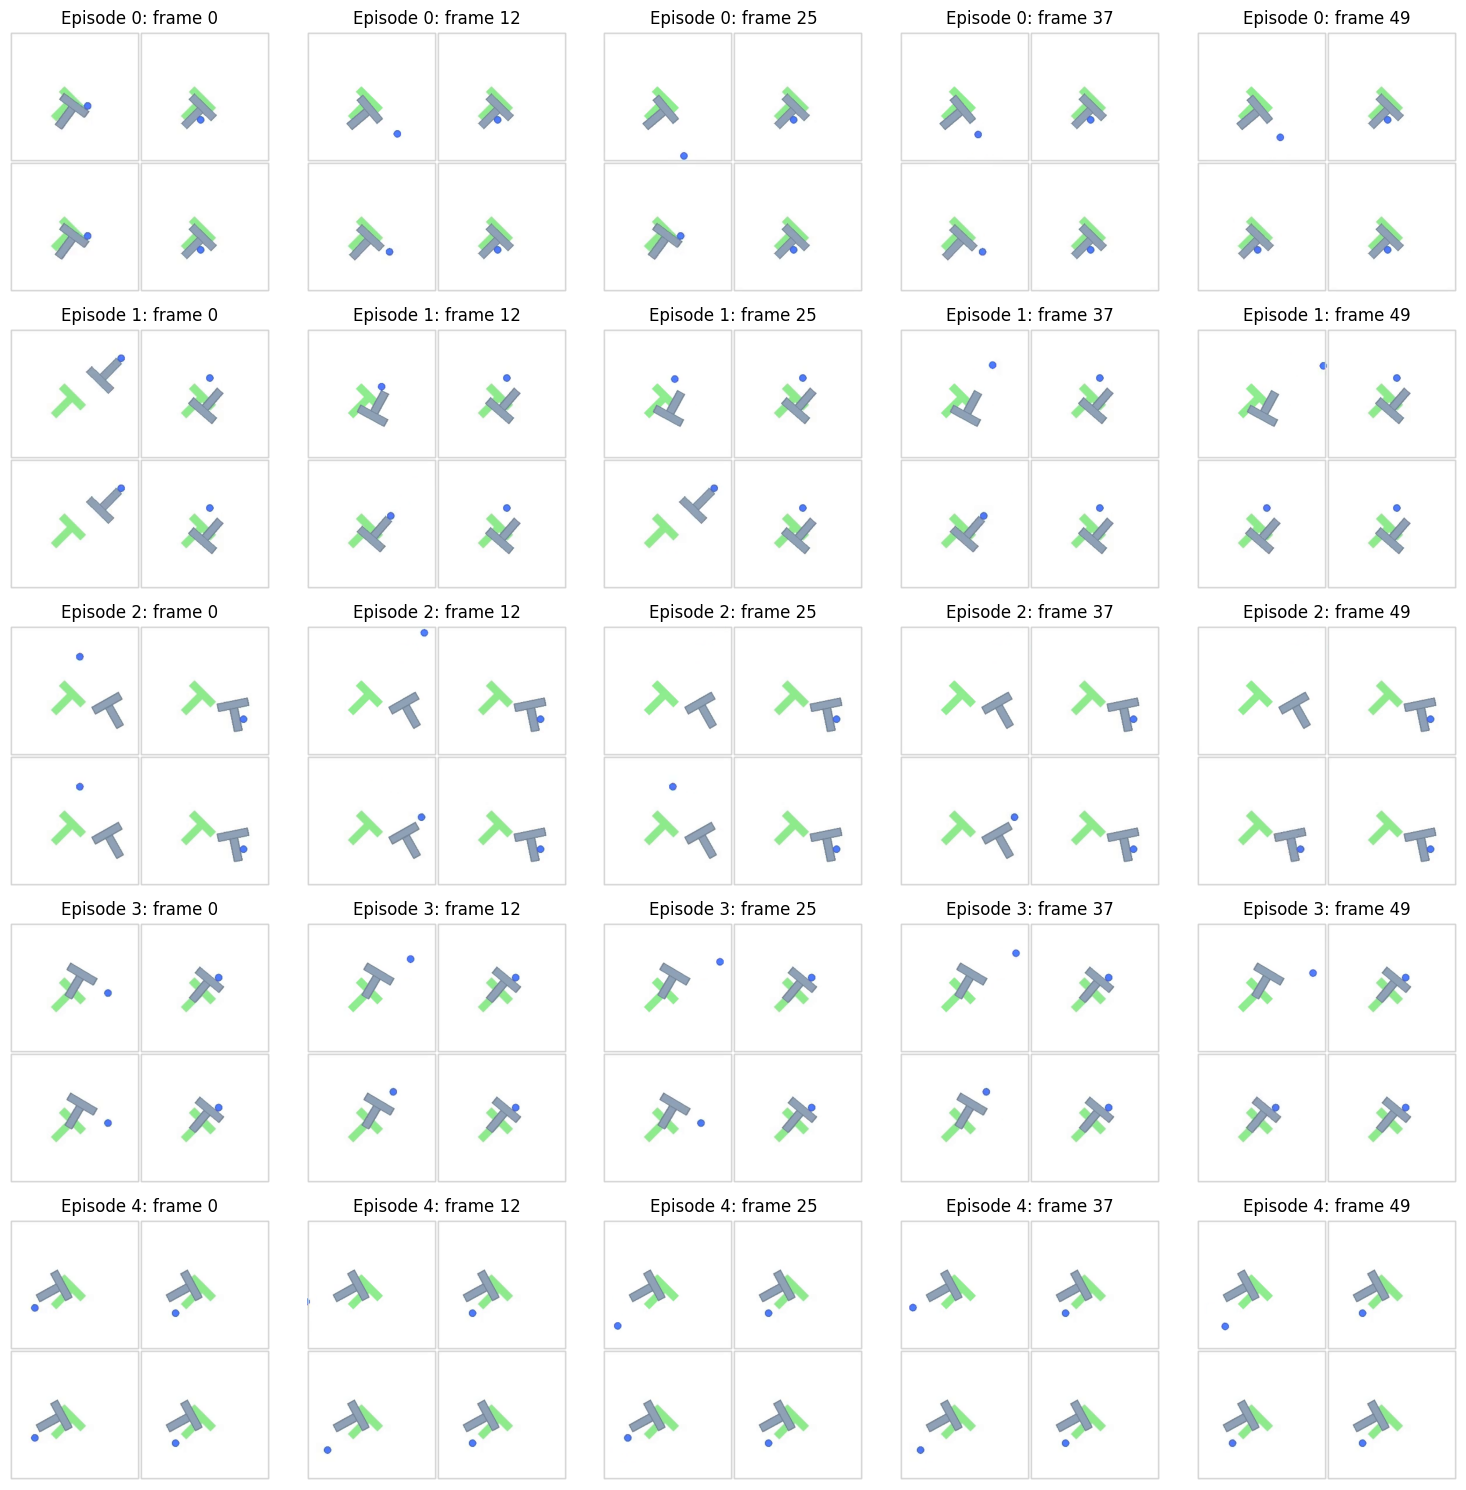

In [59]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import math

run_dir = Path(
    "/content/lf/stablewm_home/lossfunk_hierarchical_d25_budget50"
)
videos = sorted(run_dir.glob("rollout_*.mp4"))

if not videos:
    raise FileNotFoundError(f"No rollout videos found in {run_dir}")

fig, axes = plt.subplots(
    len(videos), 5,
    figsize=(15, 3 * len(videos)),
    squeeze=False
)

for row, video in enumerate(videos):
    cap = cv2.VideoCapture(str(video))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frame_ids = sorted(set(
        int(x) for x in
        [0, total * 0.25, total * 0.5, total * 0.75, max(0, total - 1)]
    ))

    for col, frame_id in enumerate(frame_ids):
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
        ok, frame = cap.read()
        ax = axes[row, col]
        ax.axis("off")
        if ok:
            ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            ax.set_title(f"Episode {row}: frame {frame_id}")
        else:
            ax.set_title("Frame unavailable")
    cap.release()

plt.tight_layout()
plt.show()


In [60]:

from pathlib import Path
import cv2
import numpy as np

run_dir = Path(
    "/content/lf/stablewm_home/lossfunk_hierarchical_d25_budget50"
)

for video in sorted(run_dir.glob("rollout_*.mp4")):
    cap = cv2.VideoCapture(str(video))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    print(f"\n{video.name}: {total} frames, {fps:.1f} FPS")

    # Print a few frames with their image dimensions.
    for frac in [0.0, 0.25, 0.5, 0.75, 1.0]:
        idx = min(total - 1, int(frac * (total - 1)))
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        if ok:
            print(
                f"  frame={idx:3d}, "
                f"shape={frame.shape}, "
                f"mean_pixel={frame.mean():.2f}, "
                f"std_pixel={frame.std():.2f}"
            )

    cap.release()



rollout_0.mp4: 50 frames, 15.0 FPS
  frame=  0, shape=(448, 448, 3), mean_pixel=248.65, std_pixel=22.00
  frame= 12, shape=(448, 448, 3), mean_pixel=248.59, std_pixel=22.10
  frame= 24, shape=(448, 448, 3), mean_pixel=248.64, std_pixel=22.01
  frame= 36, shape=(448, 448, 3), mean_pixel=248.60, std_pixel=22.10
  frame= 49, shape=(448, 448, 3), mean_pixel=248.65, std_pixel=22.02

rollout_1.mp4: 50 frames, 15.0 FPS
  frame=  0, shape=(448, 448, 3), mean_pixel=248.09, std_pixel=22.91
  frame= 12, shape=(448, 448, 3), mean_pixel=248.35, std_pixel=22.56
  frame= 24, shape=(448, 448, 3), mean_pixel=248.35, std_pixel=22.56
  frame= 36, shape=(448, 448, 3), mean_pixel=248.36, std_pixel=22.53
  frame= 49, shape=(448, 448, 3), mean_pixel=248.36, std_pixel=22.52

rollout_2.mp4: 50 frames, 15.0 FPS
  frame=  0, shape=(448, 448, 3), mean_pixel=247.62, std_pixel=23.88
  frame= 12, shape=(448, 448, 3), mean_pixel=247.65, std_pixel=23.85
  frame= 24, shape=(448, 448, 3), mean_pixel=247.74, std_pixel=2

In [65]:

from pathlib import Path
import ast

p = Path("/content/lf/src/Hi-LeWM/scripts/hi_acting_diagnostics.py")
src = p.read_text(errors="replace")
tree = ast.parse(src)

print("===== DIAGNOSTIC CONFIG FIELDS =====")
for node in ast.walk(tree):
    if isinstance(node, ast.ClassDef) and node.name == "ActingDiagnosticConfig":
        for item in node.body:
            if isinstance(item, ast.AnnAssign) and isinstance(item.target, ast.Name):
                name = item.target.id
                value = ast.get_source_segment(src, item.value) if item.value else None
                print(f"{name} = {value}")

print("\n===== RESULT SAVING HELPER =====")
lines = src.splitlines()
for i, line in enumerate(lines):
    if line.startswith("def finalize_result"):
        for j in range(i, min(i + 55, len(lines))):
            print(f"{j+1:4}: {lines[j]}")
        break

print("\n===== MODEL / CHECKPOINT LOADING =====")
for i, line in enumerate(lines):
    if "AutoCostModel" in line or "load_model" in line or "load_checkpoint" in line:
        print(f"{i+1:4}: {line}")


===== DIAGNOSTIC CONFIG FIELDS =====
policy = None
experiment_kind = None
dataset_name = "pusht_expert_train"
eval_config = "config/eval/hi_pusht.yaml"
cache_dir = None
img_size = 224
num_eval = 50
goal_offset_steps = 50
eval_budget = 50
high_horizon = 2
low_horizon = 2
low_receding_horizon = 1
high_num_samples = 1500
high_iters = 40
high_topk = 10
low_num_samples = 900
low_iters = 20
low_topk = 150
frame_skip = 5
seed = 42
device = "auto"
subgoal_offsets = (2, 3, 5)
num_reference_samples = 4096
save_json = None
save_npz = None
append_tsv = None

===== RESULT SAVING HELPER =====
 157: def finalize_result(
 158:     ctx: ActingContext,
 159:     result: dict[str, Any],
 160:     *,
 161:     tsv_columns: Sequence[str],
 162:     tsv_row: dict[str, Any],
 163:     npz_arrays: dict[str, Any] | None = None,
 164: ) -> dict[str, Any]:
 165:     write_json(ctx.cfg.save_json, result)
 166:     append_tsv(ctx.cfg.append_tsv, tsv_columns, tsv_row)
 167:     if npz_arrays:
 168:         maybe_sa

In [57]:

from pathlib import Path

world_file = Path(
    "/content/lf/venv/lib/python3.10/site-packages/stable_worldmodel/world.py"
)
policy_file = Path("/content/lf/src/Hi-LeWM/hi_policy.py")

def show_lines(path, start, end):
    lines = path.read_text(errors="replace").splitlines()
    print(f"\n===== {path.name}: lines {start}-{end} =====")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1:4}: {lines[i]}")

# How environment steps obtain and apply actions.
world_lines = world_file.read_text(errors="replace").splitlines()
step_defs = [
    i for i, line in enumerate(world_lines)
    if line.lstrip().startswith("def step(")
]
print("World.step definitions:", [i + 1 for i in step_defs])
for i in step_defs:
    show_lines(world_file, i + 1, min(i + 85, len(world_lines)))

# Standard hierarchical policy's action-buffer and planning logic.
policy_lines = policy_file.read_text(errors="replace").splitlines()
for start, end in [(820, 910), (910, 970)]:
    show_lines(policy_file, start, end)


World.step definitions: [178]

===== world.py: lines 178-262 =====
 178:     def step(self) -> None:
 179:         """Advance all environments by one step using the current policy."""
 180:         # note: reset happens before because of auto-reset, should fix that
 181:         if self.policy is None:
 182:             raise RuntimeError('No policy set. Call set_policy() first.')
 183: 
 184:         actions = self.policy.get_action(self.infos)
 185:         (
 186:             self.states,
 187:             self.rewards,
 188:             self.terminateds,
 189:             self.truncateds,
 190:             self.infos,
 191:         ) = self.envs.step(actions)
 192: 
 193:     def reset(
 194:         self,
 195:         seed: int | list[int] | None = None,
 196:         options: dict | None = None,
 197:     ) -> None:
 198:         """Reset all environments to initial states.
 199: 
 200:         Args:
 201:             seed: Random seed(s) for the environments.
 202:             

In [67]:

from pathlib import Path

repo = Path("/content/lf/src/Hi-LeWM")
scripts_dir = repo / "scripts"

print("Repository exists:", repo.exists())
print("Scripts directory exists:", scripts_dir.exists())
print("hi_diagnostics.py exists:", (scripts_dir / "hi_diagnostics.py").exists())
print("Related files:")
for p in sorted(scripts_dir.glob("*diagnostic*")):
    print(" ", p.name)


Repository exists: True
Scripts directory exists: True
hi_diagnostics.py exists: True
Related files:
  hi_acting_diagnostics.py
  hi_diagnostics.py
  render_hi_decoder_diagnostic_stories.py
  render_hi_paper_diagnostics.py
  run_hi_acting_diagnostic.py
  run_hi_diagnostic.py


In [68]:

from pathlib import Path
import os
import subprocess

repo = Path("/content/lf/src/Hi-LeWM")
runner = Path("/content/lf/run_hi_diagnostic.py")

source = runner.read_text()

old = 'sys.path.insert(0, str(repo))'
new = 'sys.path.insert(0, str(repo / "scripts"))\nsys.path.insert(0, str(repo))'

if old in source and 'str(repo / "scripts")' not in source:
    source = source.replace(old, new, 1)
    runner.write_text(source)

env = os.environ.copy()
env["STABLEWM_HOME"] = "/content/lf/stablewm_home"
env["MPLBACKEND"] = "Agg"

result = subprocess.run(
    ["/content/lf/venv/bin/python", str(runner)],
    cwd=str(repo),
    env=env,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    timeout=1800,
)

print("Exit code:", result.returncode)
print(result.stdout[-20000:])

out_dir = Path(
    "/content/drive/MyDrive/lossfunk_autoresearch/artifacts/hi_diagnostic_d25"
)
print("\nArtifacts:")
for p in sorted(out_dir.glob("*")):
    print(p.name, f"{p.stat().st_size / 1024:.1f} KB")


Exit code: 0
run_name": "hi_lewm",
  "checkpoint_epoch": null,
  "policy": "hi_lewm",
  "dataset_name": "pusht_expert_train",
  "experiment_kind": "online_hierarchical_logging",
  "device": "cuda",
  "seed": 42,
  "goal_offset_steps": 25,
  "eval_budget": 50,
  "num_eval": 3,
  "goal_tokens": 5,
  "high_horizon": 2,
  "low_horizon": 5,
  "low_receding_horizon": 1,
  "latent_action_dim": 32,
  "macro_input_dim": 10,
  "low_action_input_dim": 10,
  "raw_action_dim": 2,
  "group_factor": 5,
  "result_status": "ok",
  "success_rate": 33.33333333333333,
  "episode_successes": [
    false,
    false,
    true
  ],
  "high_plan_events": [
    {
      "high_plan_id": 0,
      "step": 0,
      "subgoal_mean_norm": 12.885086059570312,
      "subgoal_churn_mse": null,
      "selected_macro_summary": {
        "mean_norm": 7.697934627532959,
        "std_norm": 0.8814343810081482,
        "mahalanobis": {
          "p5": 188503.375,
          "p50": 370863.03125,
          "p95": 385982.03125
    

In [69]:

import json
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/lossfunk_autoresearch/artifacts/"
    "hi_diagnostic_d25/online_hierarchical.json"
)
r = json.loads(p.read_text())

print("Successes:", r.get("episode_successes"))
print("Success rate:", r.get("success_rate"))
print("Final terminal latent error:", r.get("final_terminal_latent_error_mean"))
print("Mean current-to-subgoal distance:", r.get("mean_distance_current_to_subgoal"))
print("Mean current-to-final-goal distance:", r.get("mean_distance_current_to_final_goal"))
print("Mean subgoal churn MSE:", r.get("mean_subgoal_churn_mse"))
print("Mean signed reality gap:", r.get("mean_reality_gap"))

print("\nHigh-level replanning events:", len(r.get("high_plan_events", [])))
print("Low-level action blocks:", len(r.get("low_block_events", [])))

print("\nPer-block prediction errors:")
for e in r.get("low_block_events", []):
    print(
        "step", e.get("block_end_step"),
        "| model error:", round(e.get("model_error_mean", float("nan")), 4),
        "| actual error:", round(e.get("actual_error_mean", float("nan")), 4),
        "| reality gap:", round(e.get("reality_gap_mean", float("nan")), 4),
    )


Successes: [False, False, True]
Success rate: 33.33333333333333
Final terminal latent error: 0.9969856142997742
Mean current-to-subgoal distance: 0.3029119685292244
Mean current-to-final-goal distance: 1.9297214245796204
Mean subgoal churn MSE: 0.14394860963026682
Mean signed reality gap: 0.014789995504543185

High-level replanning events: 10
Low-level action blocks: 10

Per-block prediction errors:
step 5 | model error: 0.2893 | actual error: 0.3322 | reality gap: 0.0429
step 10 | model error: 0.3698 | actual error: 0.3595 | reality gap: -0.0103
step 15 | model error: 0.2676 | actual error: 0.2855 | reality gap: 0.0179
step 20 | model error: 0.1543 | actual error: 0.1625 | reality gap: 0.0082
step 25 | model error: 0.4101 | actual error: 0.4349 | reality gap: 0.0248
step 30 | model error: 0.1532 | actual error: 0.1979 | reality gap: 0.0447
step 35 | model error: 0.4023 | actual error: 0.4068 | reality gap: 0.0046
step 40 | model error: 0.2046 | actual error: 0.2107 | reality gap: 0.00

In [71]:

import numpy as np
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/lossfunk_autoresearch/artifacts/"
    "hi_diagnostic_d25/online_hierarchical.npz"
)

with np.load(p, allow_pickle=False) as z:
    print("=== ARRAY SHAPES ===")
    for k in z.files:
        a = z[k]
        print(f"{k:32s} shape={str(a.shape):20s} dtype={a.dtype}")

    print("\n=== EPISODE IDENTIFIERS ===")
    for k in ("sampled_indices", "episodes_idx", "start_steps", "episode_successes"):
        if k in z.files:
            print(k, "=", z[k].tolist())

    print("\n=== TRACE STEP COUNTS ===")
    for k in ("step_current_latents", "step_subgoal_latents", "step_high_plan_ids"):
        if k in z.files:
            print(k, "first dimension =", z[k].shape[0])


=== ARRAY SHAPES ===
sampled_indices                  shape=(3,)                 dtype=int64
episodes_idx                     shape=(3,)                 dtype=int64
start_steps                      shape=(3,)                 dtype=int64
episode_successes                shape=(3,)                 dtype=bool
future_latents                   shape=(3, 25, 192)         dtype=float32
start_latent                     shape=(3, 192)             dtype=float32
goal_latent                      shape=(3, 192)             dtype=float32
final_latent                     shape=(3, 192)             dtype=float32
high_plan_steps                  shape=(10,)                dtype=int64
high_plan_current_latents        shape=(10, 3, 192)         dtype=float32
high_plan_goal_latents           shape=(10, 3, 192)         dtype=float32
high_plan_subgoal_latents        shape=(10, 3, 192)         dtype=float32
low_block_end_steps              shape=(10,)                dtype=int64
low_block_high_plan_ids       

In [72]:

import numpy as np
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/lossfunk_autoresearch/artifacts/"
    "hi_diagnostic_d25/online_hierarchical.npz"
)

with np.load(p, allow_pickle=False) as z:
    episodes = z["episodes_idx"]
    starts = z["start_latent"]
    goals = z["goal_latent"]
    finals = z["final_latent"]
    current = z["step_current_latents"]
    subgoals = z["step_subgoal_latents"]
    successes = z["episode_successes"]

    # Match the diagnostic's latent MSE convention.
    def latent_mse(a, b):
        return np.mean((a - b) ** 2, axis=-1)

    print("=== PER-EPISODE FINAL-GOAL ERRORS ===")
    for i, ep in enumerate(episodes):
        initial_err = float(latent_mse(starts[i], goals[i]))
        final_err = float(latent_mse(finals[i], goals[i]))
        print(
            f"episode={int(ep)} success={bool(successes[i])} "
            f"initial_mse={initial_err:.4f} "
            f"final_mse={final_err:.4f} "
            f"change={final_err-initial_err:+.4f}"
        )

    print("\n=== FINAL-GOAL ERROR THROUGH THE ROLLOUT ===")
    for t in (0, 4, 9, 14, 19, 24, 29, 34, 39, 44, 49):
        errors = latent_mse(current[t], goals)
        print(
            f"step={t+1:2d} "
            + " | ".join(
                f"ep{int(episodes[i])}:{errors[i]:.4f}"
                for i in range(len(episodes))
            )
        )

    print("\n=== CURRENT-TO-SUBGOAL MSE AT LAST STEP ===")
    last = latent_mse(current[-1], subgoals[-1])
    print({
        int(episodes[i]): round(float(last[i]), 4)
        for i in range(len(episodes))
    })


=== PER-EPISODE FINAL-GOAL ERRORS ===
episode=1694 success=False initial_mse=1.5294 final_mse=1.2821 change=-0.2473
episode=12221 success=False initial_mse=1.5615 final_mse=1.5228 change=-0.0387
episode=14327 success=True initial_mse=0.1063 final_mse=0.1861 change=+0.0798

=== FINAL-GOAL ERROR THROUGH THE ROLLOUT ===
step= 1 ep1694:1.4317 | ep12221:1.5287 | ep14327:0.1251
step= 5 ep1694:1.4588 | ep12221:1.5447 | ep14327:0.2152
step=10 ep1694:1.5037 | ep12221:1.4903 | ep14327:0.2138
step=15 ep1694:1.5575 | ep12221:1.5846 | ep14327:0.2650
step=20 ep1694:1.4278 | ep12221:1.4843 | ep14327:0.1723
step=25 ep1694:1.4114 | ep12221:1.6317 | ep14327:0.0770
step=30 ep1694:1.4208 | ep12221:1.7257 | ep14327:0.0767
step=35 ep1694:1.4538 | ep12221:1.6285 | ep14327:0.1286
step=40 ep1694:1.4238 | ep12221:1.4792 | ep14327:0.0123
step=45 ep1694:0.6298 | ep12221:1.6193 | ep14327:0.1258
step=50 ep1694:1.2821 | ep12221:1.5228 | ep14327:0.1861

=== CURRENT-TO-SUBGOAL MSE AT LAST STEP ===
{1694: 0.9027, 12221

In [73]:

import numpy as np
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/lossfunk_autoresearch/artifacts/"
    "hi_diagnostic_d25/online_hierarchical.npz"
)

with np.load(p, allow_pickle=False) as z:
    episodes = z["episodes_idx"]
    goals = z["goal_latent"]
    current = z["step_current_latents"]
    subgoals = z["step_subgoal_latents"]
    plan_ids = z["step_high_plan_ids"]
    successes = z["episode_successes"]

    def mse(a, b):
        return np.mean((a - b) ** 2, axis=-1)

    print("episode | success | avg_subgoal_mse | avg_goal_mse | first_goal_mse | last_goal_mse")
    for i, ep in enumerate(episodes):
        sg = mse(current[:, i, :], subgoals[:, i, :])
        gd = mse(current[:, i, :], goals[i])
        print(
            f"{int(ep)} | {bool(successes[i])} | "
            f"{sg.mean():.4f} | {gd.mean():.4f} | "
            f"{gd[0]:.4f} | {gd[-1]:.4f}"
        )

    print("\nSubgoal changes per episode:")
    for i, ep in enumerate(episodes):
        changes = np.where(np.diff(plan_ids) != 0)[0] + 1
        print(f"episode {int(ep)}: shared plan-change steps = {changes.tolist()}")


episode | success | avg_subgoal_mse | avg_goal_mse | first_goal_mse | last_goal_mse
1694 | False | 0.4854 | 1.3609 | 1.4317 | 1.2821
12221 | False | 0.2936 | 1.5775 | 1.5287 | 1.5228
14327 | True | 0.1298 | 0.1489 | 0.1251 | 0.1861

Subgoal changes per episode:
episode 1694: shared plan-change steps = [5, 10, 15, 20, 25, 30, 35, 40, 45]
episode 12221: shared plan-change steps = [5, 10, 15, 20, 25, 30, 35, 40, 45]
episode 14327: shared plan-change steps = [5, 10, 15, 20, 25, 30, 35, 40, 45]


In [74]:

from pathlib import Path
import json
import pandas as pd

root = Path("/content/drive/MyDrive/lossfunk_autoresearch/artifacts")

print("=== RESULT FILES ===")
files = sorted(
    p for p in root.rglob("*")
    if p.is_file() and p.suffix.lower() in {".csv", ".tsv", ".json"}
)
for p in files:
    print(p.relative_to(root), f"({p.stat().st_size:,} bytes)")

print("\n=== TABULAR RESULTS ===")
for p in files:
    if p.suffix.lower() not in {".csv", ".tsv"}:
        continue
    try:
        df = pd.read_csv(p, sep="\t" if p.suffix.lower() == ".tsv" else ",")
        print(f"\n--- {p.relative_to(root)} ---")
        print("shape:", df.shape)
        print(df.head(8).to_string(index=False))
    except Exception as e:
        print("Could not read", p.name, repr(e))

print("\n=== JSON SUMMARY FIELDS ===")
for p in files:
    if p.suffix.lower() != ".json":
        continue
    try:
        obj = json.loads(p.read_text())
        if isinstance(obj, dict):
            fields = {
                k: obj[k] for k in obj
                if any(term in k.lower() for term in
                       ("success", "horizon", "seed", "budget", "compute",
                        "token", "policy", "mode", "status", "episode"))
                and not isinstance(obj[k], (dict, list))
            }
            if fields:
                print(f"\n--- {p.relative_to(root)} ---")
                print(fields)
    except Exception as e:
        print("Could not read", p.name, repr(e))


=== RESULT FILES ===
baseline_validation.csv (576 bytes)
baseline_verdict.json (190 bytes)
data_ckpt_provenance.json (539 bytes)
hi_diagnostic_d25/online_hierarchical.json (20,004 bytes)
hi_diagnostic_d25/online_hierarchical.tsv (422 bytes)
hi_eval_d25_budget50/hi_pusht_results_episodes.tsv (502 bytes)
key_map.json (1,914 bytes)
repo_commits.json (336 bytes)
runtime_report.json (310 bytes)
smoke/instr/metrics_raw.json (112 bytes)
smoke/instr/patch_report.json (1,077 bytes)
smoke/instr/summary.json (1,958 bytes)
smoke/overrides.json (510 bytes)
smoke/run_result.json (3,694 bytes)

=== TABULAR RESULTS ===

--- baseline_validation.csv ---
shape: (12, 10)
 d   seed  n  k     rate  provenance  wilson_lo  wilson_hi  published consistent
25     42  5  4 0.800000 per-episode        NaN        NaN        NaN        NaN
25     43  5  5 1.000000 per-episode        NaN        NaN        NaN        NaN
25     44  5  4 0.800000 per-episode        NaN        NaN        NaN        NaN
25 pooled 15 13 

In [75]:

from pathlib import Path
import json

root = Path("/content/drive/MyDrive/lossfunk_autoresearch")

print("=== BASELINE-RELATED FILES ===")
for p in sorted(root.rglob("*")):
    if p.is_file() and any(
        word in p.name.lower()
        for word in ("flat", "baseline", "episode", "planning", "trace", "compute")
    ):
        print(p.relative_to(root), f"{p.stat().st_size:,} bytes")

print("\n=== BASELINE VALIDATION JSON/CSV METADATA ===")
for name in ("baseline_verdict.json", "baseline_validation.csv"):
    p = root / "artifacts" / name
    if p.exists():
        print(f"\n--- {name} ---")
        print(p.read_text()[:12000])


=== BASELINE-RELATED FILES ===
artifacts/BASELINE_INSTRUMENTATION.md 21,995 bytes
artifacts/BASELINE_PROTOCOL.md 8,385 bytes
artifacts/baseline_validation.csv 576 bytes
artifacts/baseline_verdict.json 190 bytes
artifacts/hi_eval_d25_budget50/hi_pusht_results_episodes.tsv 502 bytes
artifacts/smoke/instr/trace.jsonl 57,144 bytes
runs/flat_rh_pub__d25__s42/instr/trace.jsonl 282,352 bytes
runs/flat_rh_pub__d25__s43/instr/trace.jsonl 282,445 bytes
runs/flat_rh_pub__d25__s44/instr/trace.jsonl 282,382 bytes
runs/flat_rh_pub__d50__s42/instr/trace.jsonl 313,981 bytes
runs/flat_rh_pub__d50__s43/instr/trace.jsonl 313,925 bytes
runs/flat_rh_pub__d50__s44/instr/trace.jsonl 313,812 bytes
runs/flat_rh_pub__d75__s42/instr/trace.jsonl 313,855 bytes
runs/flat_rh_pub__d75__s43/instr/trace.jsonl 313,859 bytes
runs/flat_rh_pub__d75__s44/instr/trace.jsonl 313,877 bytes

=== BASELINE VALIDATION JSON/CSV METADATA ===

--- baseline_verdict.json ---
{
 "all_consistent": true,
 "per_d": {
  "25": true,
  "50": t

In [76]:

from pathlib import Path
import json
from collections import Counter

root = Path("/content/drive/MyDrive/lossfunk_autoresearch/runs")

for d in (25, 50, 75):
    p = root / f"flat_rh_pub__d{d}__s42" / "instr" / "trace.jsonl"
    print(f"\n{'='*20} HORIZON {d} {'='*20}")

    if not p.exists():
        print("Missing:", p)
        continue

    rows = []
    with p.open() as f:
        for line in f:
            line = line.strip()
            if line:
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    pass

    print("Valid JSON records:", len(rows))
    if not rows:
        continue

    print("First record:")
    print(json.dumps(rows[0], indent=2)[:4000])

    keys = Counter(k for row in rows for k in row)
    print("\nField occurrence counts:")
    for k, count in keys.most_common():
        if any(s in k.lower() for s in (
            "episode", "seed", "step", "candidate", "planner",
            "world", "model", "predict", "token", "time",
            "success", "compute", "call", "eval"
        )):
            print(f"{k}: {count}/{len(rows)}")



==================== HORIZON 25 ====================
Valid JSON records: 2700
First record:
{
  "t": 37.7195,
  "cls": "JEPA",
  "fn": "encode",
  "lvl": "low",
  "solve": 0,
  "examples": 1,
  "dt_ms": null
}

Field occurrence counts:

==================== HORIZON 50 ====================
Valid JSON records: 3000
First record:
{
  "t": 39.8885,
  "cls": "JEPA",
  "fn": "encode",
  "lvl": "low",
  "solve": 0,
  "examples": 1,
  "dt_ms": null
}

Field occurrence counts:

==================== HORIZON 75 ====================
Valid JSON records: 3000
First record:
{
  "t": 37.3001,
  "cls": "JEPA",
  "fn": "encode",
  "lvl": "low",
  "solve": 0,
  "examples": 1,
  "dt_ms": null
}

Field occurrence counts:


In [77]:

from pathlib import Path
import json
from collections import Counter, defaultdict

root = Path("/content/drive/MyDrive/lossfunk_autoresearch/runs")

for d in (25, 50, 75):
    p = root / f"flat_rh_pub__d{d}__s42" / "instr" / "trace.jsonl"
    rows = [json.loads(line) for line in p.read_text().splitlines() if line.strip()]

    print(f"\n{'='*16} HORIZON {d} {'='*16}")
    for field in ("cls", "fn", "lvl"):
        print(f"\n{field} counts:")
        for key, n in Counter(str(r.get(field)) for r in rows).most_common():
            print(f"  {key}: {n}")

    solves = Counter(str(r.get("solve")) for r in rows)
    print("\nDistinct solve IDs:", len(solves))
    print("Records per solve ID:", dict(Counter(solves.values())))

    times = [r.get("dt_ms") for r in rows if r.get("dt_ms") is not None]
    print("Populated dt_ms:", len(times), "/", len(rows))
    if times:
        print("Sum dt_ms:", sum(float(x) for x in times))



================ HORIZON 25 ================

cls counts:
  JEPA: 2700

fn counts:
  predict: 1500
  encode: 600
  rollout: 300
  get_cost: 300

lvl counts:
  low: 2700

Distinct solve IDs: 2
Records per solve ID: {1350: 2}
Populated dt_ms: 0 / 2700

================ HORIZON 50 ================

cls counts:
  JEPA: 3000

fn counts:
  predict: 1666
  encode: 668
  rollout: 333
  get_cost: 333

lvl counts:
  low: 3000

Distinct solve IDs: 3
Records per solve ID: {1350: 2, 300: 1}
Populated dt_ms: 0 / 3000

================ HORIZON 75 ================

cls counts:
  JEPA: 3000

fn counts:
  predict: 1666
  encode: 668
  rollout: 333
  get_cost: 333

lvl counts:
  low: 3000

Distinct solve IDs: 3
Records per solve ID: {1350: 2, 300: 1}
Populated dt_ms: 0 / 3000


In [78]:

from pathlib import Path

p = Path(
    "/content/drive/MyDrive/lossfunk_autoresearch/"
    "artifacts/BASELINE_INSTRUMENTATION.md"
)
text = p.read_text()
lines = text.splitlines()

terms = (
    "solve", "predict", "rollout", "encode", "get_cost",
    "candidate", "forward", "compute", "count", "token",
)

hits = [
    i for i, line in enumerate(lines)
    if any(term in line.lower() for term in terms)
]

shown = set()
for i in hits:
    start, end = max(0, i - 2), min(len(lines), i + 4)
    if any(j in shown for j in range(start, end)):
        continue
    shown.update(range(start, end))
    print(f"\n--- lines {start+1}-{end} ---")
    for j in range(start, end):
        print(f"{j+1}: {lines[j]}")



--- lines 3-8 ---
3: ## Scope and evidence labels
4: 
5: This is instrumentation preparation, not baseline reproduction. **Source verified** means checked in source or the installed dependency source. **Runtime verified** means observed in the one synthetic smoke decision described below. **Inferred** means directly deduced from source/config, but not measured in a real environment rollout. **Unknown** means this stage did not establish it.
6: 
7: No source file in either upstream repository was edited. The code added under `research/instrumentation/` uses reversible Python wrappers around policy, CEM, world-model, and environment-step call boundaries. Original call arguments and returned values are forwarded unchanged. It does not alter model weights, candidate tensors, objectives, solver settings, selected actions, or environment physics. Instrumentation has I/O and timing overhead; recorded durations are instrumented timings and must not be used as benchmark latency without separat

In [79]:

from pathlib import Path
import json
from collections import Counter

root = Path("/content/drive/MyDrive/lossfunk_autoresearch/runs")

for d in (25, 50, 75):
    p = root / f"flat_rh_pub__d{d}__s42" / "instr" / "trace.jsonl"
    rows = [json.loads(x) for x in p.read_text().splitlines() if x.strip()]

    print(f"\n=== HORIZON {d}, SEED 42 ===")
    for event in ("cem_solve", "world_model_get_cost", "policy_decision",
                  "environment_step", "environment_transition"):
        matches = [r for r in rows if r.get("event") == event or r.get("kind") == event]
        print(f"{event}: {len(matches)} records")
        if matches:
            print("  fields:", sorted(matches[0].keys()))
            print("  example:", {
                k: v for k, v in matches[0].items()
                if any(s in k.lower() for s in
                       ("candidate", "cost", "sample", "step", "horizon", "elapsed", "duration"))
            })

    print("Top-level event labels:", Counter(
        r.get("event", r.get("kind", "<no event field>")) for r in rows
    ).most_common(12))



=== HORIZON 25, SEED 42 ===
cem_solve: 0 records
world_model_get_cost: 0 records
policy_decision: 0 records
environment_step: 0 records
environment_transition: 0 records
Top-level event labels: [('<no event field>', 2700)]

=== HORIZON 50, SEED 42 ===
cem_solve: 0 records
world_model_get_cost: 0 records
policy_decision: 0 records
environment_step: 0 records
environment_transition: 0 records
Top-level event labels: [('<no event field>', 3000)]

=== HORIZON 75, SEED 42 ===
cem_solve: 0 records
world_model_get_cost: 0 records
policy_decision: 0 records
environment_step: 0 records
environment_transition: 0 records
Top-level event labels: [('<no event field>', 3000)]


In [80]:

from pathlib import Path
import json
from collections import Counter, defaultdict

root = Path("/content/drive/MyDrive/lossfunk_autoresearch/runs")

for d in (25, 50, 75):
    p = root / f"flat_rh_pub__d{d}__s42" / "instr" / "trace.jsonl"
    rows = [json.loads(x) for x in p.read_text().splitlines() if x.strip()]

    print(f"\n{'='*12} HORIZON {d} {'='*12}")
    by_fn = defaultdict(list)
    for r in rows:
        by_fn[r.get("fn", "<missing>")].append(r)

    for fn in ("get_cost", "rollout", "predict", "encode"):
        group = by_fn.get(fn, [])
        print(f"\n{fn}: {len(group)} records")
        for r in group[:2]:
            print(json.dumps(r, indent=2))

    print("\nExamples values by function:")
    for fn, group in sorted(by_fn.items()):
        print(fn, Counter(str(r.get("examples")) for r in group))

    print("\nSolve IDs by function:")
    for fn, group in sorted(by_fn.items()):
        print(fn, Counter(str(r.get("solve")) for r in group))



============ HORIZON 25 ============

get_cost: 300 records
{
  "t": 37.9145,
  "cls": "JEPA",
  "fn": "get_cost",
  "lvl": "low",
  "solve": 0,
  "examples": 300,
  "dt_ms": null
}
{
  "t": 38.3356,
  "cls": "JEPA",
  "fn": "get_cost",
  "lvl": "low",
  "solve": 0,
  "examples": 300,
  "dt_ms": null
}

rollout: 300 records
{
  "t": 37.8148,
  "cls": "JEPA",
  "fn": "rollout",
  "lvl": "low",
  "solve": 0,
  "examples": 0,
  "dt_ms": null
}
{
  "t": 38.3355,
  "cls": "JEPA",
  "fn": "rollout",
  "lvl": "low",
  "solve": 0,
  "examples": 0,
  "dt_ms": null
}

predict: 1500 records
{
  "t": 37.7709,
  "cls": "JEPA",
  "fn": "predict",
  "lvl": "low",
  "solve": 0,
  "examples": 300,
  "dt_ms": null
}
{
  "t": 37.7946,
  "cls": "JEPA",
  "fn": "predict",
  "lvl": "low",
  "solve": 0,
  "examples": 300,
  "dt_ms": null
}

encode: 600 records
{
  "t": 37.7195,
  "cls": "JEPA",
  "fn": "encode",
  "lvl": "low",
  "solve": 0,
  "examples": 1,
  "dt_ms": null
}
{
  "t": 37.7447,
  "cls": "JEP

In [84]:

from pathlib import Path

p = Path("/content/lf/src/Hi-LeWM/hi_jepa.py")
lines = p.read_text(errors="replace").splitlines()

for start, end in [(430, 550)]:
    print(f"===== hi_jepa.py lines {start}-{end} =====")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")


===== hi_jepa.py lines 430-550 =====
430:             z_ctx = z_seq[:, -ctx:]
431:             a_ctx = act_emb[:, -ctx:]
432:             z_next = self.predict_low(z_ctx, a_ctx)[:, -1:, :]
433:             z_seq = torch.cat([z_seq, z_next], dim=1)
434:             preds.append(z_next.squeeze(1))
435: 
436:         pred_seq = torch.stack(preds, dim=1).reshape(b, s, t, -1)
437:         return pred_seq
438: 
439:     @torch.inference_mode()
440:     def get_cost_high(self, info_dict: dict, action_candidates: torch.Tensor) -> torch.Tensor:
441:         """High-level latent-action planning cost E2."""
442:         if not torch.is_tensor(action_candidates):
443:             raise ValueError("action_candidates must be a torch.Tensor")
444:         if action_candidates.ndim != 4:
445:             raise ValueError(
446:                 "action_candidates must have shape (B, S, H, D_high)"
447:             )
448: 
449:         device = self._device()
450:         action_candidates = action_candi

In [87]:

from pathlib import Path
import yaml

repo = Path("/content/lf/src/Hi-LeWM")
cfg_path = repo / "config/eval/hi_pusht.yaml"

cfg = yaml.safe_load(cfg_path.read_text())
planning = cfg.get("planning", {})

for level in ("high", "low"):
    section = planning.get(level, {})
    solver = section.get("solver", {})
    plan = section.get("plan_config", {})

    print(f"\n===== {level.upper()} PLANNER =====")
    print("num_samples:", solver.get("num_samples"))
    print("n_steps:", solver.get("n_steps"))
    print("topk:", solver.get("topk"))
    print("plan_config:", plan)

print("\n===== OTHER PLANNING SETTINGS =====")
print("mode:", planning.get("mode"))
print("high replan interval:", planning.get("high", {}).get("replan_interval"))
print("high latent prior:", planning.get("high", {}).get("latent_prior"))
print("empirical macro config:", planning.get("high", {}).get("empirical_macro_action"))



===== HIGH PLANNER =====
num_samples: 900
n_steps: 20
topk: 30
plan_config: {'horizon': 2, 'receding_horizon': 1, 'action_block': 1}

===== LOW PLANNER =====
num_samples: 600
n_steps: 30
topk: 60
plan_config: {'horizon': 5, 'receding_horizon': 1, 'action_block': 5}

===== OTHER PLANNING SETTINGS =====
mode: hierarchical
high replan interval: 5
high latent prior: {'enabled': True, 'num_chunks': 2048, 'min_chunks_for_stats': 64, 'chunk_len': 5, 'lower_q': 5.0, 'upper_q': 95.0, 'margin_ratio': 0.05, 'clamp_abs': 3.0, 'fallback_abs': 1.0}
empirical macro config: None


In [91]:

import subprocess

python = "/content/lf/venv/bin/python"

checks = [
    "import sys; print('Python:', sys.executable); print('Version:', sys.version)",
    "import h5py; print('h5py:', h5py.__version__)",
    "import stable_worldmodel as swm; print('stable_worldmodel:', swm.__file__)",
]

for code in checks:
    print("\n>>>", code)
    result = subprocess.run(
        [python, "-c", code],
        capture_output=True,
        text=True,
        timeout=30,
    )
    print("Exit code:", result.returncode)
    if result.stdout:
        print(result.stdout)
    if result.stderr:
        print(result.stderr[-2500:])



>>> import sys; print('Python:', sys.executable); print('Version:', sys.version)
Exit code: 0
Python: /content/lf/venv/bin/python
Version: 3.10.22 (main, Oct  9 2026, 15:21:30) [Clang 22.1.3 ]


>>> import h5py; print('h5py:', h5py.__version__)
Exit code: 0
h5py: 3.16.0


>>> import stable_worldmodel as swm; print('stable_worldmodel:', swm.__file__)
Exit code: 0
stable_worldmodel: /content/lf/venv/lib/python3.10/site-packages/stable_worldmodel/__init__.py



In [94]:

import os
import subprocess

script = r'''
import sys
from pathlib import Path

repo = Path("/content/lf/src/Hi-LeWM")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "scripts"))

import baseline_adapter
sys.modules["module"] = baseline_adapter._load_baseline_module("module", "module.py")

from scripts.hi_acting_diagnostics import (
    ActingDiagnosticConfig,
    build_context,
    build_solvers_and_configs,
)

cfg = ActingDiagnosticConfig(
    policy="hi_lewm",
    experiment_kind="online_hierarchical_logging",
    dataset_name="pusht_expert_train",
    eval_config="config/eval/hi_pusht.yaml",
    num_eval=1,
    goal_offset_steps=25,
    eval_budget=10,
    high_horizon=2,
    low_horizon=5,
    high_num_samples=900,
    high_iters=20,
    high_topk=30,
    low_num_samples=600,
    low_iters=30,
    low_topk=60,
    frame_skip=5,
    seed=42,
    device="cuda",
)

ctx = build_context(cfg)
_, _, _, high_solver, low_solver = build_solvers_and_configs(ctx)

for name, solver in (("high", high_solver), ("low", low_solver)):
    print(f"\n{name.upper()} SOLVER")
    for attr in ("num_samples", "n_steps", "topk", "batch_size", "n_envs"):
        print(f"{attr}: {getattr(solver, attr, '<not set>')}")
'''

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["STABLEWM_HOME"] = "/content/lf/stablewm_home"

result = subprocess.run(
    ["/content/lf/venv/bin/python", "-c", script],
    cwd="/content/lf/src/Hi-LeWM",
    env=env,
    capture_output=True,
    text=True,
    timeout=180,
)

print("Exit code:", result.returncode)
print(result.stdout[-6000:])
if result.stderr:
    print("\nSTDERR:\n", result.stderr[-4000:])


Exit code: 0
19:22:47.942 | INFO    (43782, stable_pretraining) | Cached 'action' from '/content/lf/stablewm_home/pusht_expert_train.h5'
19:22:47.975 | INFO    (43782, stable_pretraining) | Cached 'proprio' from '/content/lf/stablewm_home/pusht_expert_train.h5'
19:22:48.023 | INFO    (43782, stable_pretraining) | Cached 'state' from '/content/lf/stablewm_home/pusht_expert_train.h5'
19:22:50.046 | INFO    (43782, stable_worldmodel.world) | 🌍🌍🌍 World swm/PushT-v1 initialized 🌍🌍🌍
19:22:50.046 | INFO    (43782, stable_worldmodel.world) | 🕹️ 🕹️ 🕹️ Action space 🕹️ 🕹️ 🕹️
19:22:50.047 | INFO    (43782, stable_worldmodel.world) | Box(-1.0, 1.0, (1, 2), float32)
19:22:50.047 | INFO    (43782, stable_worldmodel.world) | 👁️ 👁️ 👁️ Observation space 👁️ 👁️ 👁️
19:22:50.047 | INFO    (43782, stable_worldmodel.world) | Dict('proprio': Box(0.0, 512.0, (1, 4), float64), 'state': Box(0.0, [[512.         512.         512.         512.           6.28318531
  512.         512.        ]], (1, 7), float64))
19:

In [95]:

import os
import subprocess

script = r'''
import sys, json, time
from pathlib import Path
from collections import defaultdict

repo = Path("/content/lf/src/Hi-LeWM")
sys.path.insert(0, "/content/lf")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "scripts"))

import baseline_adapter
sys.modules["module"] = baseline_adapter._load_baseline_module("module", "module.py")

import scripts.hi_acting_diagnostics as diag
from scripts.hi_acting_diagnostics import ActingDiagnosticConfig

counts = defaultdict(lambda: {
    "solve_calls": 0,
    "configured_candidate_scores": 0,
    "elapsed_seconds": 0.0,
})

original_builder = diag.build_solvers_and_configs

def instrumented_builder(ctx):
    result = original_builder(ctx)
    high_solver, low_solver = result[-2], result[-1]

    for name, solver in (("high", high_solver), ("low", low_solver)):
        original_solve = solver.solve

        def wrapped_solve(*args, _name=name, _solver=solver,
                          _original=original_solve, **kwargs):
            start = time.perf_counter()
            counts[_name]["solve_calls"] += 1
            counts[_name]["configured_candidate_scores"] += (
                int(getattr(_solver, "num_samples", 0))
                * int(getattr(_solver, "n_steps", 0))
                * int(getattr(_solver, "batch_size", 1))
            )
            try:
                return _original(*args, **kwargs)
            finally:
                counts[_name]["elapsed_seconds"] += time.perf_counter() - start

        solver.solve = wrapped_solve

    return result

diag.build_solvers_and_configs = instrumented_builder

out = Path("/content/drive/MyDrive/lossfunk_autoresearch/artifacts")
out.mkdir(parents=True, exist_ok=True)

cfg = ActingDiagnosticConfig(
    policy="hi_lewm",
    experiment_kind="online_hierarchical_logging",
    dataset_name="pusht_expert_train",
    eval_config="config/eval/hi_pusht.yaml",
    num_eval=1,
    goal_offset_steps=25,
    eval_budget=10,
    high_horizon=2,
    low_horizon=5,
    high_num_samples=900,
    high_iters=20,
    high_topk=30,
    low_num_samples=600,
    low_iters=30,
    low_topk=60,
    frame_skip=5,
    seed=42,
    device="cuda",
    save_json=str(out / "hi_solver_usage_pilot.json"),
)

result = diag.run_acting_diagnostic(cfg)

summary = {
    "diagnostic": "10-step hierarchical solver-usage pilot",
    "solver_usage": {k: dict(v) for k, v in counts.items()},
}
(out / "hi_solver_usage_counts.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
'''

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["STABLEWM_HOME"] = "/content/lf/stablewm_home"

result = subprocess.run(
    ["/content/lf/venv/bin/python", "-c", script],
    cwd="/content/lf/src/Hi-LeWM",
    env=env,
    capture_output=True,
    text=True,
    timeout=300,
)

print("Exit code:", result.returncode)
print(result.stdout[-7000:])
if result.stderr:
    print("\nSTDERR:\n", result.stderr[-4000:])


Exit code: 0
19:23:55.019 | INFO    (44073, stable_pretraining) | Cached 'action' from '/content/lf/stablewm_home/pusht_expert_train.h5'
19:23:55.052 | INFO    (44073, stable_pretraining) | Cached 'proprio' from '/content/lf/stablewm_home/pusht_expert_train.h5'
19:23:55.097 | INFO    (44073, stable_pretraining) | Cached 'state' from '/content/lf/stablewm_home/pusht_expert_train.h5'
19:23:57.006 | INFO    (44073, stable_worldmodel.world) | 🌍🌍🌍 World swm/PushT-v1 initialized 🌍🌍🌍
19:23:57.006 | INFO    (44073, stable_worldmodel.world) | 🕹️ 🕹️ 🕹️ Action space 🕹️ 🕹️ 🕹️
19:23:57.007 | INFO    (44073, stable_worldmodel.world) | Box(-1.0, 1.0, (1, 2), float32)
19:23:57.007 | INFO    (44073, stable_worldmodel.world) | 👁️ 👁️ 👁️ Observation space 👁️ 👁️ 👁️
19:23:57.007 | INFO    (44073, stable_worldmodel.world) | Dict('proprio': Box(0.0, 512.0, (1, 4), float64), 'state': Box(0.0, [[512.         512.         512.         512.           6.28318531
  512.         512.        ]], (1, 7), float64))
19:

In [96]:

import os
import subprocess

script = r'''
import sys, json, time
from pathlib import Path
from collections import defaultdict

repo = Path("/content/lf/src/Hi-LeWM")
sys.path.insert(0, "/content/lf")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "scripts"))

import baseline_adapter
sys.modules["module"] = baseline_adapter._load_baseline_module("module", "module.py")

import scripts.hi_acting_diagnostics as diag
from scripts.hi_acting_diagnostics import ActingDiagnosticConfig

counts = defaultdict(lambda: {
    "get_cost_calls": 0,
    "actual_candidate_scores": 0,
    "candidate_tensor_shapes": [],
    "get_cost_seconds": 0.0,
})

original_builder = diag.build_solvers_and_configs
wrapped_model_ids = set()

def instrumented_builder(ctx):
    result = original_builder(ctx)
    high_solver, low_solver = result[-2], result[-1]

    for level, solver in (("high", high_solver), ("low", low_solver)):
        model = getattr(solver, "model", None)
        if model is None or not hasattr(model, "get_cost"):
            print(f"WARNING: no model.get_cost found for {level}")
            continue

        if id(model) in wrapped_model_ids:
            continue
        wrapped_model_ids.add(id(model))

        original_get_cost = model.get_cost

        def wrapped_get_cost(info_dict, candidates, *args,
                             _original=original_get_cost, **kwargs):
            info_level = info_dict.get("planner_level", "unknown")
            start = time.perf_counter()
            costs = _original(info_dict, candidates, *args, **kwargs)
            elapsed = time.perf_counter() - start

            key = str(info_level)
            counts[key]["get_cost_calls"] += 1
            counts[key]["actual_candidate_scores"] += int(costs.numel())
            counts[key]["candidate_tensor_shapes"].append(
                list(candidates.shape)
            )
            counts[key]["get_cost_seconds"] += elapsed
            return costs

        model.get_cost = wrapped_get_cost

    return result

diag.build_solvers_and_configs = instrumented_builder

out = Path("/content/drive/MyDrive/lossfunk_autoresearch/artifacts")
out.mkdir(parents=True, exist_ok=True)

cfg = ActingDiagnosticConfig(
    policy="hi_lewm",
    experiment_kind="online_hierarchical_logging",
    dataset_name="pusht_expert_train",
    eval_config="config/eval/hi_pusht.yaml",
    num_eval=1,
    goal_offset_steps=25,
    eval_budget=10,
    high_horizon=2,
    low_horizon=5,
    high_num_samples=900,
    high_iters=20,
    high_topk=30,
    low_num_samples=600,
    low_iters=30,
    low_topk=60,
    frame_skip=5,
    seed=42,
    device="cuda",
)

diag.run_acting_diagnostic(cfg)

summary = {
    "diagnostic": "10-step actual candidate-scoring pilot",
    "counts_by_planner_level": {k: dict(v) for k, v in counts.items()},
}
path = out / "hi_actual_candidate_scoring_pilot.json"
path.write_text(json.dumps(summary, indent=2))
print("Saved:", path)
print(json.dumps(summary, indent=2))
'''

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["STABLEWM_HOME"] = "/content/lf/stablewm_home"

result = subprocess.run(
    ["/content/lf/venv/bin/python", "-c", script],
    cwd="/content/lf/src/Hi-LeWM",
    env=env,
    capture_output=True,
    text=True,
    timeout=300,
)

print("Exit code:", result.returncode)
print(result.stdout[-7000:])
if result.stderr:
    print("\nSTDERR:\n", result.stderr[-4000:])


Exit code: 0
        ],
        [
          1,
          900,
          2,
          32
        ],
        [
          1,
          900,
          2,
          32
        ],
        [
          1,
          900,
          2,
          32
        ],
        [
          1,
          900,
          2,
          32
        ],
        [
          1,
          900,
          2,
          32
        ],
        [
          1,
          900,
          2,
          32
        ],
        [
          1,
          900,
          2,
          32
        ],
        [
          1,
          900,
          2,
          32
        ],
        [
          1,
          900,
          2,
          32
        ],
        [
          1,
          900,
          2,
          32
        ],
        [
          1,
          900,
          2,
          32
        ],
        [
          1,
          900,
          2,
          32
        ],
        [
          1,
          900,
          2,
          32
        ],
 

In [103]:

import os
import subprocess

script = r'''
import sys
import json
import time
import copy
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
from omegaconf import OmegaConf

repo = Path("/content/lf/src/Hi-LeWM")
sys.path.insert(0, "/content/lf")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "scripts"))

import baseline_adapter
sys.modules["module"] = baseline_adapter._load_baseline_module("module", "module.py")

import stable_worldmodel as swm
import scripts.hi_acting_diagnostics as diag
from scripts.hi_acting_diagnostics import (
    ActingDiagnosticConfig,
    build_context,
    prepare_eval_batch,
    reset_world_from_batch,
    run_world_loop,
    build_solvers_and_configs,
)
import hi_eval

OUT = Path("/content/drive/MyDrive/lossfunk_autoresearch/artifacts/matched_pilot")
OUT.mkdir(parents=True, exist_ok=True)

# Three cases, 25-step goal offset, 10-step action budget.
cfg = ActingDiagnosticConfig(
    policy="hi_lewm",
    experiment_kind="online_hierarchical_logging",
    dataset_name="pusht_expert_train",
    eval_config="config/eval/hi_pusht.yaml",
    num_eval=3,
    goal_offset_steps=25,
    eval_budget=10,
    high_horizon=2,
    low_horizon=5,
    low_receding_horizon=1,
    high_num_samples=900,
    high_iters=20,
    high_topk=30,
    low_num_samples=600,
    low_iters=30,
    low_topk=60,
    frame_skip=5,
    seed=42,
    device="cuda",
)

ctx = build_context(cfg)
batch = prepare_eval_batch(ctx)

# Persist exact evaluation identities before either method runs.
identities = {
    "seed": cfg.seed,
    "goal_offset_steps": cfg.goal_offset_steps,
    "eval_budget": cfg.eval_budget,
    "sampled_indices": np.asarray(batch.sampled_indices).tolist(),
    "episode_ids": np.asarray(batch.episodes_idx).tolist(),
    "start_steps": np.asarray(batch.start_steps).tolist(),
}
(OUT / "shared_batch.json").write_text(json.dumps(identities, indent=2))
print("SHARED BATCH:")
print(json.dumps(identities, indent=2))

# Instrument candidate costs by the planner level carried in info_dict.
cost_counts = defaultdict(lambda: {
    "get_cost_calls": 0,
    "candidate_scores": 0,
    "cost_seconds": 0.0,
})
original_get_cost = ctx.model.get_cost

def instrumented_get_cost(info_dict, candidates, *args, **kwargs):
    level = str(info_dict.get("planner_level", "flat_or_unspecified"))
    start = time.perf_counter()
    costs = original_get_cost(info_dict, candidates, *args, **kwargs)
    elapsed = time.perf_counter() - start
    cost_counts[level]["get_cost_calls"] += 1
    cost_counts[level]["candidate_scores"] += int(costs.numel())
    cost_counts[level]["cost_seconds"] += elapsed
    return costs

ctx.model.get_cost = instrumented_get_cost

def reset_counts():
    cost_counts.clear()

def make_flat_policy():
    eval_cfg = copy.deepcopy(ctx.eval_cfg)
    eval_cfg.seed = int(cfg.seed)
    eval_cfg.solver.device = str(ctx.device)
    eval_cfg.solver.seed = int(cfg.seed)

    # Flat policy settings from the top-level config.
    flat_plan_cfg = swm.policy.PlanConfig(**eval_cfg.plan_config)
    solver_kwargs = OmegaConf.to_container(eval_cfg.solver, resolve=True)
    solver_kwargs.pop("_target_", None)
    solver_kwargs.pop("model", None)
    flat_solver = swm.solver.CEMSolver(model=ctx.model, **solver_kwargs)

    return swm.policy.WorldModelPolicy(
        solver=flat_solver,
        config=flat_plan_cfg,
        process=ctx.process,
        transform=ctx.transform,
    )

def make_hierarchical_policy():
    eval_cfg, high_cfg, low_cfg, high_solver, low_solver = (
        build_solvers_and_configs(ctx)
    )
    high_bounds = None
    if bool(eval_cfg.planning.high.latent_prior.get("enabled", True)):
        high_bounds = diag.calibrate_latent_prior(
            model=ctx.model,
            dataset=ctx.dataset,
            cfg=eval_cfg.planning.high.latent_prior,
            process=ctx.process,
            seed=int(cfg.seed),
        )
    return diag.InstrumentedHierarchicalPolicy(
        ctx=ctx,
        high_solver=high_solver,
        low_solver=low_solver,
        high_config=high_cfg,
        low_config=low_cfg,
        macro_replan_interval=int(eval_cfg.planning.high.replan_interval),
        high_latent_bounds=high_bounds,
    )

def run_method(name, policy_factory):
    # Restore the identical initial states, variation, and goals.
    reset_world_from_batch(ctx, batch)
    policy = policy_factory()
    ctx.world.set_policy(policy)
    reset_counts()

    start = time.perf_counter()
    loop = run_world_loop(ctx, batch, policy, max_steps=cfg.eval_budget)
    elapsed = time.perf_counter() - start

    result = {
        "method": name,
        "success_rate_percent": float(loop["success_rate"]),
        "episode_successes": np.asarray(
            loop["episode_successes"], dtype=bool
        ).tolist(),
        "elapsed_seconds": elapsed,
        "cost_counts": {k: dict(v) for k, v in cost_counts.items()},
        "episode_ids": np.asarray(batch.episodes_idx).tolist(),
        "start_steps": np.asarray(batch.start_steps).tolist(),
        "sampled_indices": np.asarray(batch.sampled_indices).tolist(),
    }
    return result

flat_result = run_method("flat", make_flat_policy)
print("\nFLAT RESULT:")
print(json.dumps(flat_result, indent=2))

hier_result = run_method("hierarchical", make_hierarchical_policy)
print("\nHIERARCHICAL RESULT:")
print(json.dumps(hier_result, indent=2))

# Hard check: both methods must have used the exact same batch identity.
for key in ("episode_ids", "start_steps", "sampled_indices"):
    assert flat_result[key] == hier_result[key], (
        f"Batch mismatch for {key}: "
        f"{flat_result[key]} != {hier_result[key]}"
    )

summary = {
    "status": "matched_batch_pilot",
    "warning": (
        "Small pilot only. Candidate scores and wall time are reported "
        "separately; equal compute has not been established."
    ),
    "shared_batch": identities,
    "flat": flat_result,
    "hierarchical": hier_result,
}
path = OUT / "matched_pilot_results.json"
path.write_text(json.dumps(summary, indent=2))
print("\nSAVED:", path)
print("\nMATCHED PILOT SUMMARY:")
print(json.dumps({
    "flat_success_rate_percent": flat_result["success_rate_percent"],
    "hierarchical_success_rate_percent": hier_result["success_rate_percent"],
    "flat_elapsed_seconds": flat_result["elapsed_seconds"],
    "hierarchical_elapsed_seconds": hier_result["elapsed_seconds"],
    "same_episode_ids": flat_result["episode_ids"] == hier_result["episode_ids"],
    "same_start_steps": flat_result["start_steps"] == hier_result["start_steps"],
    "flat_cost_counts": flat_result["cost_counts"],
    "hierarchical_cost_counts": hier_result["cost_counts"],
}, indent=2))
'''

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["STABLEWM_HOME"] = "/content/lf/stablewm_home"

result = subprocess.run(
    ["/content/lf/venv/bin/python", "-c", script],
    cwd="/content/lf/src/Hi-LeWM",
    env=env,
    capture_output=True,
    text=True,
    timeout=900,
)

print("Exit code:", result.returncode)
print(result.stdout[-16000:])
if result.stderr:
    print("\nSTDERR:\n", result.stderr[-5000:])


Exit code: 0
19:35:26.173 | INFO    (47014, stable_pretraining) | Cached 'action' from '/content/lf/stablewm_home/pusht_expert_train.h5'
19:35:26.212 | INFO    (47014, stable_pretraining) | Cached 'proprio' from '/content/lf/stablewm_home/pusht_expert_train.h5'
19:35:26.262 | INFO    (47014, stable_pretraining) | Cached 'state' from '/content/lf/stablewm_home/pusht_expert_train.h5'
19:35:28.199 | INFO    (47014, stable_worldmodel.world) | 🌍🌍🌍 World swm/PushT-v1 initialized 🌍🌍🌍
19:35:28.199 | INFO    (47014, stable_worldmodel.world) | 🕹️ 🕹️ 🕹️ Action space 🕹️ 🕹️ 🕹️
19:35:28.200 | INFO    (47014, stable_worldmodel.world) | Box(-1.0, 1.0, (3, 2), float32)
19:35:28.200 | INFO    (47014, stable_worldmodel.world) | 👁️ 👁️ 👁️ Observation space 👁️ 👁️ 👁️
19:35:28.200 | INFO    (47014, stable_worldmodel.world) | Dict('proprio': Box(0.0, 512.0, (3, 4), float64), 'state': Box(0.0, [[512.         512.         512.         512.           6.28318531
  512.         512.        ]
 [512.         512.    

In [107]:

from collections import defaultdict

# Reproduce the suspected grouping bug
bad_counts = defaultdict(int)
for level in ("high", "low"):
    bad_counts.update({k: 1 for k in level})

print("Incorrect character-wise keys:", sorted(bad_counts.keys()))

# Correct grouping: one bucket per planner level
good_counts = {
    "high": {"get_cost_calls": 0, "candidate_scores": 0},
    "low":  {"get_cost_calls": 0, "candidate_scores": 0},
}

for level in ("high", "low"):
    good_counts[level]["get_cost_calls"] += 1
    good_counts[level]["candidate_scores"] += 900 * 20

print("\nCorrect bucket structure:")
print(good_counts)


Incorrect character-wise keys: ['g', 'h', 'i', 'l', 'o', 'w']

Correct bucket structure:
{'high': {'get_cost_calls': 1, 'candidate_scores': 18000}, 'low': {'get_cost_calls': 1, 'candidate_scores': 18000}}


In [108]:

import os
import sys
import json
import time
import copy
import subprocess
from pathlib import Path

script = r'''
import sys, json, time, copy
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
from omegaconf import OmegaConf

repo = Path("/content/lf/src/Hi-LeWM")
sys.path.insert(0, "/content/lf")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "scripts"))

import baseline_adapter
sys.modules["module"] = baseline_adapter._load_baseline_module(
    "module", "module.py"
)

import stable_worldmodel as swm
import scripts.hi_acting_diagnostics as diag
from scripts.hi_acting_diagnostics import (
    ActingDiagnosticConfig,
    build_context,
    prepare_eval_batch,
    reset_world_from_batch,
    run_world_loop,
    build_solvers_and_configs,
)

OUT = Path(
    "/content/drive/MyDrive/lossfunk_autoresearch/"
    "artifacts/matched_pilot_corrected"
)
OUT.mkdir(parents=True, exist_ok=True)

# Keep the same seed, evaluation budget, and episode selection protocol.
cfg = ActingDiagnosticConfig(
    policy="hi_lewm",
    experiment_kind="online_hierarchical_logging",
    dataset_name="pusht_expert_train",
    eval_config="config/eval/hi_pusht.yaml",
    num_eval=3,
    goal_offset_steps=25,
    eval_budget=10,
    high_horizon=2,
    low_horizon=5,
    low_receding_horizon=1,
    high_num_samples=900,
    high_iters=20,
    high_topk=30,
    low_num_samples=600,
    low_iters=30,
    low_topk=60,
    frame_skip=5,
    seed=42,
    device="cuda",
)

ctx = build_context(cfg)
batch = prepare_eval_batch(ctx)

identities = {
    "seed": int(cfg.seed),
    "goal_offset_steps": int(cfg.goal_offset_steps),
    "eval_budget": int(cfg.eval_budget),
    "sampled_indices": np.asarray(batch.sampled_indices).tolist(),
    "episode_ids": np.asarray(batch.episodes_idx).tolist(),
    "start_steps": np.asarray(batch.start_steps).tolist(),
}

(OUT / "shared_batch.json").write_text(
    json.dumps(identities, indent=2)
)
print("SHARED BATCH:")
print(json.dumps(identities, indent=2))

# Correct instrumentation:
# - Never iterate over the level string.
# - Prefer explicit metadata.
# - Infer the level from tensor keys if metadata is missing.
cost_counts = defaultdict(lambda: {
    "get_cost_calls": 0,
    "candidate_scores": 0,
    "cost_seconds": 0.0,
})
unclassified_calls = []
original_get_cost = ctx.model.get_cost

def instrumented_get_cost(info_dict, candidates, *args, **kwargs):
    raw_level = (
        info_dict.get("planner_level")
        if isinstance(info_dict, dict)
        else None
    )

    if raw_level == "high":
        level = "high"
    elif raw_level == "low":
        level = "low"
    elif isinstance(info_dict, dict) and (
        torch.is_tensor(info_dict.get("z_init"))
        and torch.is_tensor(info_dict.get("z_goal"))
    ):
        level = "high"
    elif isinstance(info_dict, dict) and (
        torch.is_tensor(info_dict.get("z_subgoal"))
        or torch.is_tensor(info_dict.get("z_hist"))
    ):
        level = "low"
    else:
        level = "flat_or_unspecified"
        unclassified_calls.append({
            "raw_level": repr(raw_level),
            "info_keys": (
                sorted(info_dict.keys())
                if isinstance(info_dict, dict)
                else str(type(info_dict))
            ),
        })

    start = time.perf_counter()
    costs = original_get_cost(info_dict, candidates, *args, **kwargs)
    elapsed = time.perf_counter() - start

    # Number of returned candidate costs, not the tensor input size.
    cost_counts[level]["get_cost_calls"] += 1
    cost_counts[level]["candidate_scores"] += int(costs.numel())
    cost_counts[level]["cost_seconds"] += elapsed

    return costs

ctx.model.get_cost = instrumented_get_cost

def reset_counts():
    cost_counts.clear()
    unclassified_calls.clear()

def make_flat_policy():
    eval_cfg = copy.deepcopy(ctx.eval_cfg)
    eval_cfg.seed = int(cfg.seed)
    eval_cfg.solver.device = str(ctx.device)
    eval_cfg.solver.seed = int(cfg.seed)

    flat_plan_cfg = swm.policy.PlanConfig(**eval_cfg.plan_config)
    solver_kwargs = OmegaConf.to_container(
        eval_cfg.solver, resolve=True
    )
    solver_kwargs.pop("_target_", None)
    solver_kwargs.pop("model", None)

    flat_solver = swm.solver.CEMSolver(
        model=ctx.model, **solver_kwargs
    )

    return swm.policy.WorldModelPolicy(
        solver=flat_solver,
        config=flat_plan_cfg,
        process=ctx.process,
        transform=ctx.transform,
    )

def make_hierarchical_policy():
    eval_cfg, high_cfg, low_cfg, high_solver, low_solver = (
        build_solvers_and_configs(ctx)
    )

    high_bounds = None
    if bool(eval_cfg.planning.high.latent_prior.get("enabled", True)):
        high_bounds = diag.calibrate_latent_prior(
            model=ctx.model,
            dataset=ctx.dataset,
            cfg=eval_cfg.planning.high.latent_prior,
            process=ctx.process,
            seed=int(cfg.seed),
        )

    return diag.InstrumentedHierarchicalPolicy(
        ctx=ctx,
        high_solver=high_solver,
        low_solver=low_solver,
        high_config=high_cfg,
        low_config=low_cfg,
        macro_replan_interval=int(
            eval_cfg.planning.high.replan_interval
        ),
        high_latent_bounds=high_bounds,
    )

def run_method(name, policy_factory):
    reset_world_from_batch(ctx, batch)
    policy = policy_factory()
    ctx.world.set_policy(policy)
    reset_counts()

    start = time.perf_counter()
    loop = run_world_loop(
        ctx, batch, policy, max_steps=int(cfg.eval_budget)
    )
    elapsed = time.perf_counter() - start

    result = {
        "method": name,
        "success_rate_percent": float(loop["success_rate"]),
        "episode_successes": np.asarray(
            loop["episode_successes"], dtype=bool
        ).tolist(),
        "elapsed_seconds": elapsed,
        "cost_counts": {
            key: dict(value)
            for key, value in cost_counts.items()
        },
        "unclassified_calls": list(unclassified_calls),
        "episode_ids": np.asarray(batch.episodes_idx).tolist(),
        "start_steps": np.asarray(batch.start_steps).tolist(),
        "sampled_indices": np.asarray(
            batch.sampled_indices
        ).tolist(),
    }

    print(f"\n{name.upper()} RESULT:")
    print(json.dumps(result, indent=2))
    return result

flat_result = run_method("flat", make_flat_policy)
hier_result = run_method("hierarchical", make_hierarchical_policy)

# Verify the paired evaluation really used the same sampled episodes.
for key in ("episode_ids", "start_steps", "sampled_indices"):
    assert flat_result[key] == hier_result[key], (
        f"Batch mismatch for {key}"
    )

# Flag unexpected grouping instead of silently accepting it.
unexpected = set(hier_result["cost_counts"]) - {"high", "low"}
if unexpected:
    print("\nWARNING: unexpected hierarchical cost buckets:", unexpected)

if hier_result["unclassified_calls"]:
    print(
        "\nWARNING: some hierarchical get_cost calls could not be "
        "classified. Inspect unclassified_calls before trusting totals."
    )

summary = {
    "status": "corrected_instrumentation_pilot",
    "warning": (
        "Three episodes only. Candidate scores and wall time are "
        "separate measures; compute equivalence is not established."
    ),
    "shared_batch": identities,
    "flat": flat_result,
    "hierarchical": hier_result,
    "hierarchical_bucket_keys": sorted(
        hier_result["cost_counts"].keys()
    ),
    "hierarchical_buckets_valid": (
        set(hier_result["cost_counts"]).issubset({"high", "low"})
        and not hier_result["unclassified_calls"]
    ),
}

path = OUT / "matched_pilot_results_corrected.json"
path.write_text(json.dumps(summary, indent=2))

print("\nSAVED:", path)
print("\nFINAL SUMMARY:")
print(json.dumps({
    "flat_success_rate_percent": flat_result["success_rate_percent"],
    "hierarchical_success_rate_percent": hier_result["success_rate_percent"],
    "flat_elapsed_seconds": flat_result["elapsed_seconds"],
    "hierarchical_elapsed_seconds": hier_result["elapsed_seconds"],
    "flat_cost_counts": flat_result["cost_counts"],
    "hierarchical_cost_counts": hier_result["cost_counts"],
    "hierarchical_buckets_valid": summary["hierarchical_buckets_valid"],
    "same_episode_ids": (
        flat_result["episode_ids"] == hier_result["episode_ids"]
    ),
}, indent=2))
'''

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["STABLEWM_HOME"] = "/content/lf/stablewm_home"

result = subprocess.run(
    ["/content/lf/venv/bin/python", "-c", script],
    cwd="/content/lf/src/Hi-LeWM",
    env=env,
    capture_output=True,
    text=True,
    timeout=900,
)

print("Exit code:", result.returncode)
print(result.stdout[-20000:])

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr[-8000:])


Exit code: 0
   "_n_contacts",
        "_pixels",
        "_pos_agent",
        "_proprio",
        "_render_time",
        "_reward",
        "_state",
        "_step_idx",
        "_terminated",
        "_truncated",
        "_vel_agent",
        "action",
        "block_pose",
        "env_name",
        "goal",
        "goal_action",
        "goal_episode_idx",
        "goal_pose",
        "goal_proprio",
        "goal_state",
        "goal_step_idx",
        "id",
        "n_contacts",
        "pixels",
        "pos_agent",
        "proprio",
        "render_time",
        "reward",
        "state",
        "step_idx",
        "terminated",
        "truncated",
        "vel_agent"
      ]
    },
    {
      "raw_level": "None",
      "info_keys": [
        "_action",
        "_block_pose",
        "_env_name",
        "_goal",
        "_goal_pose",
        "_goal_proprio",
        "_goal_state",
        "_id",
        "_n_contacts",
        "_pixels",
        "_pos_agent",
       

In [109]:

# ================================================================
# LOSSFUNK AUTORESEARCH — FINAL RESULTS PACKAGE
# Corrected matched pilot + compact baseline validation
# No training. No experiment reruns. Reads existing Drive artifacts.
# ================================================================

from pathlib import Path
from collections import Counter
import json, math, zipfile, hashlib, platform, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------- PATHS --------------------
ROOT = Path("/content/drive/MyDrive/lossfunk_autoresearch")
ART = ROOT / "artifacts"
OUT = ROOT / "final_results_package"
FIG = OUT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

BASELINE_CSV = ART / "baseline_validation.csv"
CORRECTED_PILOT = (
    ART / "matched_pilot_corrected"
    / "matched_pilot_results_corrected.json"
)
ORIGINAL_PILOT = (
    ART / "matched_pilot" / "matched_pilot_results.json"
)
HI_DIAG = ART / "hi_diagnostic_d25" / "online_hierarchical.json"

print("Input folder:", ROOT)
print("Output folder:", OUT)

# -------------------- HELPERS --------------------
def read_json(path):
    if not path.exists():
        return None
    try:
        return json.loads(path.read_text())
    except Exception as exc:
        print("WARNING: Could not parse", path, exc)
        return None

def wilson(successes, total, z=1.959963984540054):
    if total <= 0:
        return (None, None)
    p = successes / total
    den = 1 + z*z/total
    centre = (p + z*z/(2*total))/den
    half = z*math.sqrt(
        p*(1-p)/total + z*z/(4*total*total)
    )/den
    return max(0, centre-half), min(1, centre+half)

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()

def savefig(filename):
    plt.tight_layout()
    plt.savefig(FIG / filename, dpi=180, bbox_inches="tight")
    plt.close()
    print("Figure:", filename)

def rate(successes, n):
    return successes/n if n else None

def pct(x):
    return "N/A" if x is None else f"{100*x:.1f}%"

# -------------------- 1. BASELINE DATA --------------------
# These values are the previously reported compact validation results.
# The original CSV is preserved and its schema is displayed for auditing.
known_baseline = [
    {"horizon": 25, "successes": 13, "episodes": 15,
     "published_mean": 0.940},
    {"horizon": 50, "successes": 7, "episodes": 15,
     "published_mean": 0.527},
    {"horizon": 75, "successes": 3, "episodes": 15,
     "published_mean": None},
]

baseline_source_note = (
    "Previously reported compact validation summaries. "
    "Verify them against baseline_validation.csv before submission."
)

baseline_df_source = None
if BASELINE_CSV.exists():
    try:
        baseline_df_source = pd.read_csv(BASELINE_CSV)
        baseline_df_source.to_csv(
            OUT / "baseline_validation_source_copy.csv", index=False
        )
        print("\nBaseline source columns:", list(baseline_df_source.columns))
    except Exception as exc:
        print("WARNING: Baseline CSV could not be read:", exc)

# Do not silently infer success counts from ambiguous CSV columns.
baseline_rows = []
for item in known_baseline:
    lo, hi = wilson(item["successes"], item["episodes"])
    baseline_rows.append({
        **item,
        "success_rate": item["successes"]/item["episodes"],
        "wilson95_low": lo,
        "wilson95_high": hi,
    })

baseline_df = pd.DataFrame(baseline_rows)
baseline_df.to_csv(OUT / "baseline_metrics.csv", index=False)

print("\nBaseline compact validation:")
print(baseline_df.to_string(index=False))

# -------------------- 2. CORRECTED MATCHED PILOT --------------------
pilot = read_json(CORRECTED_PILOT)
pilot_path_used = CORRECTED_PILOT

if pilot is None:
    print("Corrected pilot JSON not found; trying original pilot.")
    pilot = read_json(ORIGINAL_PILOT)
    pilot_path_used = ORIGINAL_PILOT

if pilot is None:
    raise FileNotFoundError(
        "No pilot JSON found. Expected corrected pilot at:\n"
        f"{CORRECTED_PILOT}"
    )

flat = pilot.get("flat", {})
hier = pilot.get("hierarchical", {})

def successes_and_n(result):
    outcomes = result.get("episode_successes", [])
    return sum(bool(v) for v in outcomes), len(outcomes)

flat_s, flat_n = successes_and_n(flat)
hier_s, hier_n = successes_and_n(hier)

same_episodes = (
    flat.get("episode_ids") == hier.get("episode_ids")
    and flat.get("start_steps") == hier.get("start_steps")
    and flat.get("sampled_indices") == hier.get("sampled_indices")
)

hier_counts = hier.get("cost_counts", {})
hier_count_keys_valid = (
    set(hier_counts.keys()).issubset({"high", "low"})
    and bool(hier_counts)
    and not hier.get("unclassified_calls")
)

flat_counts = flat.get("cost_counts", {})
flat_scores = sum(
    int(v.get("candidate_scores", 0))
    for v in flat_counts.values()
)
hier_high_scores = (
    int(hier_counts.get("high", {}).get("candidate_scores", 0))
    if hier_count_keys_valid else None
)
hier_low_scores = (
    int(hier_counts.get("low", {}).get("candidate_scores", 0))
    if hier_count_keys_valid else None
)
hier_total_scores = (
    hier_high_scores + hier_low_scores
    if hier_count_keys_valid else None
)

pilot_rows = []
for name, result, s, n in [
    ("Flat", flat, flat_s, flat_n),
    ("Hierarchical", hier, hier_s, hier_n),
]:
    lo, hi = wilson(s, n)
    is_hier = name == "Hierarchical"
    pilot_rows.append({
        "method": name,
        "successes": s,
        "episodes": n,
        "success_rate": rate(s, n),
        "wilson95_low": lo,
        "wilson95_high": hi,
        "elapsed_seconds": result.get("elapsed_seconds"),
        "get_cost_calls": sum(
            int(v.get("get_cost_calls", 0))
            for v in result.get("cost_counts", {}).values()
        ),
        "candidate_scores": (
            hier_total_scores if is_hier else flat_scores
        ),
        "candidate_count_verified": (
            hier_count_keys_valid if is_hier else True
        ),
    })

pilot_df = pd.DataFrame(pilot_rows)
pilot_df.to_csv(OUT / "matched_pilot_metrics.csv", index=False)
(OUT / "matched_pilot_source.json").write_text(
    json.dumps(pilot, indent=2)
)

print("\nPilot source:", pilot_path_used)
print("Same episode IDs, starting steps and sampled indices:", same_episodes)
print("Hierarchical buckets verified:", hier_count_keys_valid)
print(pilot_df.to_string(index=False))

# Episode-level paired outcomes.
episode_rows = []
for method, result in [("Flat", flat), ("Hierarchical", hier)]:
    ids = result.get("episode_ids", [])
    starts = result.get("start_steps", [])
    outcomes = result.get("episode_successes", [])
    sampled = result.get("sampled_indices", [])
    for i in range(max(len(ids), len(starts), len(outcomes))):
        episode_rows.append({
            "method": method,
            "episode_id": ids[i] if i < len(ids) else None,
            "start_step": starts[i] if i < len(starts) else None,
            "sampled_index": sampled[i] if i < len(sampled) else None,
            "success": outcomes[i] if i < len(outcomes) else None,
        })

episodes_df = pd.DataFrame(episode_rows)
episodes_df.to_csv(
    OUT / "matched_pilot_episode_results.csv", index=False
)

# -------------------- 3. GRAPH: BASELINE HORIZON TREND --------------------
plt.figure(figsize=(7.5, 4.8))
x = baseline_df["horizon"].to_numpy()
y = baseline_df["success_rate"].to_numpy()*100
lo = baseline_df["wilson95_low"].to_numpy()*100
hi = baseline_df["wilson95_high"].to_numpy()*100

plt.plot(x, y, marker="o", linewidth=2, label="Observed success rate")
plt.fill_between(x, lo, hi, alpha=0.18, label="95% Wilson interval")
plt.xticks(x)
plt.ylim(0, 100)
plt.xlabel("Task horizon")
plt.ylabel("Success rate (%)")
plt.title("Flat planner — compact validation")
plt.grid(True, alpha=0.25)
plt.legend()
savefig("01_flat_success_vs_horizon.png")

# -------------------- 4. GRAPH: MATCHED PILOT SUCCESS --------------------
plt.figure(figsize=(6.5, 4.5))
labels = ["Flat", "Hierarchical"]
values = [
    100*flat_s/flat_n if flat_n else 0,
    100*hier_s/hier_n if hier_n else 0,
]
plt.bar(labels, values)
plt.ylim(0, 100)
plt.ylabel("Success rate (%)")
plt.title("Matched pilot — horizon 25, three episodes")
plt.grid(axis="y", alpha=0.25)
for i, value in enumerate(values):
    count = flat_s if i == 0 else hier_s
    total = flat_n if i == 0 else hier_n
    plt.text(i, value+2, f"{count}/{total}", ha="center")
savefig("02_matched_pilot_success.png")

# -------------------- 5. GRAPH: RUNTIME --------------------
plt.figure(figsize=(6.5, 4.5))
runtime_values = [
    flat.get("elapsed_seconds", 0),
    hier.get("elapsed_seconds", 0),
]
plt.bar(labels, runtime_values)
plt.ylabel("Elapsed wall-clock time (seconds)")
plt.title("Matched pilot runtime — implementation-specific")
plt.grid(axis="y", alpha=0.25)
for i, value in enumerate(runtime_values):
    plt.text(i, value+max(runtime_values)*0.02, f"{value:.1f}s",
             ha="center")
savefig("03_matched_pilot_runtime.png")

# -------------------- 6. GRAPH: CANDIDATE SCORES --------------------
if hier_count_keys_valid:
    plt.figure(figsize=(7.5, 4.8))
    names = ["Flat total", "Hierarchical high", "Hierarchical low"]
    counts = [flat_scores, hier_high_scores, hier_low_scores]
    plt.bar(names, counts)
    plt.ylabel("Returned candidate scores")
    plt.title("Candidate-score accounting — matched pilot")
    plt.grid(axis="y", alpha=0.25)
    for i, value in enumerate(counts):
        plt.text(i, value+max(counts)*0.02, f"{value:,}", ha="center")
    savefig("04_candidate_scores.png")
else:
    print("Skipping candidate-score graph: corrected high/low buckets unavailable.")

# -------------------- 7. GRAPH: PAIRED OUTCOMES --------------------
# Each point corresponds to one matched episode; this is descriptive only.
if same_episodes and flat_n == hier_n and flat_n > 0:
    plt.figure(figsize=(7, 4.5))
    x = np.arange(flat_n)
    fvals = np.asarray(flat.get("episode_successes", []), dtype=int)
    hvals = np.asarray(hier.get("episode_successes", []), dtype=int)
    for i in range(flat_n):
        plt.plot([0, 1], [fvals[i], hvals[i]], marker="o", alpha=0.8)
    plt.xticks([0, 1], ["Flat", "Hierarchical"])
    plt.yticks([0, 1], ["Failure", "Success"])
    plt.title("Episode-level paired outcomes")
    plt.grid(True, alpha=0.25)
    savefig("05_paired_episode_outcomes.png")

# -------------------- 8. INVENTORY EXISTING ARTIFACTS --------------------
inventory = []
for p in ROOT.rglob("*"):
    if not p.is_file() or OUT in p.parents:
        continue
    try:
        inventory.append({
            "relative_path": str(p.relative_to(ROOT)),
            "size_bytes": p.stat().st_size,
            "sha256": sha256(p),
        })
    except Exception:
        pass

pd.DataFrame(inventory).to_csv(
    OUT / "artifact_inventory.csv", index=False
)

# -------------------- 9. MACHINE-READABLE SUMMARY --------------------
summary = {
    "generated_utc": datetime.datetime.now(
        datetime.timezone.utc
    ).isoformat(),
    "project": "Lossfunk Autoresearch — Hi-LeWM PushT",
    "research_question": (
        "When controlling for local replanning and inference computation, "
        "does explicit hierarchical subgoal representation provide an "
        "additional reliability advantage over flat receding-horizon "
        "world-model planning, and how does this advantage scale with horizon?"
    ),
    "baseline_validation": baseline_rows,
    "matched_pilot": {
        "source_file": str(pilot_path_used),
        "same_episodes_and_starts": same_episodes,
        "flat_successes": flat_s,
        "flat_episodes": flat_n,
        "flat_success_rate": rate(flat_s, flat_n),
        "hierarchical_successes": hier_s,
        "hierarchical_episodes": hier_n,
        "hierarchical_success_rate": rate(hier_s, hier_n),
        "flat_runtime_seconds": flat.get("elapsed_seconds"),
        "hierarchical_runtime_seconds": hier.get("elapsed_seconds"),
        "flat_candidate_scores": flat_scores,
        "hierarchical_high_candidate_scores": hier_high_scores,
        "hierarchical_low_candidate_scores": hier_low_scores,
        "hierarchical_total_candidate_scores": hier_total_scores,
        "hierarchical_counter_valid": hier_count_keys_valid,
        "compute_matched": False,
    },
    "limitations": [
        "Compact baseline validation used 15 episodes per horizon, not the intended full evaluation.",
        "The matched pilot used only three episodes at horizon 25.",
        "The hierarchical method scored more candidate costs than the flat method in this pilot.",
        "Candidate-score counts alone do not measure total inference compute.",
        "Wall-clock time is implementation- and hardware-specific.",
        "No definitive claim of hierarchical superiority or inferiority is supported.",
        "Exact challenge-specific requirements in autoresearch-stage.md were not independently verified.",
    ],
    "environment": {
        "python": platform.python_version(),
        "platform": platform.platform(),
    },
}
(OUT / "summary_metrics.json").write_text(
    json.dumps(summary, indent=2)
)

# -------------------- 10. FINAL REPORT --------------------
lines = [
    "# Lossfunk Autoresearch — Preliminary Results",
    "",
    f"Generated: {summary['generated_utc']}",
    "",
    "## Research question",
    "",
    summary["research_question"],
    "",
    "## Flat baseline compact validation",
    "",
    "| Horizon | Successes | Episodes | Success rate | Wilson 95% CI |",
    "|---:|---:|---:|---:|---:|",
]
for r in baseline_rows:
    lines.append(
        f"| {r['horizon']} | {r['successes']} | {r['episodes']} | "
        f"{pct(r['success_rate'])} | "
        f"{pct(r['wilson95_low'])}–{pct(r['wilson95_high'])} |"
    )

lines += [
    "",
    "Observed baseline success declined as horizon increased. "
    "These compact samples suggest a trend but do not establish a general scaling law.",
    "",
    "## Matched pilot",
    "",
    f"- Same episodes and starting states: **{same_episodes}**",
    f"- Flat planning: **{flat_s}/{flat_n}** successes ({pct(rate(flat_s, flat_n))})",
    f"- Hierarchical planning: **{hier_s}/{hier_n}** successes ({pct(rate(hier_s, hier_n))})",
    f"- Flat wall time: **{flat.get('elapsed_seconds', 'unknown')} seconds**",
    f"- Hierarchical wall time: **{hier.get('elapsed_seconds', 'unknown')} seconds**",
    f"- Flat candidate scores: **{flat_scores:,}**",
    f"- Hierarchical high-level candidate scores: **{hier_high_scores if hier_high_scores is not None else 'unverified'}**",
    f"- Hierarchical low-level candidate scores: **{hier_low_scores if hier_low_scores is not None else 'unverified'}**",
    "- Compute equivalence established: **No**",
    "",
    "## Interpretation",
    "",
    "The three-episode matched pilot favored flat planning in observed success. "
    "The hierarchical method was faster in wall-clock time but had more candidate "
    "scores. The results do not establish equal inference compute, and the sample "
    "is too small to support a definitive method ranking.",
    "",
    "## Limitations",
    "",
]
for limitation in summary["limitations"]:
    lines.append(f"- {limitation}")

lines += [
    "",
    "## Generated figures",
    "",
]
for p in sorted(FIG.glob("*.png")):
    lines.append(f"- `figures/{p.name}`")

lines += [
    "",
    "## Package contents",
    "",
    "- `baseline_metrics.csv` — compact baseline metrics and Wilson intervals.",
    "- `matched_pilot_metrics.csv` — matched-pilot success, runtime and candidate scores.",
    "- `matched_pilot_episode_results.csv` — per-episode paired outcomes.",
    "- `summary_metrics.json` — machine-readable results and limitations.",
    "- `artifact_inventory.csv` — existing artifact hashes and sizes.",
    "- `matched_pilot_source.json` — exact pilot JSON used.",
    "",
    "**Submission caveat:** This is a preliminary results package. It does not "
    "represent completion of the intended full evaluation or a compute-matched study.",
]
(OUT / "FINAL_REPORT.md").write_text("\n".join(lines))
(OUT / "README.txt").write_text(
    "Start with FINAL_REPORT.md\n"
    "Metrics are in CSV files; machine-readable summary is summary_metrics.json.\n"
    "Figures are stored in figures/.\n"
    "No model training or experiments were run by this cell.\n"
)

# -------------------- 11. ZIP PACKAGE --------------------
ZIP_PATH = ROOT / "lossfunk_final_results_package.zip"
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file():
            z.write(
                p,
                arcname=str(Path("final_results_package") / p.relative_to(OUT))
            )

print("\n" + "="*68)
print("FINAL RESULTS PACKAGE CREATED")
print("="*68)
print("Folder:", OUT)
print("ZIP:", ZIP_PATH)
print("\nReport preview:\n")
print((OUT / "FINAL_REPORT.md").read_text())
print("\nFigures:")
for p in sorted(FIG.glob("*.png")):
    print(" -", p.name)


Input folder: /content/drive/MyDrive/lossfunk_autoresearch
Output folder: /content/drive/MyDrive/lossfunk_autoresearch/final_results_package

Baseline source columns: ['d', 'seed', 'n', 'k', 'rate', 'provenance', 'wilson_lo', 'wilson_hi', 'published', 'consistent']

Baseline compact validation:
 horizon  successes  episodes  published_mean  success_rate  wilson95_low  wilson95_high
      25         13        15           0.940      0.866667      0.621180       0.962639
      50          7        15           0.527      0.466667      0.248095       0.698830
      75          3        15             NaN      0.200000      0.070475       0.451854

Pilot source: /content/drive/MyDrive/lossfunk_autoresearch/artifacts/matched_pilot_corrected/matched_pilot_results_corrected.json
Same episode IDs, starting steps and sampled indices: True
Hierarchical buckets verified: True
      method  successes  episodes  success_rate  wilson95_low  wilson95_high  elapsed_seconds  get_cost_calls  candidate_s

In [110]:

from google.colab import files

files.download(
    "/content/drive/MyDrive/lossfunk_autoresearch/"
    "lossfunk_final_results_package.zip"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>